# OPIM 5604 - Predictive Modeling
Predicting Student Dropout

# Environment Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from scipy.spatial.distance import mahalanobis

from sklearn import metrics
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)

## Set up Lift Curve function

In [2]:
def plot_lift_curve(y_true, y_proba, title):
    """Plots the lift curve for a binary classification model."""
    # Ensure y_true and y_proba are numpy arrays
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)

    # Sort the data by predicted probability in descending order
    sorted_indices = np.argsort(y_proba)[::-1]
    y_true_sorted = y_true[sorted_indices]

    # Calculate the cumulative number of positive instances
    cumulative_positives = np.cumsum(y_true_sorted)

    # Calculate the cumulative number of instances
    cumulative_instances = np.arange(1, len(y_true) + 1)

    # Calculate the lift
    # Avoid division by zero by checking if cumulative_instances is 0
    lift = np.where(
        cumulative_instances > 0,
        cumulative_positives / cumulative_instances / (np.sum(y_true) / len(y_true)),
        0,
    )

    plt.plot(
        cumulative_instances,
        lift,
        marker=".",
        linestyle="none",
        markersize=4,
        label="Model Lift",
    )
    plt.plot(
        [0, len(y_true)], [1, 1], linestyle="--", color="red", label="Random Lift"
    )  # Random lift is always 1

    plt.xlabel("Number of Instances (Sorted by Predicted Probability)")
    plt.ylabel("Lift")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.ylim([0, max(lift) * 1.1 if len(lift) > 0 else 2])  # Adjust y-axis limit
    plt.xlim([0, len(y_true)])  # Adjust x-axis limit

## Set up ROC Curve + AUC function

In [3]:
def plot_roc_auc(y_train, y_val, y_test, proba_train, proba_val, proba_test):

    # Compute ROC + AUC
    fpr_train, tpr_train, _ = roc_curve(y_train, proba_train)
    fpr_val, tpr_val, _ = roc_curve(y_val, proba_val)
    fpr_test, tpr_test, _ = roc_curve(y_test, proba_test)

    auc_train = auc(fpr_train, tpr_train)
    auc_val = auc(fpr_val, tpr_val)
    auc_test = auc(fpr_test, tpr_test)

    # Plot
    plt.figure(figsize=(10, 8))
    plt.plot(fpr_train, tpr_train, lw=2, label=f"Training ROC (AUC = {auc_train:.2f})")
    plt.plot(fpr_val, tpr_val, lw=2, label=f"Validation ROC (AUC = {auc_val:.2f})")
    plt.plot(fpr_test, tpr_test, lw=2, label=f"Test ROC (AUC = {auc_test:.2f})")
    plt.plot([0, 1], [0, 1], linestyle="--", lw=2, label="Random Guessing (AUC = 0.50)")

    plt.xlim([0, 1])
    plt.ylim([0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    # Print AUC values
    print("\nAUC Scores:")
    print(f"  Training AUC:   {auc_train:.4f}")
    print(f"  Validation AUC: {auc_val:.4f}")
    print(f"  Test AUC:       {auc_test:.4f}")

# Read In Data

In [4]:
df = pd.read_csv("./data/data.csv", sep=";")

## Additional Data Documentation

Source: UC Irvine Machine Learning Repository

https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

# Data Exploration and Transformation

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [6]:
# Read in the head of the data
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [7]:
# Check the target value counts
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

## Update our target variable to be binary

In [8]:
# Store our value counts total before to verify we didn't lose any data
target_before = df["Target"].value_counts().sum()

# Update "Target" such that we have "Dropout" and "Non-Dropout"
df["Target"] = df["Target"].map(
    {"Dropout": "Dropout", "Graduate": "Non-Dropout", "Enrolled": "Non-Dropout"}
)

# Re Check our value counts
display(df["Target"].value_counts())

# Check that the number of records before = the number of records after
print(
    "\nTarget Sum Before:",
    target_before,
    "\nTarget Sum After:",
    df["Target"].value_counts().sum(),
)

Target
Non-Dropout    3003
Dropout        1421
Name: count, dtype: int64


Target Sum Before: 4424 
Target Sum After: 4424


## Re-Code Values

Our values are numerical by default in the dataframe. On the data documentation, it shows what each value means. In order to increase interpretability, we'll re-code the values to text to understand better.

In [9]:
# Mapping
marital_map = {
    1: "single",
    2: "married",
    3: "widower",
    4: "divorced",
    5: "facto union",
    6: "legally separated",
}

# Recode the column
df["Marital status"] = df["Marital status"].map(marital_map)

In [10]:
# Mapping
app_mode_map = {
    1: "1st phase - general contingent",
    2: "Ordinance No. 612/93",
    5: "1st phase - special contingent (Azores Island)",
    7: "Holders of other higher courses",
    10: "Ordinance No. 854-B/99",
    15: "International student (bachelor)",
    16: "1st phase - special contingent (Madeira Island)",
    17: "2nd phase - general contingent",
    18: "3rd phase - general contingent",
    26: "Ordinance No. 533-A/99, item b2) (Different Plan)",
    27: "Ordinance No. 533-A/99, item b3 (Other Institution)",
    39: "Over 23 years old",
    42: "Transfer",
    43: "Change of course",
    44: "Technological specialization diploma holders",
    51: "Change of institution/course",
    53: "Short cycle diploma holders",
    57: "Change of institution/course (International)",
}

# Recode the column
df["Application mode"] = df["Application mode"].map(app_mode_map)

In [11]:
# Mapping
course_map = {
    33: "Biofuel Production Technologies",
    171: "Animation and Multimedia Design",
    8014: "Social Service (evening attendance)",
    9003: "Agronomy",
    9070: "Communication Design",
    9085: "Veterinary Nursing",
    9119: "Informatics Engineering",
    9130: "Equinculture",
    9147: "Management",
    9238: "Social Service",
    9254: "Tourism",
    9500: "Nursing",
    9556: "Oral Hygiene",
    9670: "Advertising and Marketing Management",
    9773: "Journalism and Communication",
    9853: "Basic Education",
    9991: "Management (evening attendance)",
}

# Recode the column
df["Course"] = df["Course"].map(course_map)

In [12]:
# Mapping
attendance_map = {1: "daytime", 0: "evening"}

# Recode the column
df["Daytime/evening attendance\t"] = df["Daytime/evening attendance\t"].map(
    attendance_map
)

In [13]:
# Mapping
qualification_map = {
    1: "Secondary education",
    2: "Higher education - bachelor's degree",
    3: "Higher education - degree",
    4: "Higher education - master's",
    5: "Higher education - doctorate",
    6: "Frequency of higher education",
    9: "12th year of schooling - not completed",
    10: "11th year of schooling - not completed",
    12: "Other - 11th year of schooling",
    14: "10th year of schooling",
    15: "10th year of schooling - not completed",
    19: "Basic education 3rd cycle (9th/10th/11th year) or equiv.",
    38: "Basic education 2nd cycle (6th/7th/8th year) or equiv.",
    39: "Technological specialization course",
    40: "Higher education - degree (1st cycle)",
    42: "Professional higher technical course",
    43: "Higher education - master (2nd cycle)",
}

# Recode the column
df["Previous qualification"] = df["Previous qualification"].map(qualification_map)

In [14]:
# Mapping
nationality_map = {
    1: "Portuguese",
    2: "German",
    6: "Spanish",
    11: "Italian",
    13: "Dutch",
    14: "English",
    17: "Lithuanian",
    21: "Angolan",
    22: "Cape Verdean",
    24: "Guinean",
    25: "Mozambican",
    26: "Santomean",
    32: "Turkish",
    41: "Brazilian",
    62: "Romanian",
    100: "Moldova (Republic of)",
    101: "Mexican",
    103: "Ukrainian",
    105: "Russian",
    108: "Cuban",
    109: "Colombian",
}

# Recode the column
df["Nacionality"] = df["Nacionality"].map(nationality_map)

In [15]:
# Mapping
parent_qualification_map = {
    1: "Secondary Education - 12th Year of Schooling or Eq.",
    2: "Higher Education - Bachelor's Degree",
    3: "Higher Education - Degree",
    4: "Higher Education - Master's",
    5: "Higher Education - Doctorate",
    6: "Frequency of Higher Education",
    9: "12th Year of Schooling - Not Completed",
    10: "11th Year of Schooling - Not Completed",
    11: "7th Year (Old)",
    12: "Other - 11th Year of Schooling",
    14: "10th Year of Schooling",
    18: "General commerce course",
    19: "Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv.",
    22: "Technical-professional course",
    26: "7th year of schooling",
    27: "2nd cycle of the general high school course",
    29: "9th Year of Schooling - Not Completed",
    30: "8th year of schooling",
    34: "Unknown",
    35: "Can't read or write",
    36: "Can read without having a 4th year of schooling",
    37: "Basic education 1st cycle (4th/5th year) or equiv.",
    38: "Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv.",
    39: "Technological specialization course",
    40: "Higher education - degree (1st cycle)",
    41: "Specialized higher studies course",
    42: "Professional higher technical course",
    43: "Higher Education - Master (2nd cycle)",
    44: "Higher Education - Doctorate (3rd cycle)",
}

# Recode the columns
df["Mother's qualification"] = df["Mother's qualification"].map(
    parent_qualification_map
)
df["Father's qualification"] = df["Father's qualification"].map(
    parent_qualification_map
)

In [16]:
# Mapping
occupation_map = {
    0: "Student",
    1: "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers",
    2: "Specialists in Intellectual and Scientific Activities",
    3: "Intermediate Level Technicians and Professions",
    4: "Administrative staff",
    5: "Personal Services, Security and Safety Workers and Sellers",
    6: "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry",
    7: "Skilled Workers in Industry, Construction and Craftsmen",
    8: "Installation and Machine Operators and Assembly Workers",
    9: "Unskilled Workers",
    10: "Armed Forces Professions",
    90: "Other Situation",
    99: "(blank)",
    122: "Health professionals",
    123: "Teachers",
    125: "Specialists in information and communication technologies (ICT)",
    131: "Intermediate level science and engineering technicians and professions",
    132: "Technicians and professionals, of intermediate level of health",
    134: "Intermediate level technicians from legal, social, sports, cultural and similar services",
    141: "Office workers, secretaries in general and data processing operators",
    143: "Data, accounting, statistical, financial services and registry-related operators",
    144: "Other administrative support staff",
    151: "Personal service workers",
    152: "Sellers",
    153: "Personal care workers and the like",
    171: "Skilled construction workers and the like, except electricians",
    173: "Skilled workers in printing, precision instrument manufacturing, jewelers, artisans and the like",
    175: "Workers in food processing, woodworking, clothing and other industries and crafts",
    191: "Cleaning workers",
    192: "Unskilled workers in agriculture, animal production, fisheries and forestry",
    193: "Unskilled workers in extractive industry, construction, manufacturing and transport",
    194: "Meal preparation assistants",
}

# Recode the columns
df["Mother's occupation"] = df["Mother's occupation"].map(occupation_map)
df["Father's occupation"] = df["Father's occupation"].map(occupation_map)

In [17]:
# Mapping
yn_map = {1: "yes", 0: "no"}

# Recode Columns
df["Displaced"] = df["Displaced"].map(yn_map)
df["Educational special needs"] = df["Educational special needs"].map(yn_map)
df["Debtor"] = df["Debtor"].map(yn_map)
df["Tuition fees up to date"] = df["Tuition fees up to date"].map(yn_map)
df["Scholarship holder"] = df["Scholarship holder"].map(yn_map)
df["International"] = df["International"].map(yn_map)

In [18]:
# Mapping
gender_map = {1: "male", 0: "female"}

# Recode Columns
df["Gender"] = df["Gender"].map(gender_map)

In [19]:
# Take a look at where our data ended up
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,single,2nd phase - general contingent,5,Animation and Multimedia Design,daytime,Secondary education,122.0,Portuguese,Basic Education 3rd Cycle (9th/10th/11th Year)...,Other - 11th Year of Schooling,"Personal Services, Security and Safety Workers...",Unskilled Workers,127.3,yes,no,no,yes,male,no,20,no,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,single,International student (bachelor),1,Tourism,daytime,Secondary education,160.0,Portuguese,Secondary Education - 12th Year of Schooling o...,Higher Education - Degree,Intermediate Level Technicians and Professions,Intermediate Level Technicians and Professions,142.5,yes,no,no,no,male,no,19,no,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Non-Dropout
2,single,1st phase - general contingent,5,Communication Design,daytime,Secondary education,122.0,Portuguese,Basic education 1st cycle (4th/5th year) or eq...,Basic education 1st cycle (4th/5th year) or eq...,Unskilled Workers,Unskilled Workers,124.8,yes,no,no,no,male,no,19,no,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,single,2nd phase - general contingent,2,Journalism and Communication,daytime,Secondary education,122.0,Portuguese,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic education 1st cycle (4th/5th year) or eq...,"Personal Services, Security and Safety Workers...",Intermediate Level Technicians and Professions,119.6,yes,no,no,yes,female,no,20,no,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Non-Dropout
4,married,Over 23 years old,1,Social Service (evening attendance),evening,Secondary education,100.0,Portuguese,Basic education 1st cycle (4th/5th year) or eq...,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Unskilled Workers,Unskilled Workers,141.5,no,no,no,yes,female,no,45,no,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Non-Dropout


In [20]:
# Application order is intrinsically an ordinal variable, so it's better to be set as categorical
df["Application order"] = df["Application order"].astype("object")

In [21]:
# Check the info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4424 non-null   object 
 2   Application order                               4424 non-null   object 
 3   Course                                          4424 non-null   object 
 4   Daytime/evening attendance	                     4424 non-null   object 
 5   Previous qualification                          4424 non-null   object 
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   object 
 9   Father's qualification                   

We have no null values and it looks like our column types are all set now.

## Data Observations

### Visual Representation of Nationalities Present in our Dataset

In [22]:
import country_converter as coco

In [23]:
nationalities = df["Nacionality"].value_counts().reset_index()
nationalities.columns = ["Nacionality", "count"]

# Convert nationalities to countries (as close as possible)
nationalities["country"] = coco.convert(
    names=nationalities["Nacionality"], to="name_short", not_found=None
)

# Fix unmapped nationalities
fixes = {
    "Spanish": "Spain",
    "Mozambican": "Mozambique",
    "German": "Germany",
    "Turkish": "Turkey",
    "Dutch": "Netherlands",
    "English": "United Kingdom",
}

# Apply fixes to DataFrame
nationalities["country"] = nationalities.apply(
    lambda row: fixes.get(row["Nacionality"], row["country"]), axis=1
)

Spanish not found in regex
Mozambican not found in regex
German not found in regex
Turkish not found in regex
Dutch not found in regex
English not found in regex


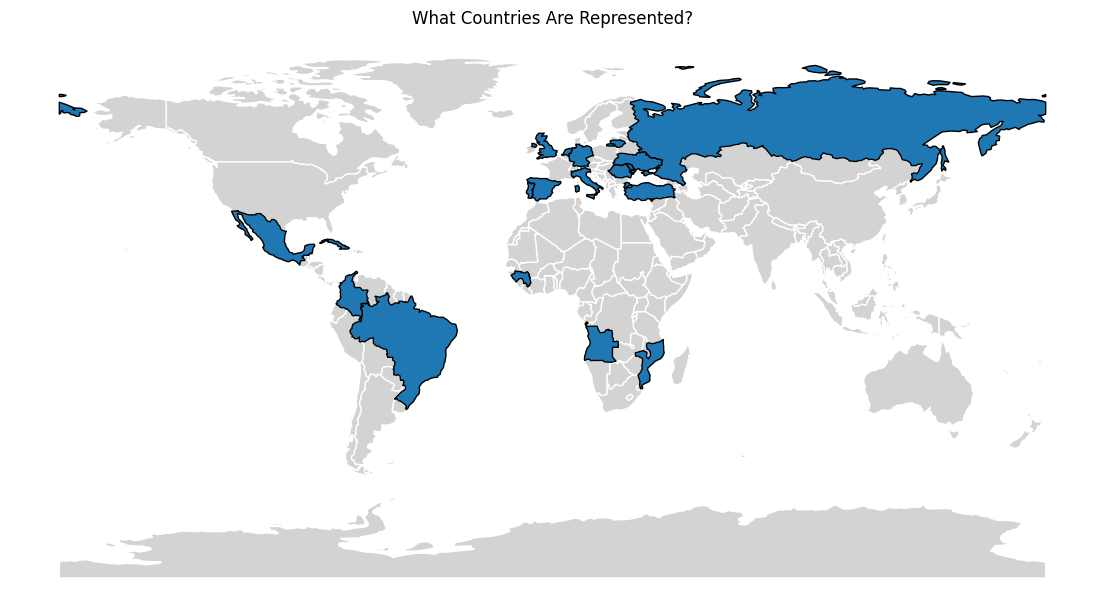

In [24]:
import geopandas as gpd

# Create a visualization of where our nationalities are from
# Load world geometry
world = gpd.read_file(
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
)


# Merge world map with nationality counts
merged = world.merge(nationalities, left_on="NAME", right_on="country", how="inner")

# Plot map
fig, ax = plt.subplots(figsize=(14, 8))
world.plot(ax=ax, color="lightgray", edgecolor="white")  # background countries
merged.plot(ax=ax, legend=True, edgecolor="black")

ax.set_axis_off()

plt.title("What Countries Are Represented?")
plt.show()

### Continuous Variable Distributions

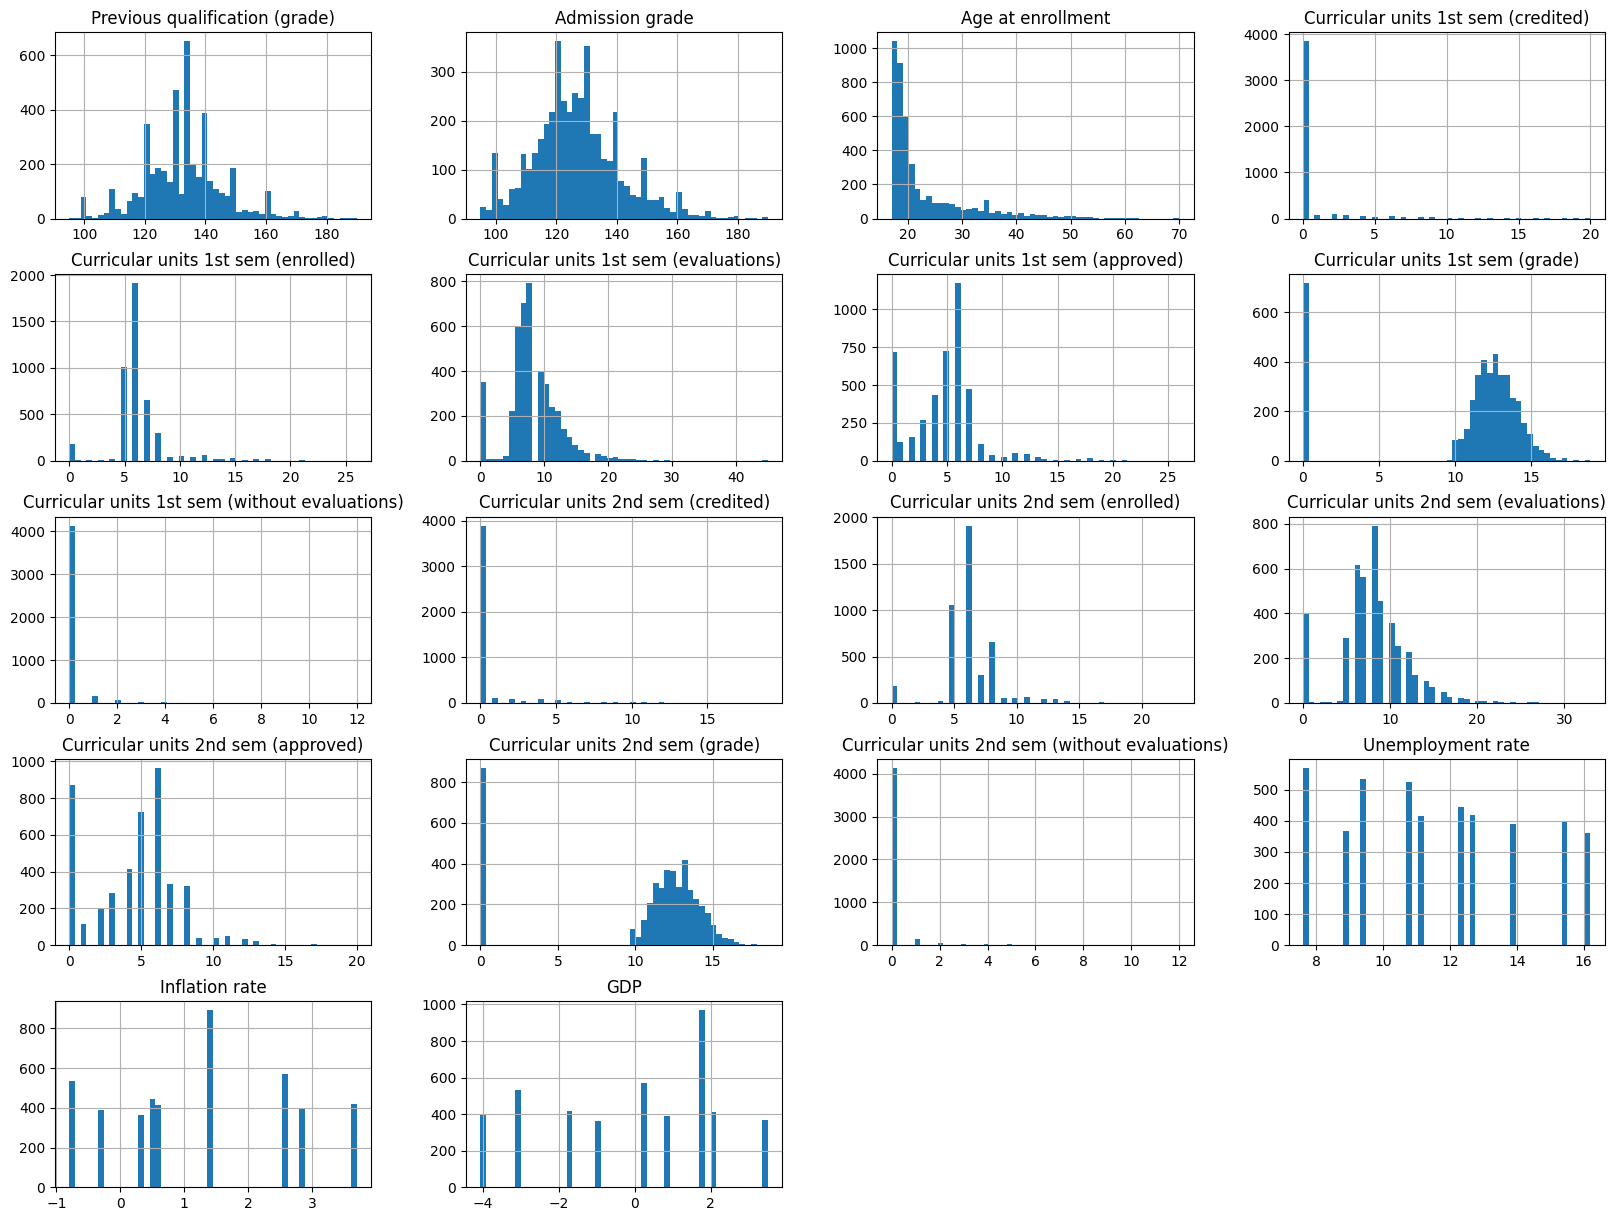

In [25]:
df.hist(figsize=(20, 15), bins=50)
plt.show()

### Check the means for the numerical columns by Target

In [26]:
round(df.groupby("Target").mean(numeric_only=True), 2)

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Target,,,,,,,,,,,,,,,,,,
Dropout,131.11,124.96,26.07,0.61,5.82,7.75,2.55,7.26,0.19,0.45,5.78,7.17,1.94,5.90,0.24,11.62,1.28,-0.15
Non-Dropout,133.32,127.93,21.94,0.76,6.48,8.56,5.73,12.24,0.11,0.59,6.45,8.48,5.62,12.28,0.11,11.54,1.20,0.07


What's interesting in comparing the means only is that we can see some thing's we'd expect and can determine intuitively like:

* A lower admission grade associated with dropping out
* Significantly lower curricular units approved and graded for dropouts than non-dropouts (for both first and second semesters)
* Negative GDP for dropouts and positive for non-dropouts along with slightly higher inflation rate and slightly higher unemployment rate for dropouts suggesting tougher economic environment


One initially unintuitive relationship is average age for dropouts is higher than the average age for non-dropouts.

## Categorical Variables

In [27]:
# Create a table that shows the number of different categories for each categorical variable
df.select_dtypes(include="object").nunique()

Marital status                   6
Application mode                18
Application order                8
Course                          17
Daytime/evening attendance\t     2
Previous qualification          17
Nacionality                     21
Mother's qualification          29
Father's qualification          29
Mother's occupation             32
Father's occupation             29
Displaced                        2
Educational special needs        2
Debtor                           2
Tuition fees up to date          2
Gender                           2
Scholarship holder               2
International                    2
Target                           2
dtype: int64

## Explore categorical variable distribution and combine categories for feature reduction.

For each of the categorical variables, we have WAY too many categories to predict on. This may lead to overfitting, having our model be too complex, or even increasing the model performance time. To deal with this, we will be reducing the number of categories to between 2-5 where possible by reviewing the proportion of the target variable for each category and combining categories with similar proportions that make sense.

For example marital status shows

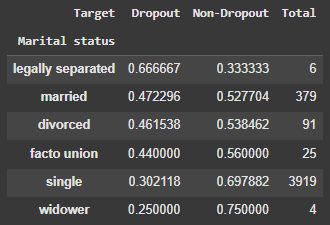

We'll choose to simplify these into 3 categories:
* legally separated
* married/divorced/facto union
* single/widower

This same principle will be applied to:
* Marital status
* Application mode
* Application order
* Course
* Nacionality
* Mother's Qualification
* Father's Qualification
* Previous Qualification
* Father's Occupation
* Mother's Occupation


### Marital Status

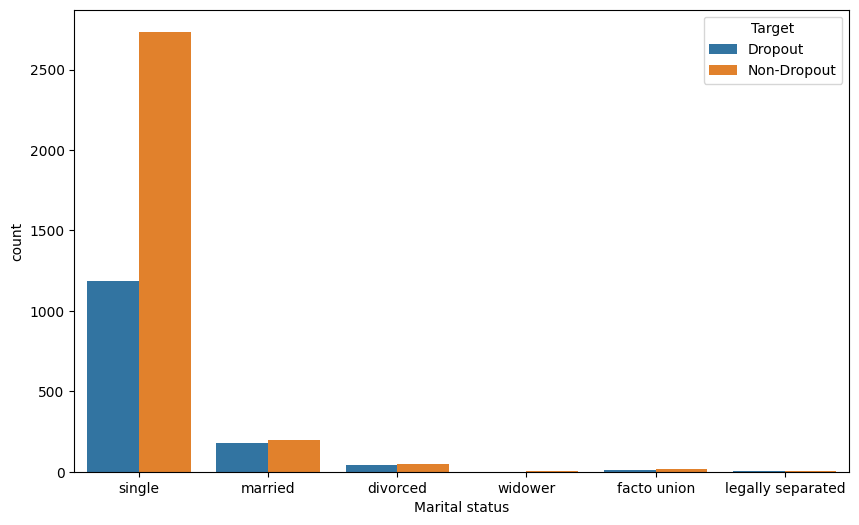

In [28]:
# Show the starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Marital status", hue="Target")

plt.show()

In [29]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Marital status"], df["Target"], normalize="index")
ct["Total"] = df["Marital status"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Marital status,,,
legally separated,0.666667,0.333333,6
married,0.472296,0.527704,379
divorced,0.461538,0.538462,91
facto union,0.440000,0.560000,25
single,0.302118,0.697882,3919
widower,0.250000,0.750000,4


In [30]:
# Create re-mapping
remap_marriage = {
    "single": "single/widower",
    "married": "divorced/facto union/married",
    "widower": "single/widower",
    "divorced": "divorced/facto union/married",
    "facto union": "divorced/facto union/married",
    "legally separated": "legally separated",
}

# Apply re-mapping
df["Marital status"] = df["Marital status"].map(remap_marriage)

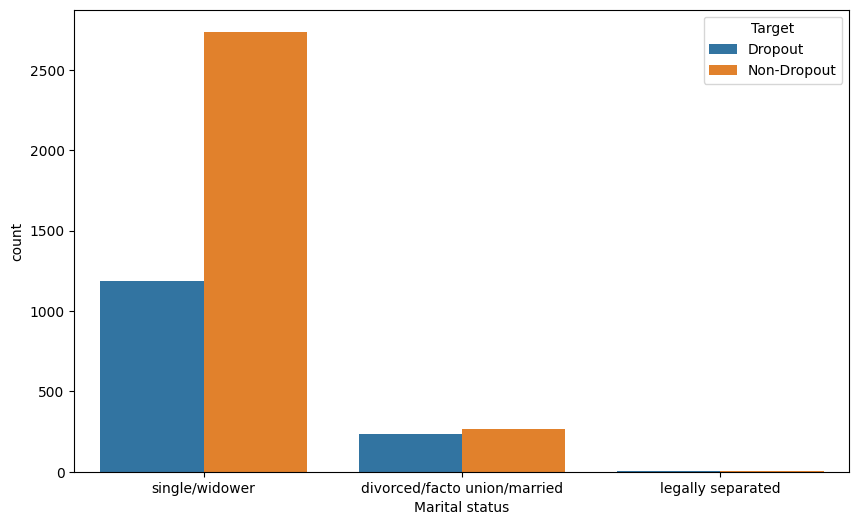

In [31]:
# Show the new distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Marital status", hue="Target")

plt.show()

### Application Mode

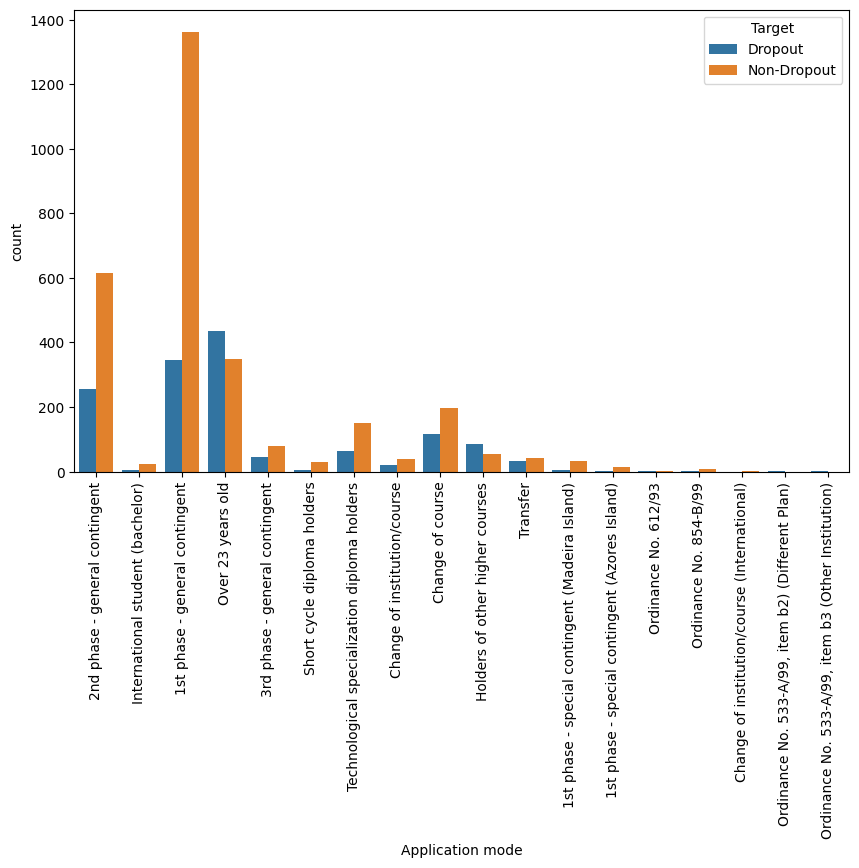

In [32]:
# Show the starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Application mode", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [33]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Application mode"], df["Target"], normalize="index")
ct["Total"] = df["Application mode"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Application mode,,,
"Ordinance No. 533-A/99, item b2) (Different Plan)",1.000000,0.000000,1
"Ordinance No. 533-A/99, item b3 (Other Institution)",1.000000,0.000000,1
Ordinance No. 612/93,0.666667,0.333333,3
Holders of other higher courses,0.611511,0.388489,139
Over 23 years old,0.554140,0.445860,785
Transfer,0.441558,0.558442,77
Change of course,0.368590,0.631410,312
3rd phase - general contingent,0.362903,0.637097,124
Change of institution/course,0.338983,0.661017,59


In [34]:
# Create remapping
remap_application_mode = {
    "Ordinance No. 533-A/99, item b2) (Different Plan)": "A",
    "Ordinance No. 533-A/99, item b3 (Other Institution)": "A",
    "Ordinance No. 612/93": "A",
    "Holders of other higher courses": "A",
    "Over 23 years old": "B",
    "Transfer": "B",
    "Change of course": "C",
    "3rd phase - general contingent": "C",
    "Change of institution/course": "C",
    "Ordinance No. 854-B/99": "D",
    "Technological specialization diploma holders": "D",
    "2nd phase - general contingent": "D",
    "1st phase - general contingent": "E",
    "International student (bachelor)": "E",
    "1st phase - special contingent (Madeira Island)": "F",
    "1st phase - special contingent (Azores Island)": "F",
    "Short cycle diploma holders": "F",
    "Change of institution/course (International)": "F",
}

# Apply remapping
df["Application mode"] = df["Application mode"].map(remap_application_mode)

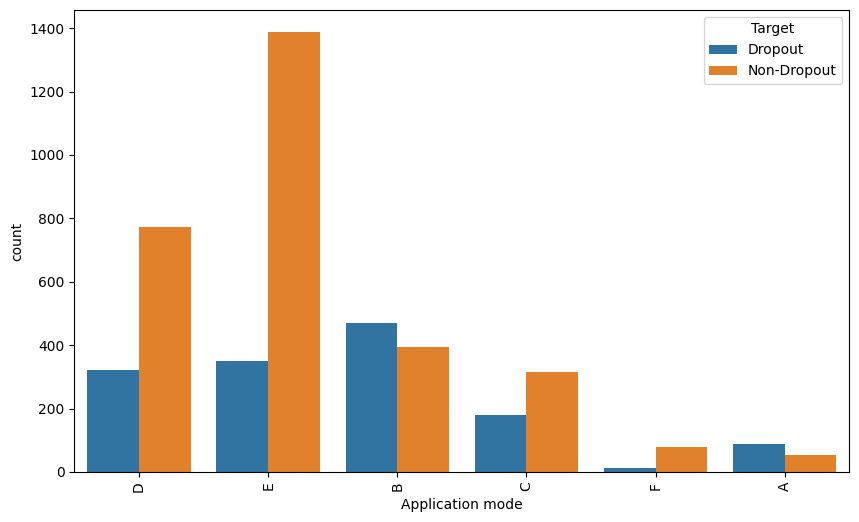

In [35]:
# Check final distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Application mode", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Application Order

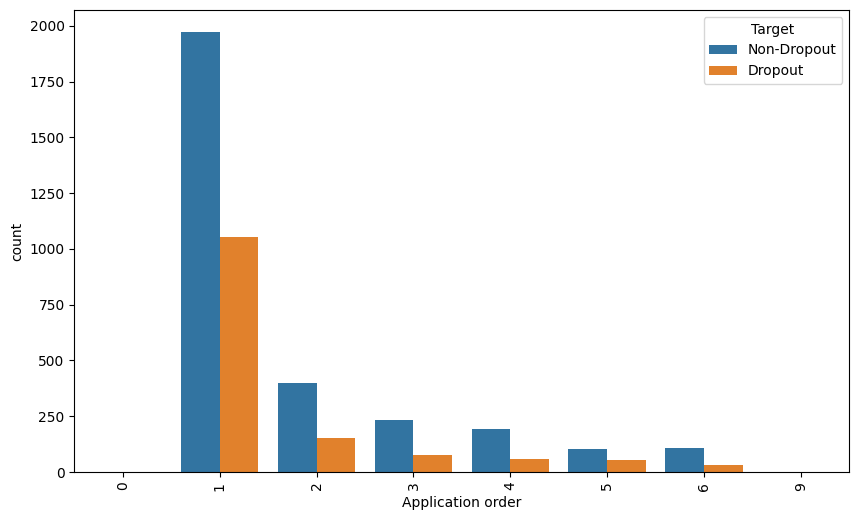

In [36]:
# Show the starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Application order", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [37]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Application order"], df["Target"], normalize="index")
ct["Total"] = df["Application order"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Application order,,,
1,0.347984,0.652016,3026
5,0.344156,0.655844,154
2,0.274223,0.725777,547
3,0.245955,0.754045,309
4,0.232932,0.767068,249
6,0.226277,0.773723,137
0,0.000000,1.000000,1
9,0.000000,1.000000,1


In [38]:
# Create remapping
remap_application_order = {
    5: "1 or 5",
    1: "1 or 5",
    2: "All others (0 - 9)",
    4: "All others (0 - 9)",
    3: "All others (0 - 9)",
    6: "All others (0 - 9)",
    9: "All others (0 - 9)",
    0: "All others (0 - 9)",
}

# Apply remapping
df["Application order"] = df["Application order"].map(remap_application_order)

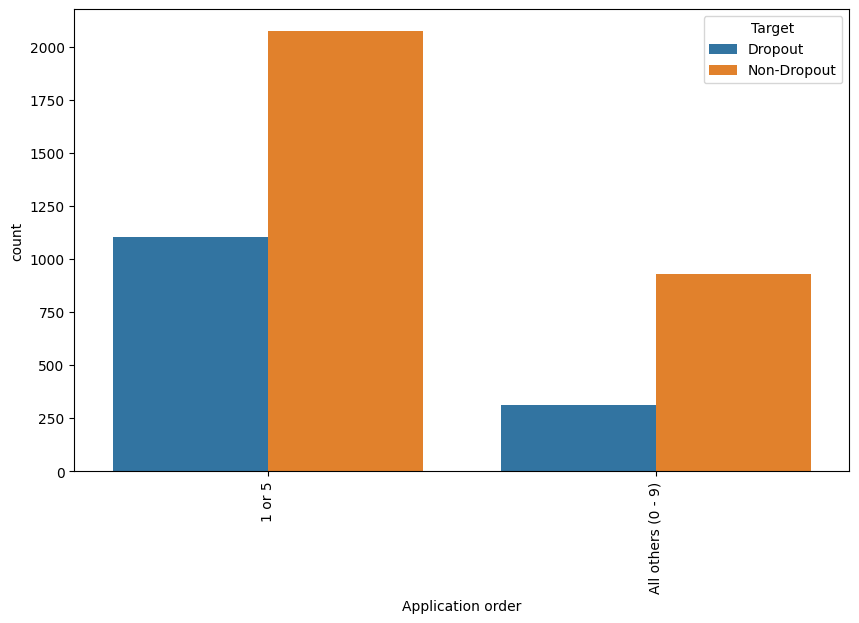

In [39]:
# Check final distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Application order", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Course

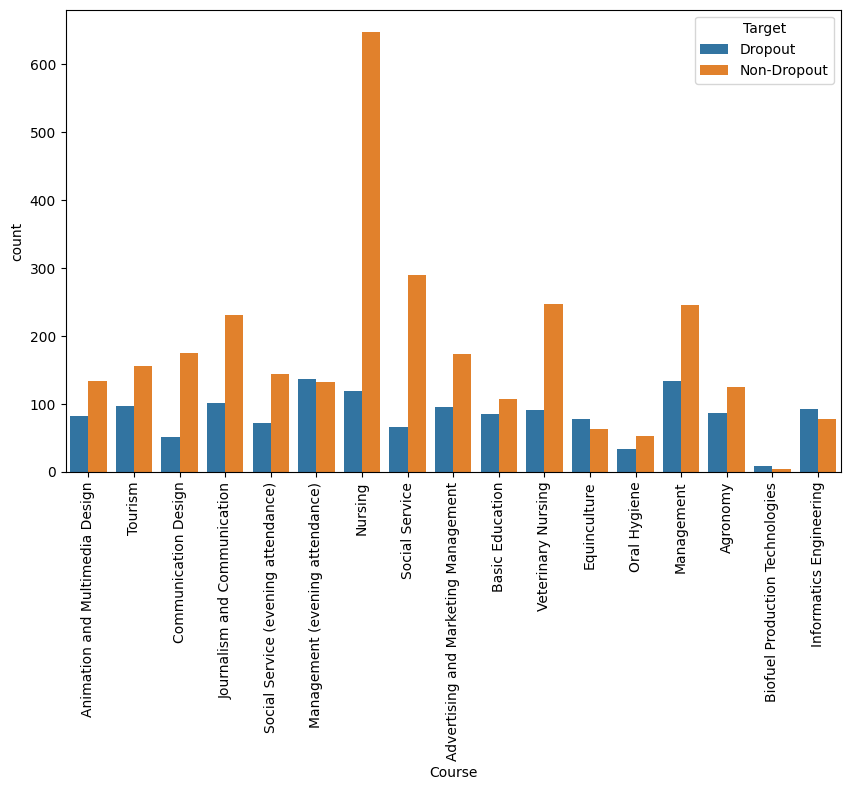

In [40]:
# Starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Course", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [41]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Course"], df["Target"], normalize="index")
ct["Total"] = df["Course"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Course,,,
Biofuel Production Technologies,0.666667,0.333333,12
Equinculture,0.553191,0.446809,141
Informatics Engineering,0.541176,0.458824,170
Management (evening attendance),0.507463,0.492537,268
Basic Education,0.442708,0.557292,192
Agronomy,0.409524,0.590476,210
Oral Hygiene,0.383721,0.616279,86
Animation and Multimedia Design,0.381395,0.618605,215
Tourism,0.380952,0.619048,252


In [42]:
# Create re-mapping
remap_course = {
    "Biofuel Production Technologies": "Biofuel, Equinculture, Informatics, Management (Evening)",
    "Equinculture": "Biofuel, Equinculture, Informatics, Management (Evening)",
    "Informatics Engineering": "Biofuel, Equinculture, Informatics, Management (Evening)",
    "Management (evening attendance)": "Biofuel, Equinculture, Informatics, Management (Evening)",
    "Basic Education": "Education, Agronomy",
    "Agronomy": "Education, Agronomy",
    "Oral Hygiene": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Animation and Multimedia Design": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Tourism": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Advertising and Marketing Management": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Management": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Social Service (evening attendance)": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Journalism and Communication": "Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",
    "Veterinary Nursing": "Vet Nursing, Communication Design, Social Service, Nursing",
    "Communication Design": "Vet Nursing, Communication Design, Social Service, Nursing",
    "Social Service": "Vet Nursing, Communication Design, Social Service, Nursing",
    "Nursing": "Vet Nursing, Communication Design, Social Service, Nursing",
}

# Apply re-mapping
df["Course"] = df["Course"].map(remap_course)

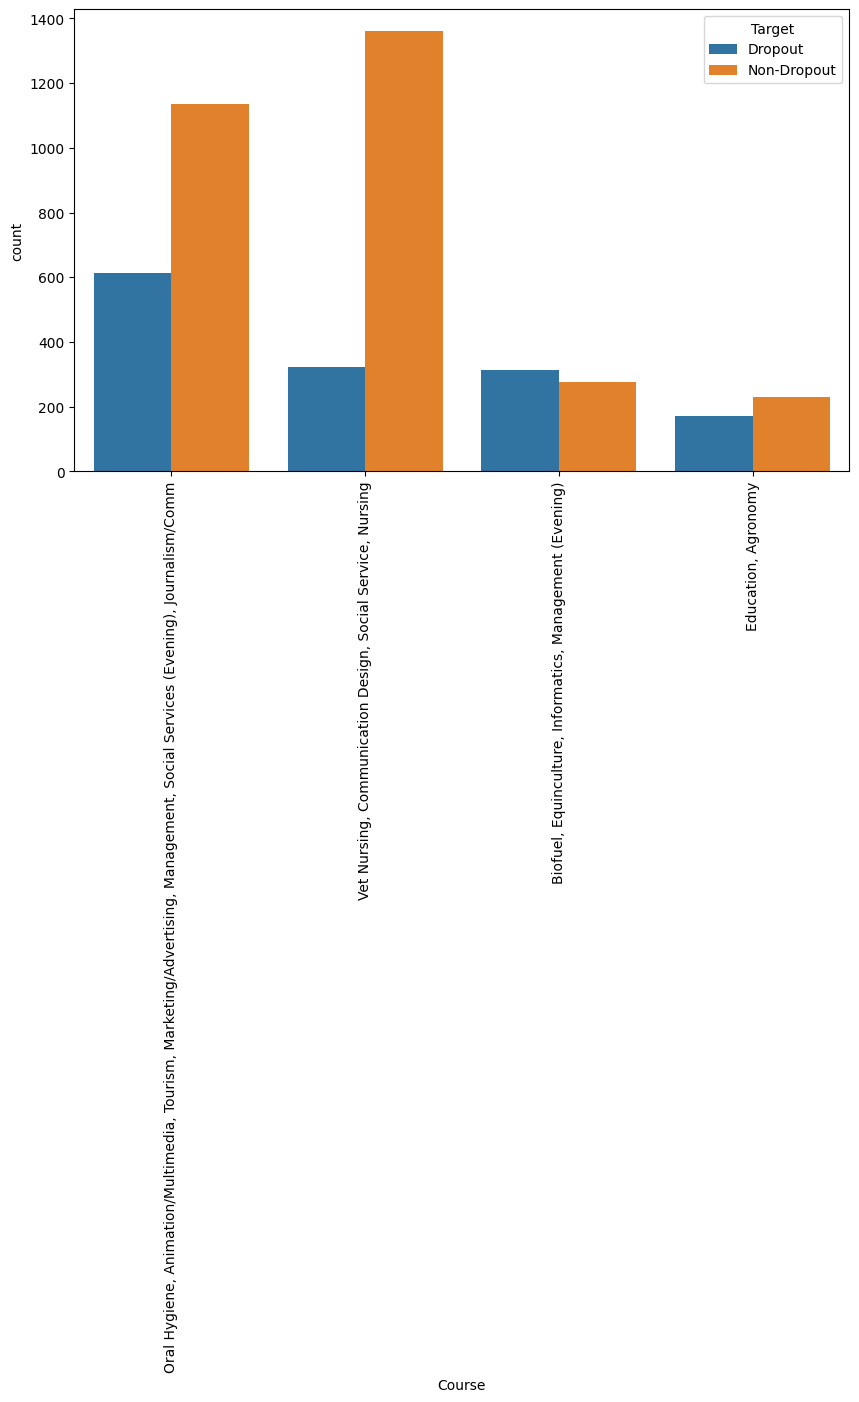

In [43]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Course", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Nationality

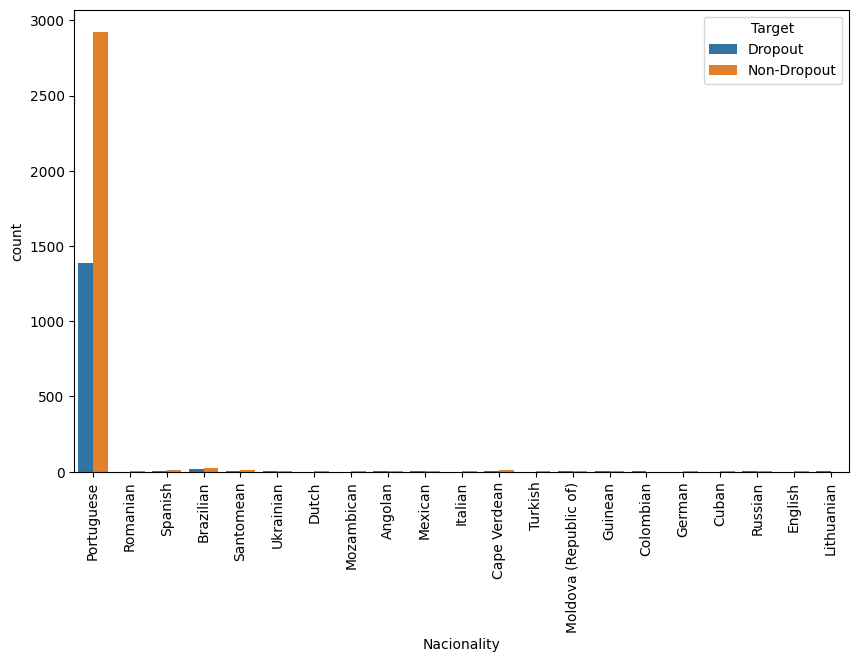

In [44]:
# Check distribution beforehand
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Nacionality", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [45]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Nacionality"], df["Target"], normalize="index")
ct["Total"] = df["Nacionality"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Nacionality,,,
Colombian,1.000000,0.000000,1
Lithuanian,1.000000,0.000000,1
Moldova (Republic of),0.666667,0.333333,3
Angolan,0.500000,0.500000,2
Mexican,0.500000,0.500000,2
Russian,0.500000,0.500000,2
Brazilian,0.368421,0.631579,38
Ukrainian,0.333333,0.666667,3
Portuguese,0.321975,0.678025,4314


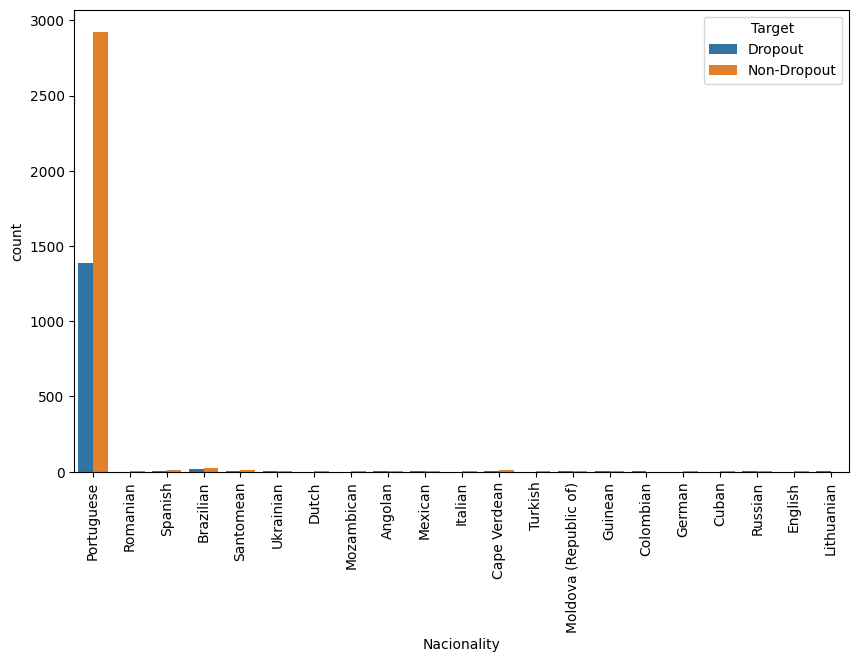

In [46]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Nacionality", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [47]:
df["Nacionality"].value_counts()

Nacionality
Portuguese               4314
Brazilian                  38
Santomean                  14
Spanish                    13
Cape Verdean               13
Guinean                     5
Moldova (Republic of)       3
Italian                     3
Ukrainian                   3
Romanian                    2
Angolan                     2
Mexican                     2
Mozambican                  2
German                      2
Russian                     2
Turkish                     1
Dutch                       1
Colombian                   1
Cuban                       1
English                     1
Lithuanian                  1
Name: count, dtype: int64

#### Note

This column started off really imbalanced with a majority of our datapoints being Portugese. Combining nationalities didn't help anything, so it may be best to drop this column. It makes sense because this dataset is taken from a Portugese country rather than being spread throughout the world. We'll revisit this later.

Originally nationalities were combined on similar target relationships, but due to suggestions, felt it was better to show Portugese vs. Non-Portugese. The previous code was removed to clean up the notebook.

In [48]:
# Create remapping
remap_nacionality = {
    "Colombian": "Non-Portuguese",
    "Lithuanian": "Non-Portuguese",
    "Moldova (Republic of)": "Non-Portuguese",
    "Angolan": "Non-Portuguese",
    "Mexican": "Non-Portuguese",
    "Russian": "Non-Portuguese",
    "Brazilian": "Non-Portuguese",
    "Ukrainian": "Non-Portuguese",
    "Portuguese": "Portuguese",
    "Spanish": "Non-Portuguese",
    "Cape Verdean": "Non-Portuguese",
    "Guinean": "Non-Portuguese",
    "Santomean": "Non-Portuguese",
    "Cuban": "Non-Portuguese",
    "Dutch": "Non-Portuguese",
    "English": "Non-Portuguese",
    "German": "Non-Portuguese",
    "Italian": "Non-Portuguese",
    "Mozambican": "Non-Portuguese",
    "Romanian": "Non-Portuguese",
    "Turkish": "Non-Portuguese",
}

# Apply remapping
df["Nacionality"] = df["Nacionality"].map(remap_nacionality)

In [49]:
df["Nacionality"].value_counts(dropna=False)

Nacionality
Portuguese        4314
Non-Portuguese     110
Name: count, dtype: int64

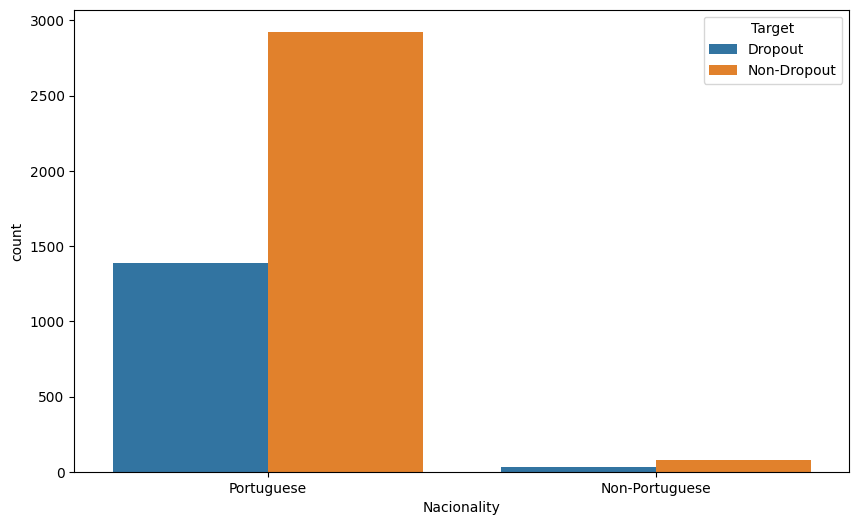

In [50]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Nacionality", hue="Target")
plt.xticks(rotation=0)
plt.show()

### Mother's qualification

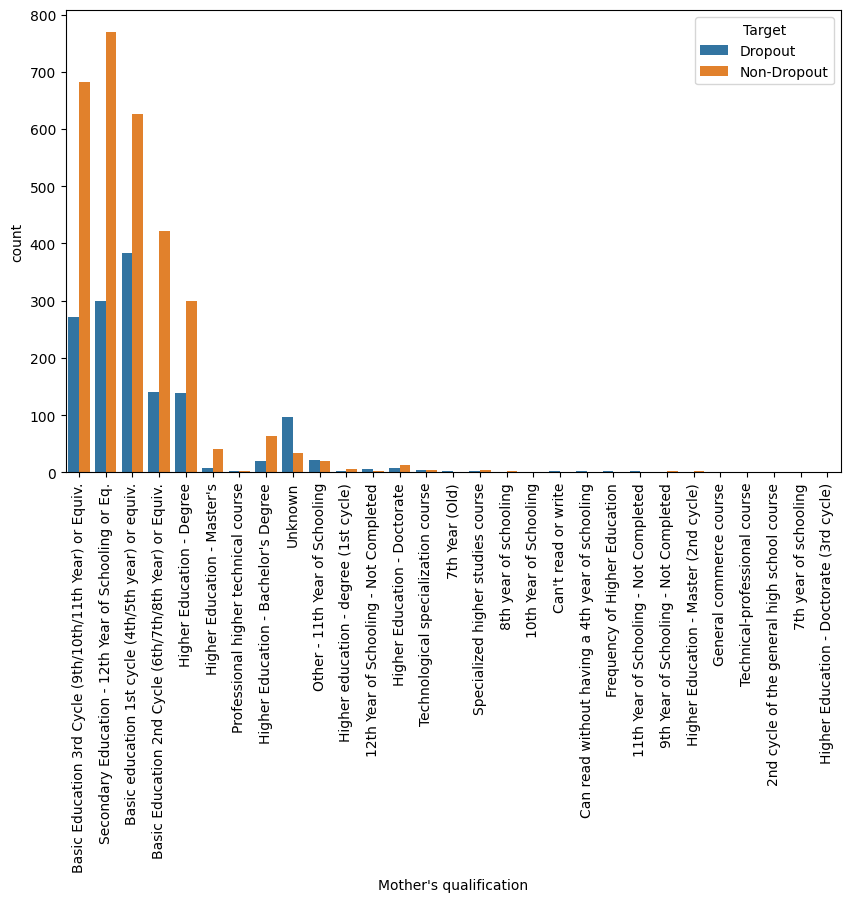

In [51]:
# Plot the distribution beforehand
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Mother's qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [52]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Mother's qualification"], df["Target"], normalize="index")
ct["Total"] = df["Mother's qualification"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Mother's qualification,,,
2nd cycle of the general high school course,1.000000,0.000000,1
Higher Education - Doctorate (3rd cycle),1.000000,0.000000,1
General commerce course,1.000000,0.000000,1
Frequency of Higher Education,0.750000,0.250000,4
Unknown,0.738462,0.261538,130
7th Year (Old),0.666667,0.333333,3
11th Year of Schooling - Not Completed,0.666667,0.333333,3
Can't read or write,0.666667,0.333333,3
Can read without having a 4th year of schooling,0.666667,0.333333,3


In [53]:
# Create re-mapping
remap_mother_qualification = {
    "2nd cycle of the general high school course": "A",
    "Higher Education - Doctorate (3rd cycle)": "A",
    "General commerce course": "A",
    "Frequency of Higher Education": "A",
    "Unknown": "A",
    "7th Year (Old)": "B",
    "11th Year of Schooling - Not Completed": "B",
    "Can't read or write": "B",
    "Can read without having a 4th year of schooling": "B",
    "12th Year of Schooling - Not Completed": "B",
    "Other - 11th Year of Schooling": "C",
    "Technological specialization course": "C",
    "10th Year of Schooling": "C",
    "Professional higher technical course": "C",
    "Higher Education - Doctorate": "D",
    "asic education 1st cycle (4th/5th year) or equiv.": "D",
    "Specialized higher studies course": "D",
    "8th year of schooling": "D",
    "Higher education - degree (1st cycle)": "D",
    "9th Year of Schooling - Not Completed": "D",
    "Higher Education - Degree": "D",
    "Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv.": "E",
    "Secondary Education - 12th Year of Schooling or Eq.": "E",
    "Higher Education - Master (2nd cycle)": "E",
    "Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv.": "E",
    "Higher Education - Bachelor's Degree": "F",
    "Higher Education - Master's": "F",
    "7th year of schooling": "F",
    "Technical-professional course": "F",
}

# Apply remapping
df["Mother's qualification"] = df["Mother's qualification"].map(
    remap_mother_qualification
)

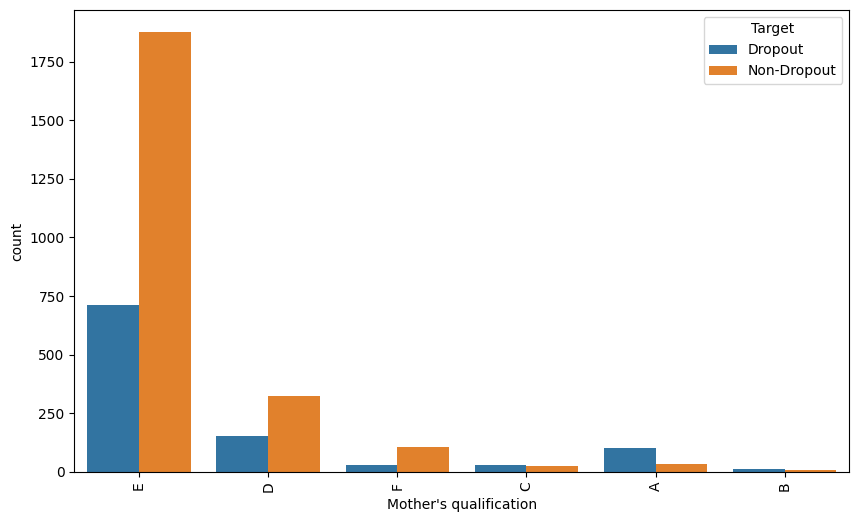

In [54]:
# Check final distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Mother's qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Father's qualification

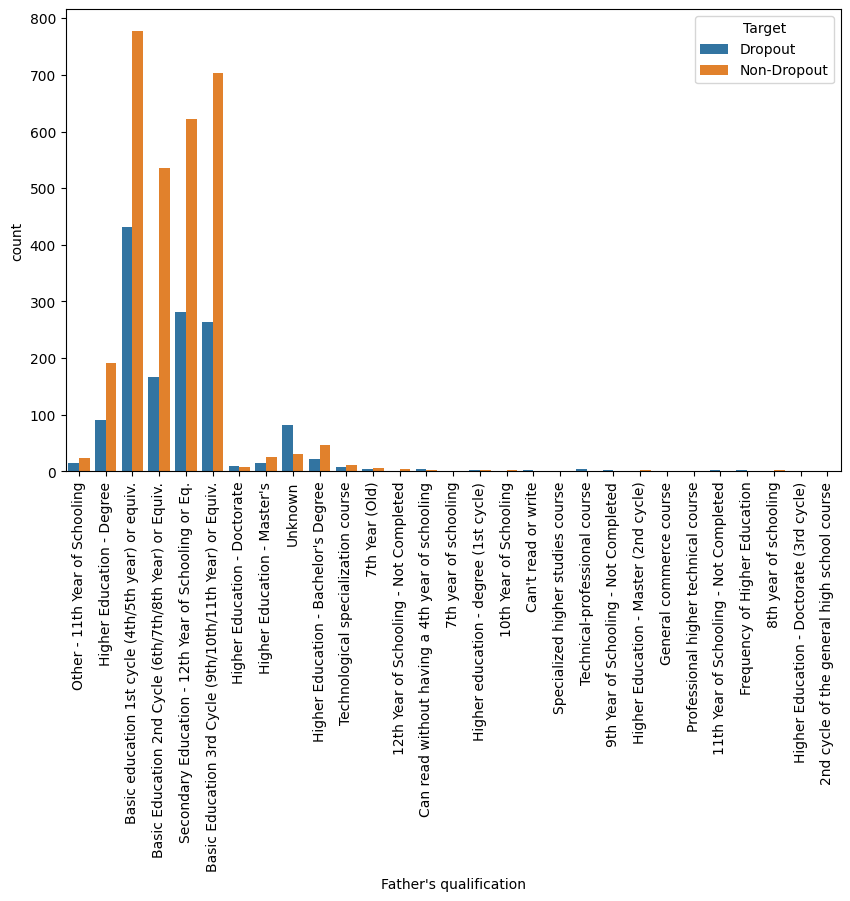

In [55]:
# Starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Father's qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [56]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Father's qualification"], df["Target"], normalize="index")
ct["Total"] = df["Father's qualification"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Father's qualification,,,
11th Year of Schooling - Not Completed,1.000000,0.000000,2
2nd cycle of the general high school course,1.000000,0.000000,1
9th Year of Schooling - Not Completed,1.000000,0.000000,3
Can't read or write,1.000000,0.000000,2
Frequency of Higher Education,1.000000,0.000000,2
Technical-professional course,1.000000,0.000000,4
Higher Education - Doctorate (3rd cycle),1.000000,0.000000,1
General commerce course,1.000000,0.000000,1
Unknown,0.723214,0.276786,112


In [57]:
# Create remapping
remap_fathers_qualification = {
    "11th Year of Schooling - Not Completed": "A",
    "2nd cycle of the general high school course": "A",
    "9th Year of Schooling - Not Completed": "A",
    "Can't read or write": "A",
    "Frequency of Higher Education": "A",
    "Technical-professional course": "A",
    "Higher Education - Doctorate (3rd cycle)": "A",
    "General commerce course": "A",
    "Unknown": "A",
    "Can read without having a 4th year of schooling": "B",
    "Higher education - degree (1st cycle)": "B",
    "Higher Education - Doctorate": "B",
    "7th year of schooling": "B",
    "Specialized higher studies course": "B",
    "Technological specialization course": "C",
    "7th Year (Old)": "C",
    "Other - 11th Year of Schooling": "C",
    "Higher Education - Master's": "C",
    "Basic education 1st cycle (4th/5th year) or equiv.": "C",
    "Higher Education - Bachelor's Degree": "C",
    "Higher Education - Degree": "C",
    "Secondary Education - 12th Year of Schooling or Eq.": "C",
    "Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv.": "D",
    "10th Year of Schooling": "D",
    "8th year of schooling": "D",
    "Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv.": "D",
    "12th Year of Schooling - Not Completed": "D",
    "Higher Education - Master (2nd cycle)": "D",
    "Professional higher technical course": "D",
}

# Apply remapping
df["Father's qualification"] = df["Father's qualification"].map(
    remap_fathers_qualification
)

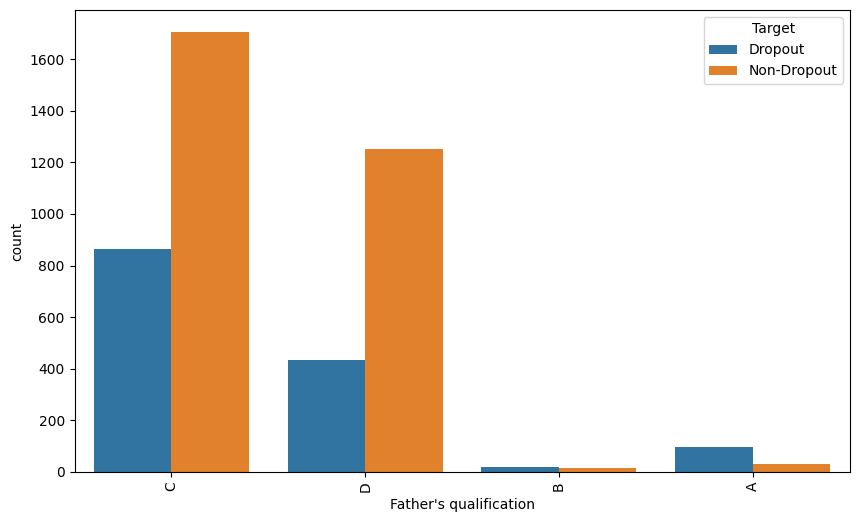

In [58]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Father's qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [59]:
# Check value counts
df["Father's qualification"].value_counts()

Father's qualification
C    2570
D    1686
A     128
B      35
Name: count, dtype: int64

### Previous Qualification

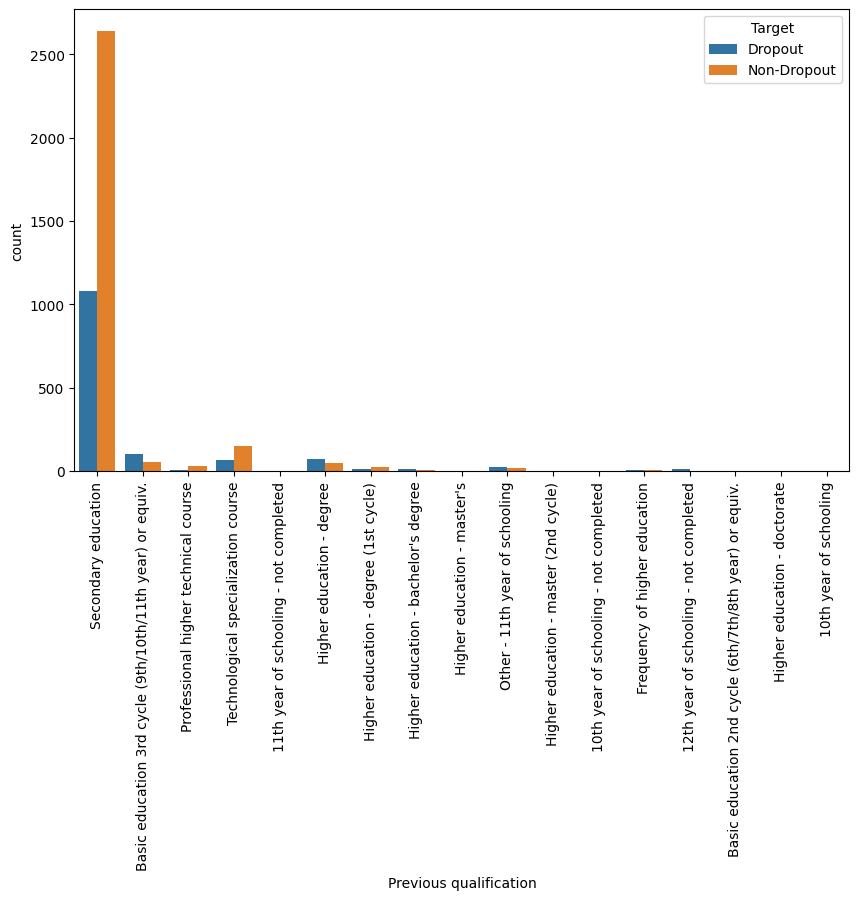

In [60]:
# Check starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Previous qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [61]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Previous qualification"], df["Target"], normalize="index")
ct["Total"] = df["Previous qualification"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Previous qualification,,,
10th year of schooling,1.000000,0.000000,1
12th year of schooling - not completed,1.000000,0.000000,11
Higher education - doctorate,1.000000,0.000000,1
11th year of schooling - not completed,0.750000,0.250000,4
Higher education - bachelor's degree,0.695652,0.304348,23
Basic education 3rd cycle (9th/10th/11th year) or equiv.,0.641975,0.358025,162
Higher education - degree,0.595238,0.404762,126
Other - 11th year of schooling,0.577778,0.422222,45
10th year of schooling - not completed,0.500000,0.500000,2


In [62]:
# Create remapping
remap_previous_qualification = {
    "10th year of schooling": "A",
    "12th year of schooling - not completed": "A",
    "Higher education - doctorate": "A",
    "11th year of schooling - not completed": "A",
    "Higher education - bachelor's degree": "A",
    "Basic education 3rd cycle (9th/10th/11th year) or equiv.": "A",
    "Higher education - degree": "B",
    "Other - 11th year of schooling": "B",
    "10th year of schooling - not completed": "B",
    "Higher education - master's": "B",
    "Frequency of higher education": "B",
    "Basic education 2nd cycle (6th/7th/8th year) or equiv.": "B",
    "Higher education - degree (1st cycle)": "C",
    "Higher education - master (2nd cycle)": "C",
    "Technological specialization course": "C",
    "Secondary education": "C",
    "Professional higher technical course": "C",
}

# Apply remapping
df["Previous qualification"] = df["Previous qualification"].map(
    remap_previous_qualification
)

In [63]:
df["Previous qualification"].value_counts()

Previous qualification
C    4018
B     204
A     202
Name: count, dtype: int64

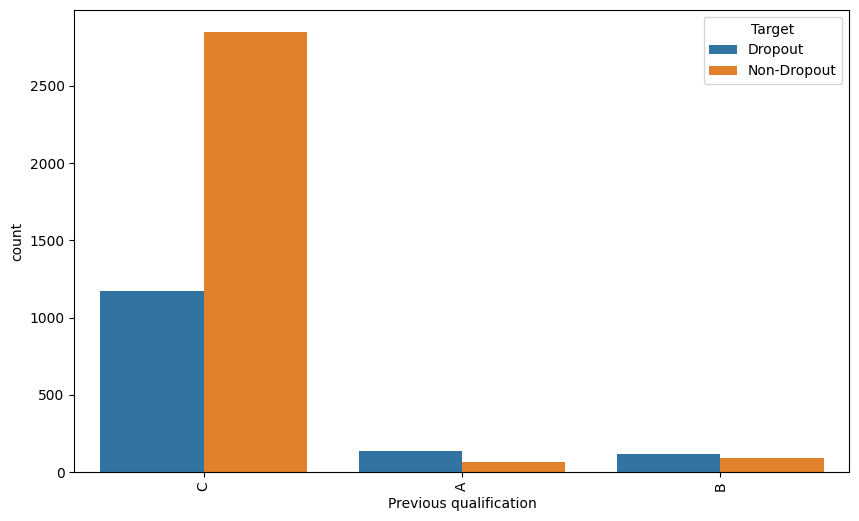

In [64]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Previous qualification", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Father's Occupation

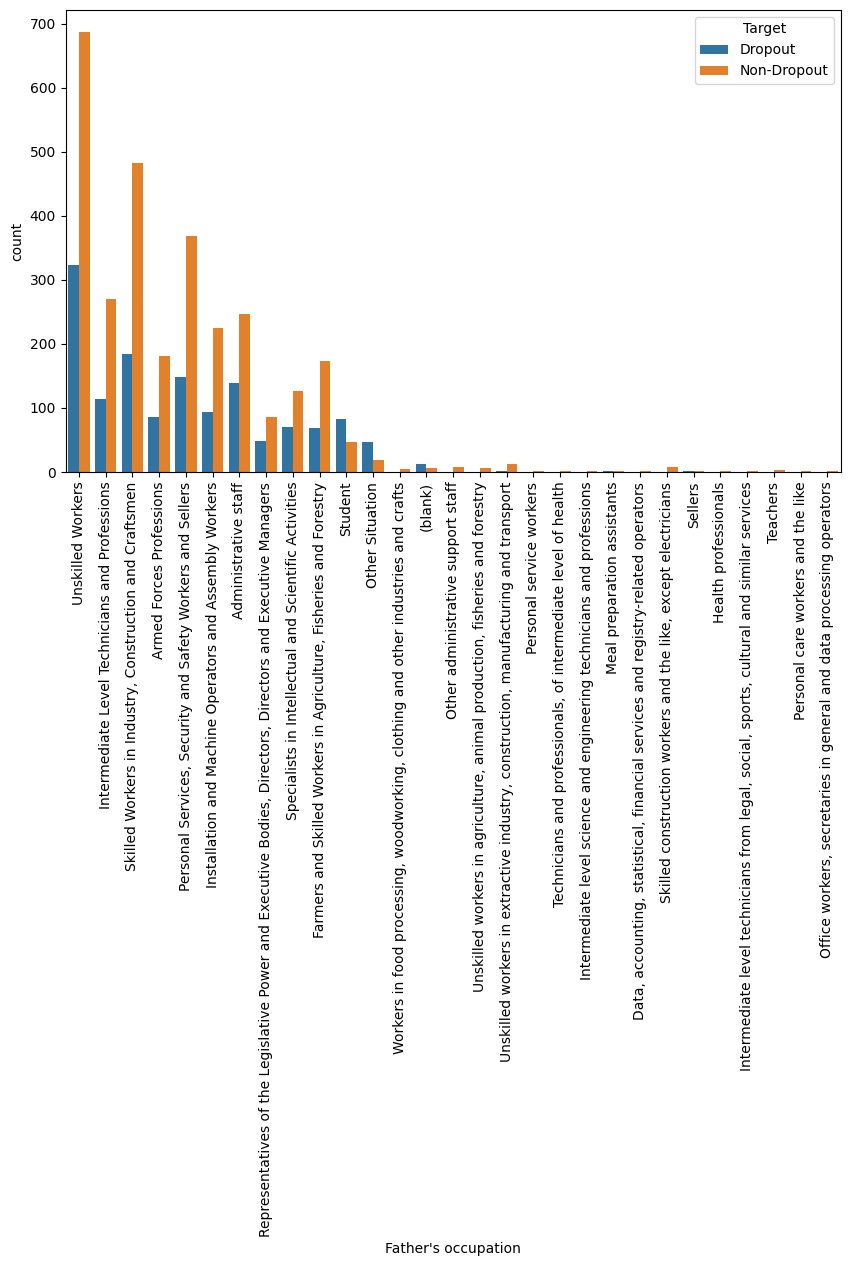

In [65]:
# Starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Father's occupation", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [66]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Father's occupation"], df["Target"], normalize="index")
ct["Total"] = df["Father's occupation"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Father's occupation,,,
Other Situation,0.707692,0.292308,65
(blank),0.684211,0.315789,19
Student,0.640625,0.359375,128
Meal preparation assistants,0.500000,0.500000,2
Administrative staff,0.360104,0.639896,386
"Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers",0.358209,0.641791,134
Specialists in Intellectual and Scientific Activities,0.355330,0.644670,197
Sellers,0.333333,0.666667,3
Unskilled Workers,0.319802,0.680198,1010


In [67]:
# Create remapping
remap_fathers_occupation = {
    "Other Situation": "A",
    "(blank)": "A",
    "Student": "A",
    "Meal preparation assistants": "A",
    "Administrative staff": "B",
    "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers": "B",
    "Specialists in Intellectual and Scientific Activities": "B",
    "Sellers": "B",
    "Unskilled Workers": "B",
    "Armed Forces Professions": "B",
    "Intermediate Level Technicians and Professions": "B",
    "Installation and Machine Operators and Assembly Workers": "B",
    "Personal Services, Security and Safety Workers and Sellers": "B",
    "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry": "B",
    "Skilled Workers in Industry, Construction and Craftsmen": "B",
    "Unskilled workers in extractive industry, construction, manufacturing and transport": "C",
    "Office workers, secretaries in general and data processing operators": "C",
    "Data, accounting, statistical, financial services and registry-related operators": "C",
    "Intermediate level technicians from legal, social, sports, cultural and similar services": "C",
    "Health professionals": "C",
    "Intermediate level science and engineering technicians and professions": "C",
    "Skilled construction workers and the like, except electricians": "C",
    "Other administrative support staff": "C",
    "Personal care workers and the like": "C",
    "Personal service workers": "C",
    "Technicians and professionals, of intermediate level of health": "C",
    "Teachers": "C",
    "Unskilled workers in agriculture, animal production, fisheries and forestry": "C",
    "Workers in food processing, woodworking, clothing and other industries and crafts": "C",
}

# Apply remapping
df["Father's occupation"] = df["Father's occupation"].map(remap_fathers_occupation)

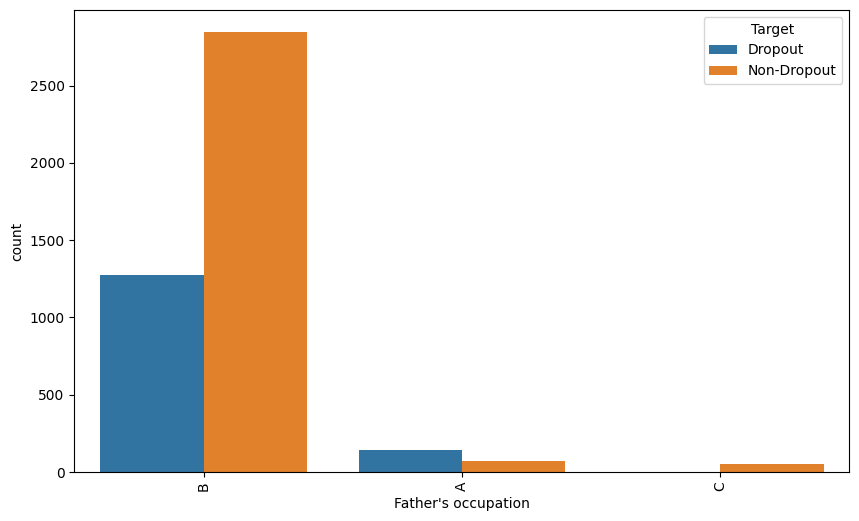

In [68]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Father's occupation", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [69]:
# Check value counts
df["Father's occupation"].value_counts()

Father's occupation
B    4122
A     214
C      54
Name: count, dtype: int64

### Mother's Occupation

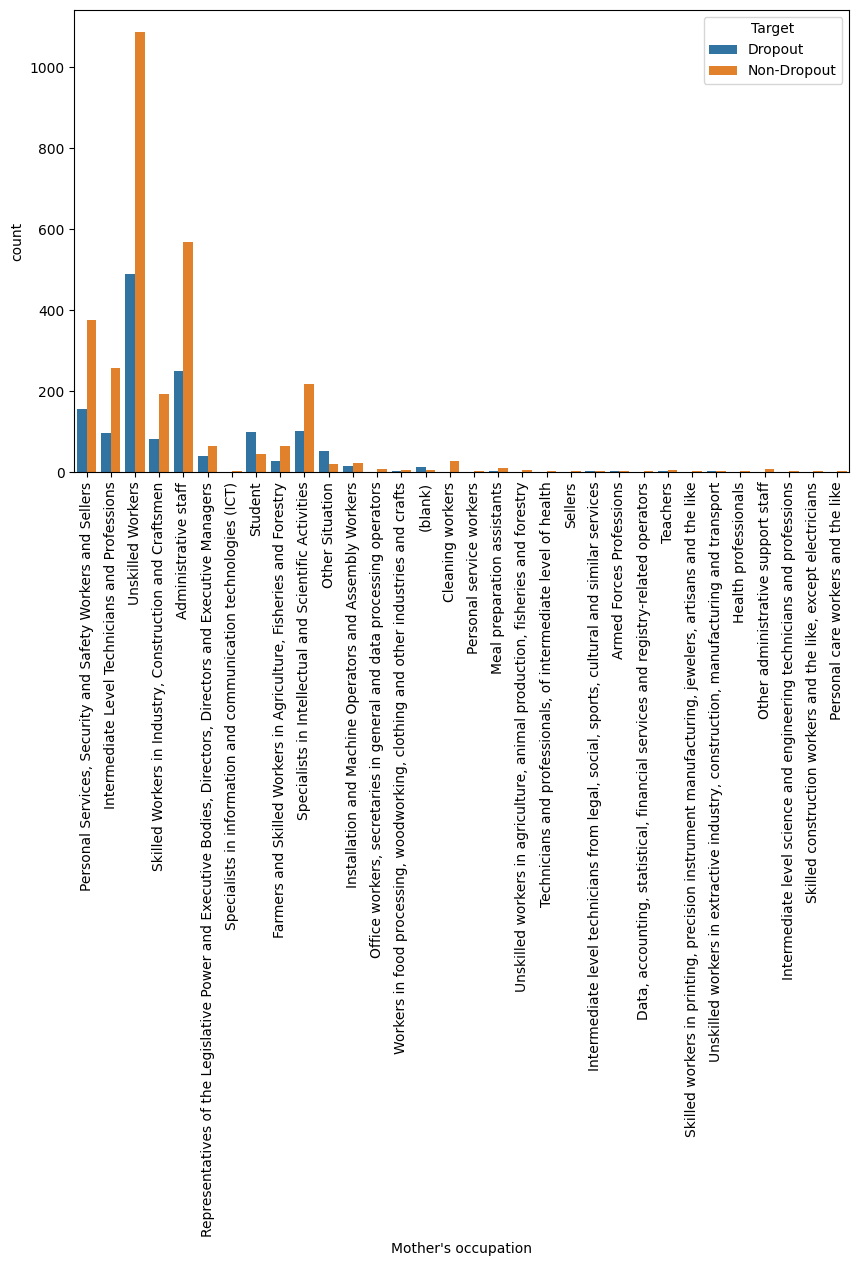

In [70]:
# Starting distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Mother's occupation", hue="Target")

plt.xticks(rotation=90)

plt.show()

In [71]:
# Create a table to show the proportion of the target for the column and corresponding counts
ct = pd.crosstab(df["Mother's occupation"], df["Target"], normalize="index")
ct["Total"] = df["Mother's occupation"].value_counts()
ct = ct.sort_values(by="Dropout", ascending=False)
ct

Target,Dropout,Non-Dropout,Total
Mother's occupation,,,
(blank),0.764706,0.235294,17
Other Situation,0.728571,0.271429,70
Student,0.687500,0.312500,144
Installation and Machine Operators and Assembly Workers,0.416667,0.583333,36
"Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers",0.382353,0.617647,102
Specialists in Intellectual and Scientific Activities,0.320755,0.679245,318
Unskilled Workers,0.310717,0.689283,1577
Administrative staff,0.303550,0.696450,817
"Personal Services, Security and Safety Workers and Sellers",0.294340,0.705660,530


In [72]:
# Remap
remap_mothers_occupation = {
    "(blank)": "A",
    "Other Situation": "A",
    "Student": "A",
    "Installation and Machine Operators and Assembly Workers": "A",
    "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers": "B",
    "Specialists in Intellectual and Scientific Activities": "B",
    "Unskilled Workers": "B",
    "Administrative staff": "B",
    "Personal Services, Security and Safety Workers and Sellers": "C",
    "Skilled Workers in Industry, Construction and Craftsmen": "C",
    "Teachers": "C",
    "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry": "C",
    "Intermediate Level Technicians and Professions": "C",
    "Unskilled workers in extractive industry, construction, manufacturing and transport": "C",
    "Intermediate level technicians from legal, social, sports, cultural and similar services": "C",
    "Armed Forces Professions": "C",
    "Workers in food processing, woodworking, clothing and other industries and crafts": "C",
    "Meal preparation assistants": "D",
    "Other administrative support staff": "D",
    "Office workers, secretaries in general and data processing operators": "D",
    "Data, accounting, statistical, financial services and registry-related operators": "D",
    "Cleaning workers": "D",
    "Intermediate level science and engineering technicians and professions": "D",
    "Health professionals": "D",
    "Skilled workers in printing, precision instrument manufacturing, jewelers, artisans and the like": "D",
    "Skilled construction workers and the like, except electricians": "D",
    "Personal service workers": "D",
    "Sellers": "D",
    "Personal care workers and the like": "D",
    "Specialists in information and communication technologies (ICT)": "D",
    "Technicians and professionals, of intermediate level of health": "D",
    "Unskilled workers in agriculture, animal production, fisheries and forestry": "D",
}

# Apply
df["Mother's occupation"] = df["Mother's occupation"].map(remap_mothers_occupation)

In [73]:
# Check value counts
df["Mother's occupation"].value_counts()

Mother's occupation
B    2814
C    1268
A     267
D      75
Name: count, dtype: int64

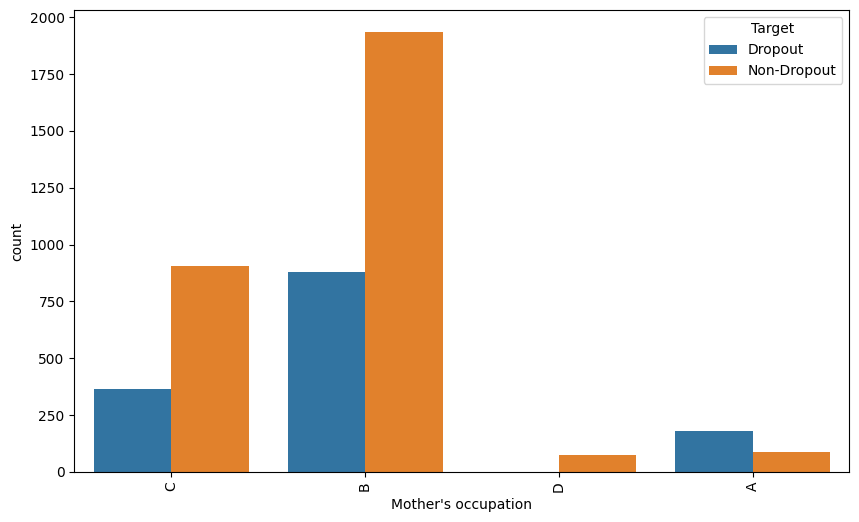

In [74]:
# Final distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Mother's occupation", hue="Target")

plt.xticks(rotation=90)

plt.show()

### Displaced

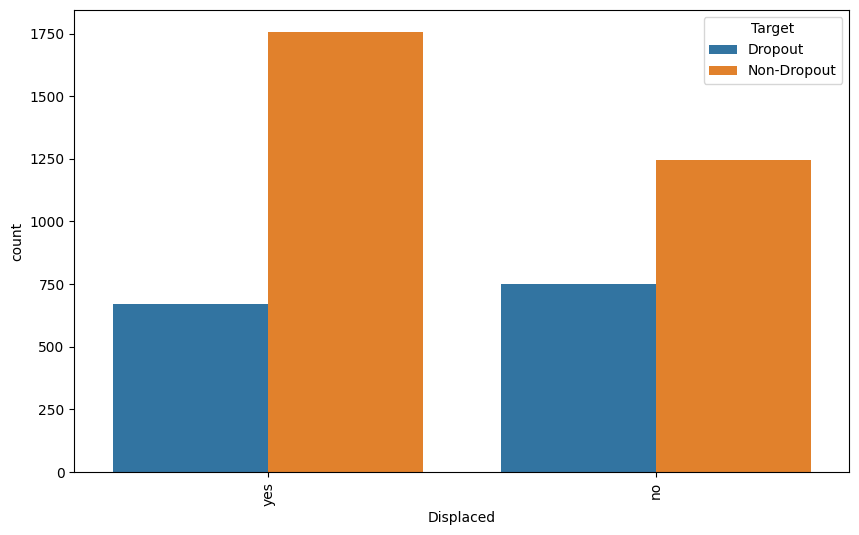

In [75]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Displaced", hue="Target")

plt.xticks(rotation=90)

plt.show()

No modifications necessary

### Educational Special Needs

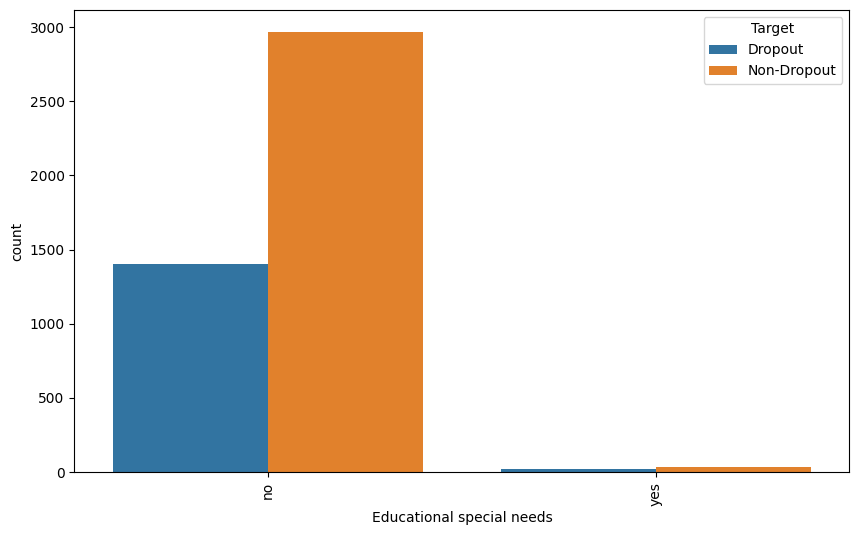

In [76]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Educational special needs", hue="Target")

plt.xticks(rotation=90)

plt.show()

No modification necessary

### Debtor

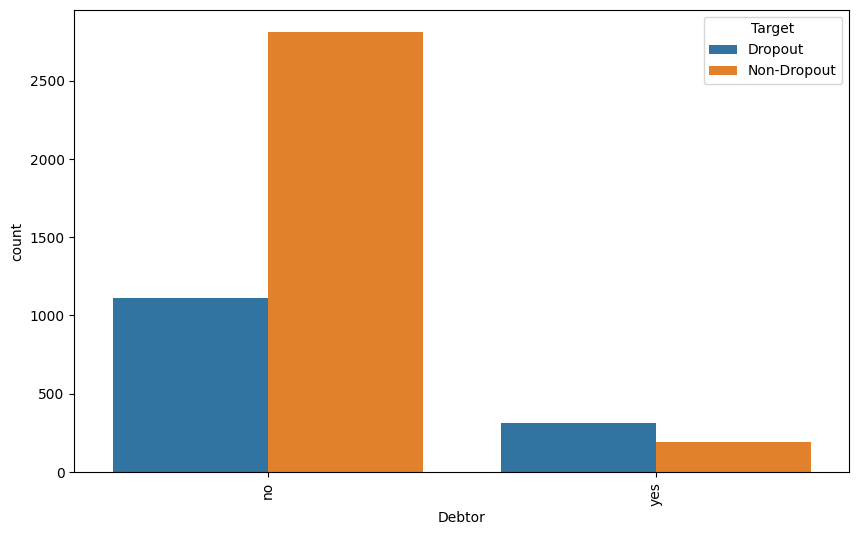

In [77]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Debtor", hue="Target")

plt.xticks(rotation=90)

plt.show()

No modification necessary

### Tuition Fees Up To Date

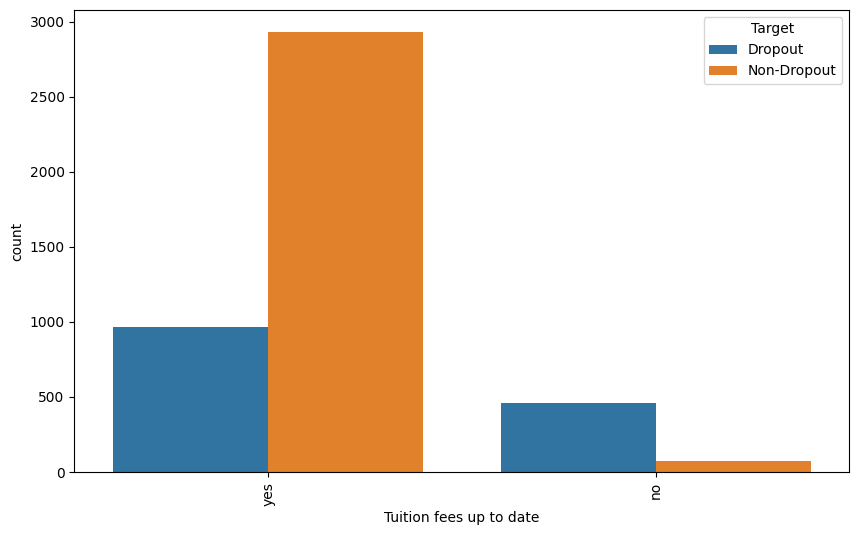

In [78]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Tuition fees up to date", hue="Target")

plt.xticks(rotation=90)

plt.show()

No need to update

### Gender

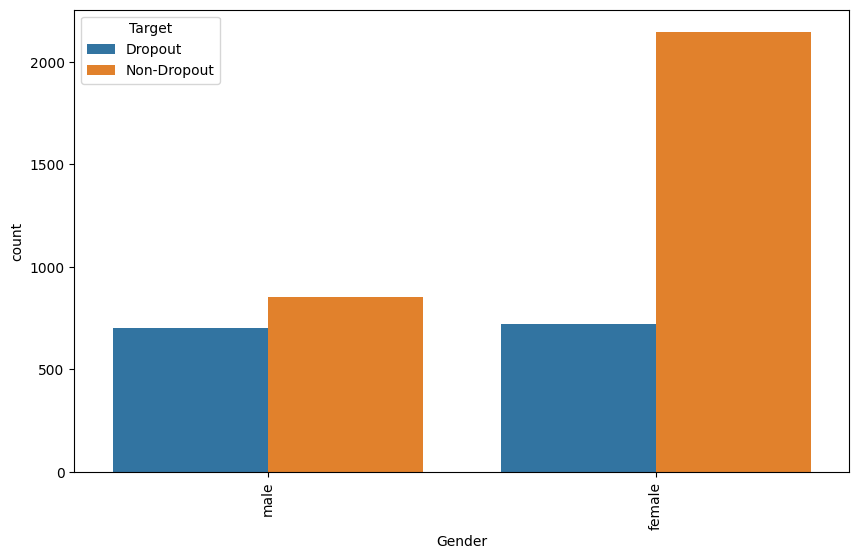

In [79]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Gender", hue="Target")

plt.xticks(rotation=90)

plt.show()

No need to update

### Scholarship holder

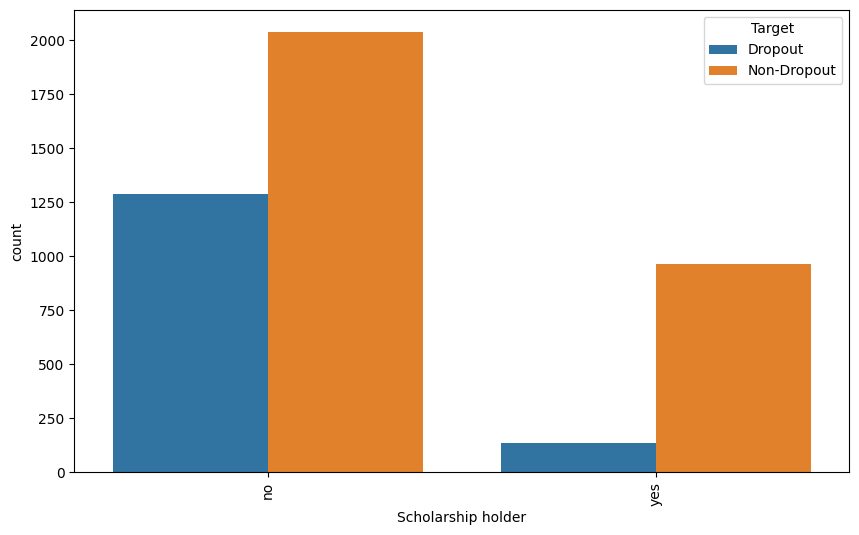

In [80]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Scholarship holder", hue="Target")

plt.xticks(rotation=90)

plt.show()

No need to update

### International

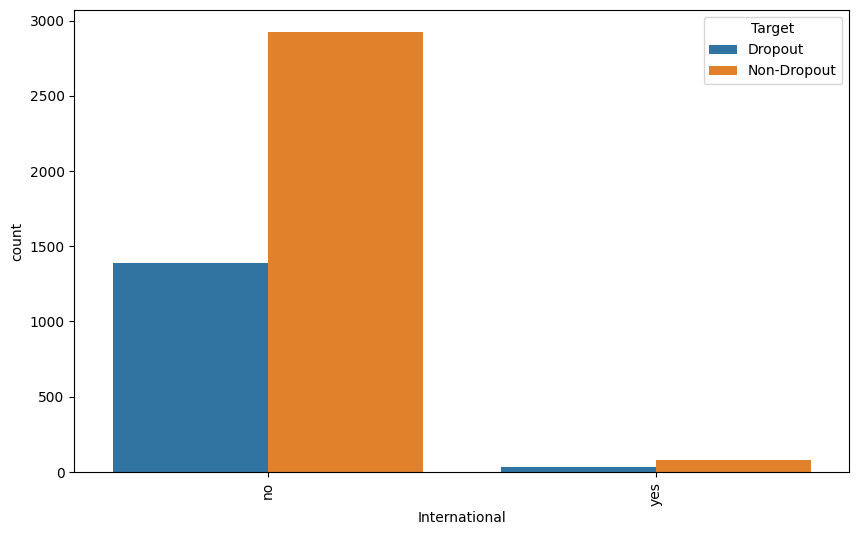

In [81]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="International", hue="Target")

plt.xticks(rotation=90)

plt.show()

No need to update

## Check Correlations of Numeric Columns

In [82]:
numeric_cols = list(df.select_dtypes(exclude="object").columns)

df[numeric_cols]

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,122.0,127.3,20,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,160.0,142.5,19,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,122.0,124.8,19,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,122.0,119.6,20,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,100.0,141.5,45,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,125.0,122.2,19,0,6,7,5,13.600000,0,0,6,8,5,12.666667,0,15.5,2.8,-4.06
4420,120.0,119.0,18,0,6,6,6,12.000000,0,0,6,6,2,11.000000,0,11.1,0.6,2.02
4421,154.0,149.5,30,0,7,8,7,14.912500,0,0,8,9,1,13.500000,0,13.9,-0.3,0.79
4422,180.0,153.8,20,0,5,5,5,13.800000,0,0,5,6,5,12.000000,0,9.4,-0.8,-3.12


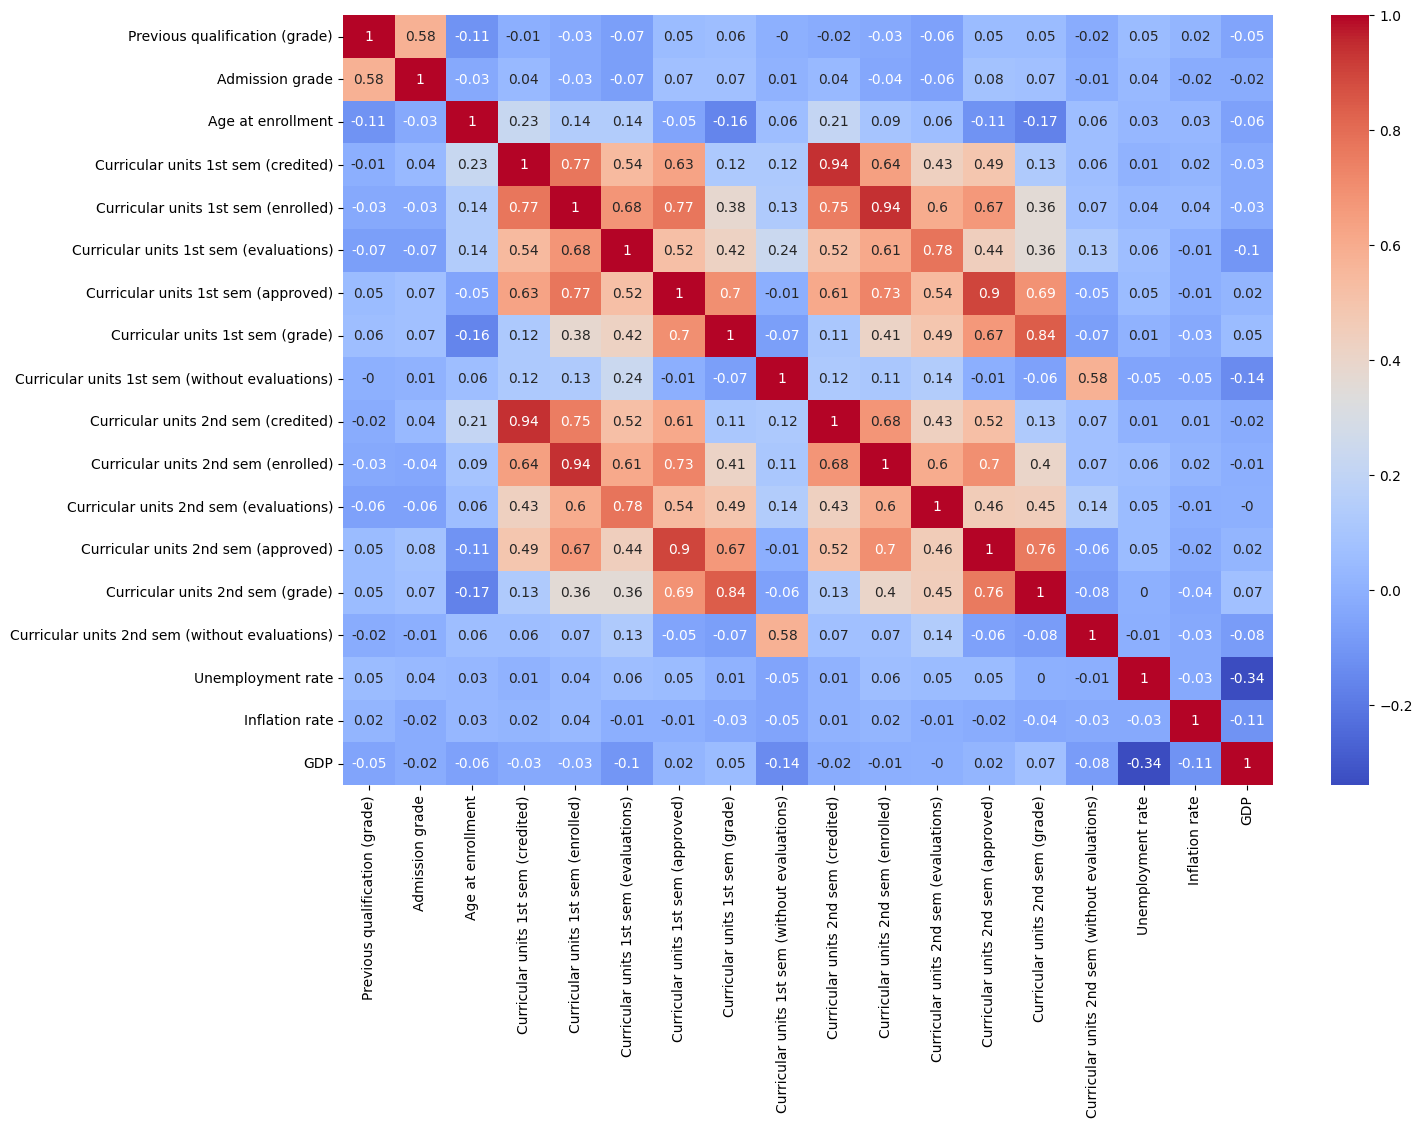

In [83]:
# Create a correlation plot using the numeric_cols
plt.figure(figsize=(15, 10))
sns.heatmap(df[numeric_cols].corr().round(2), annot=True, cmap="coolwarm")
plt.show()

There are high correlations between most of the curricular units (except without evaluations). Theere's a potential to remove some of these columns due to high positive correlations as the models are tuned. For purposes of the initial trial, they'll be kept.

## Outlier Detection (Continuous Variables)

### IQR Method

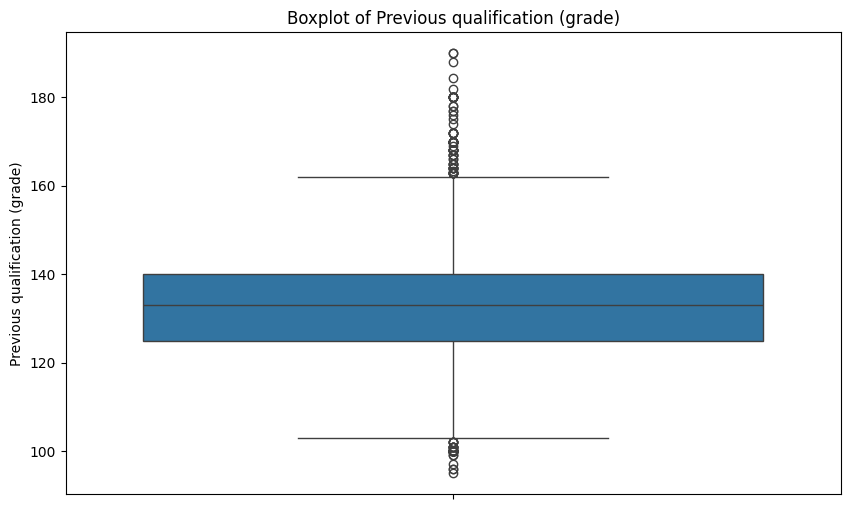

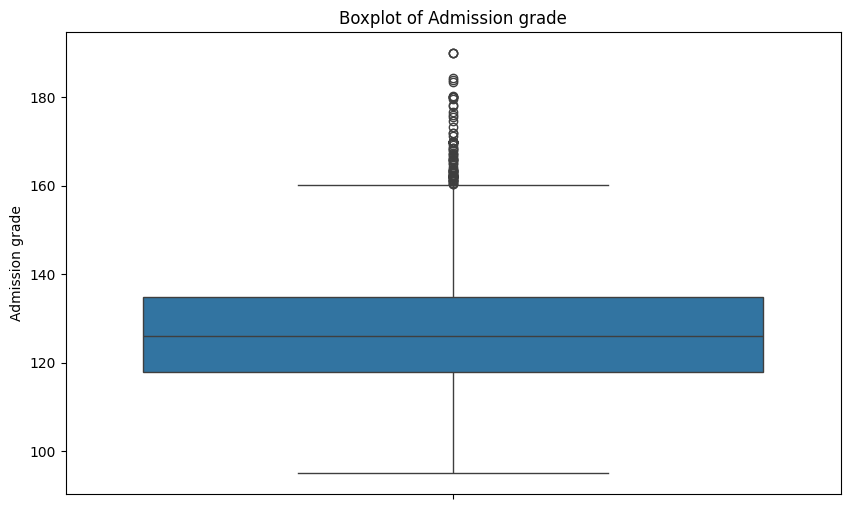

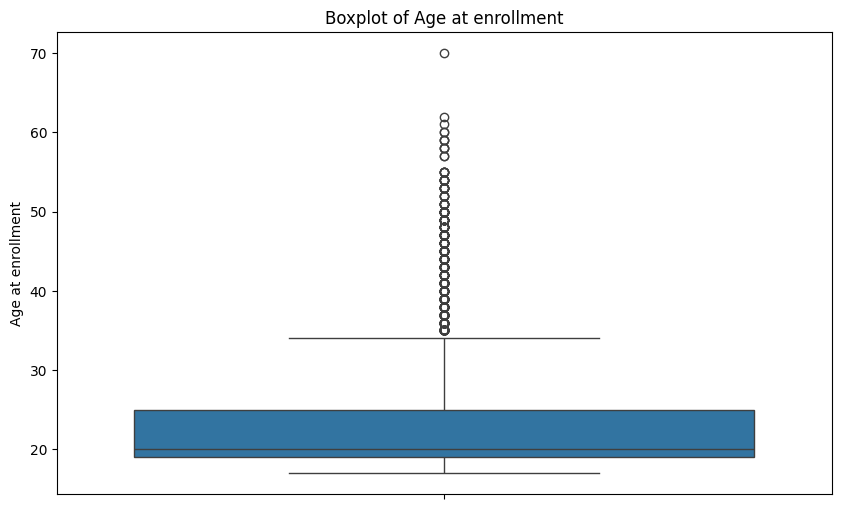

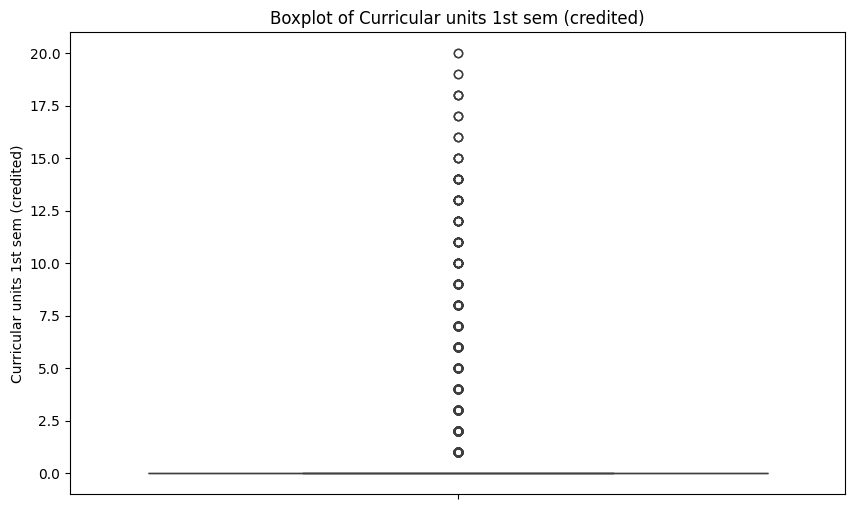

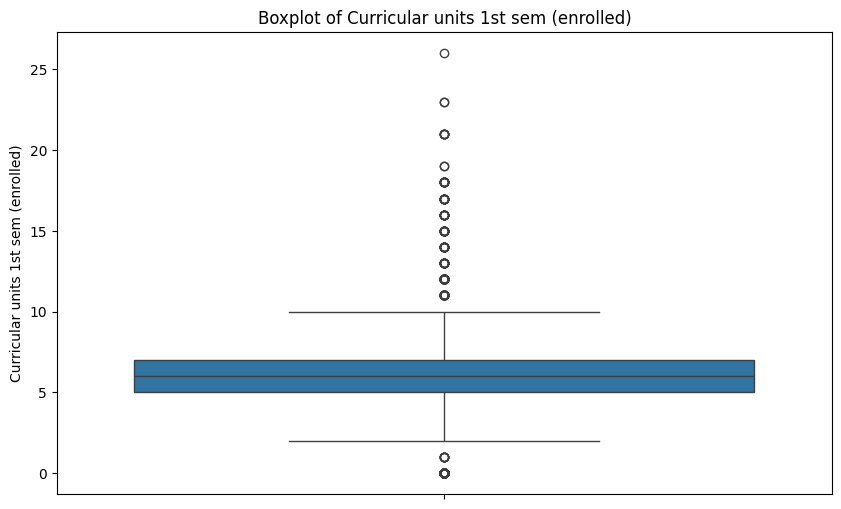

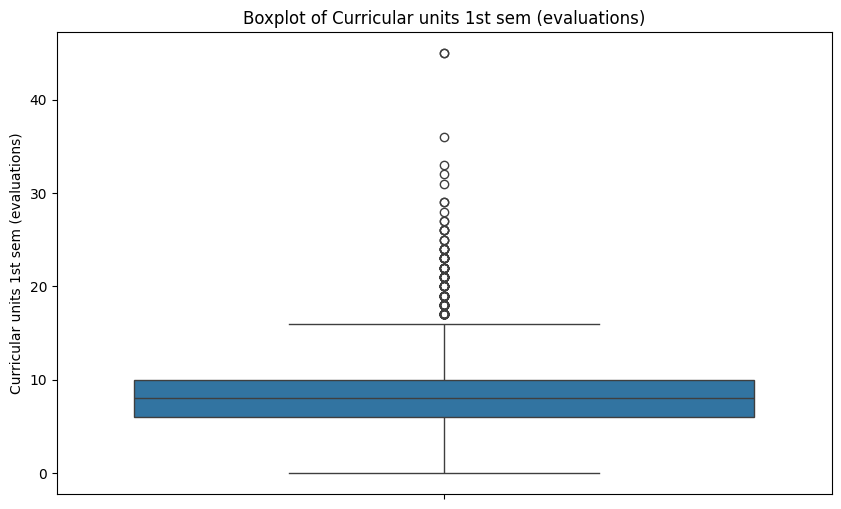

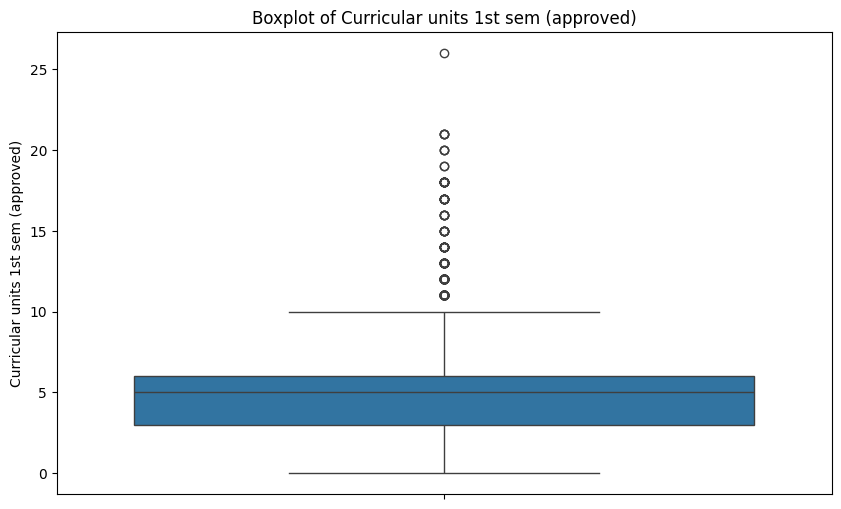

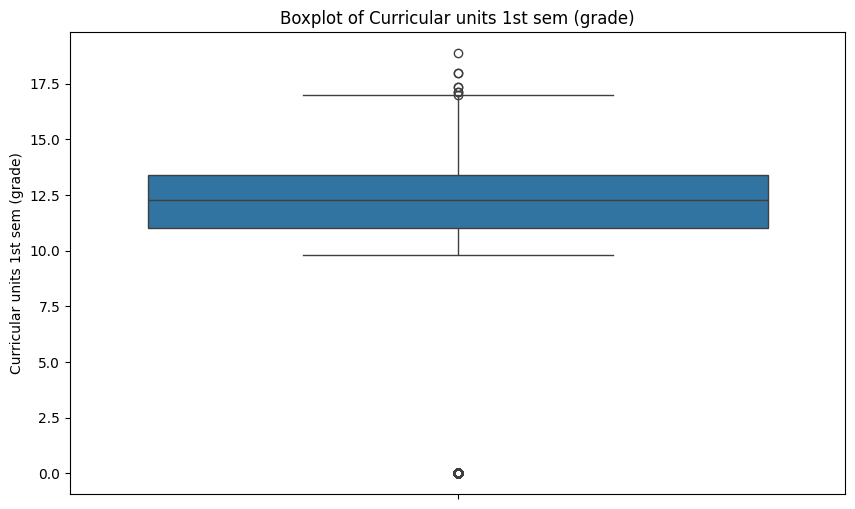

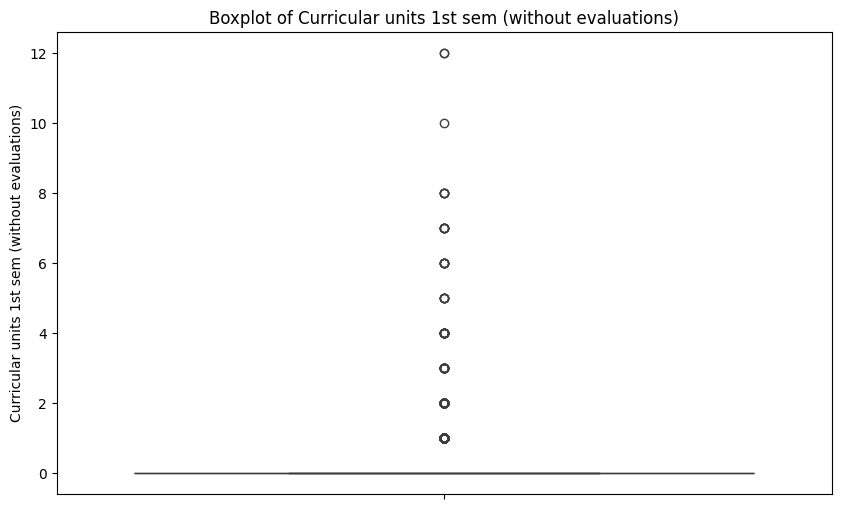

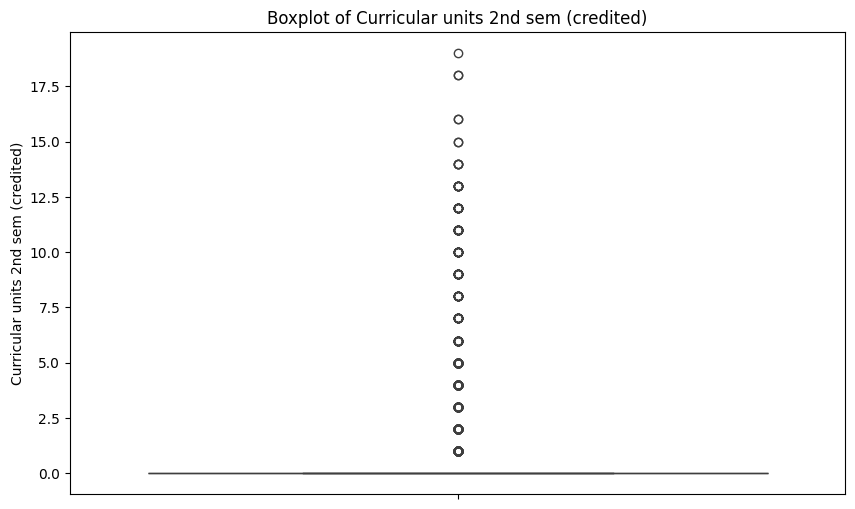

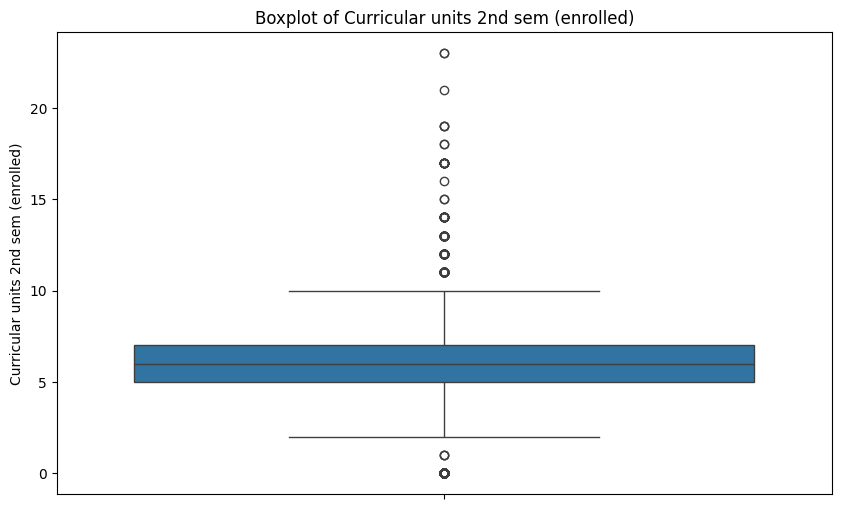

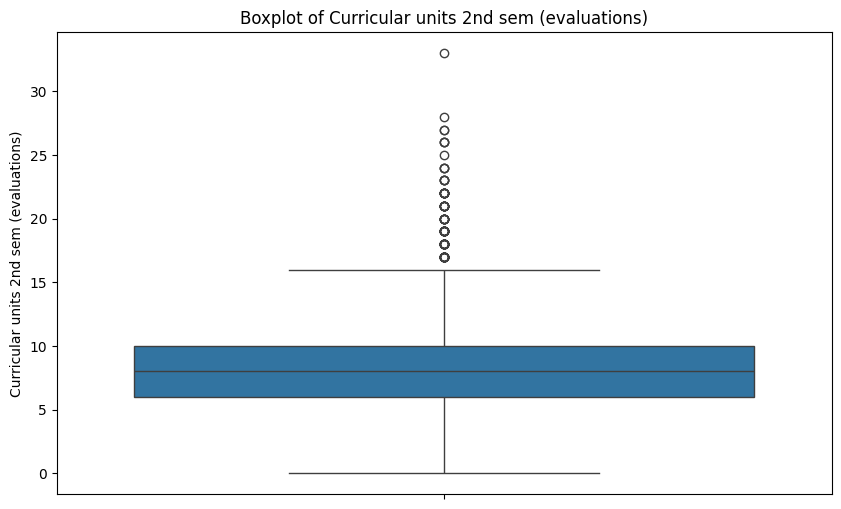

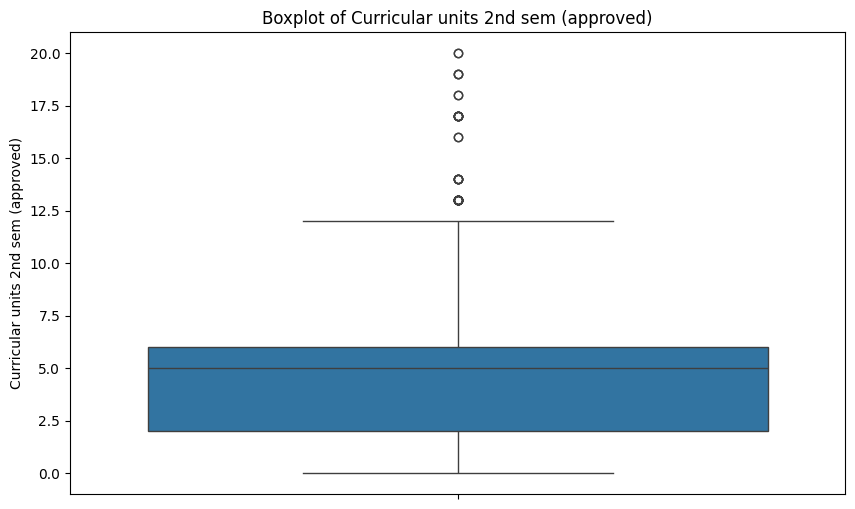

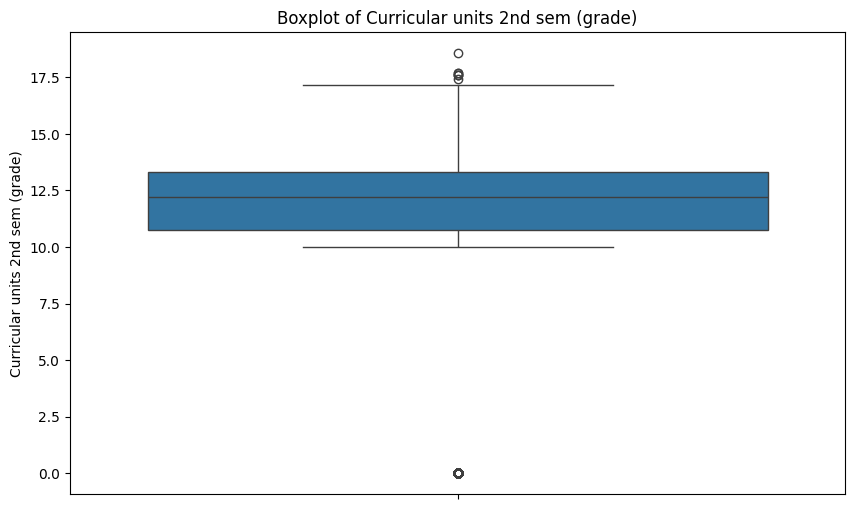

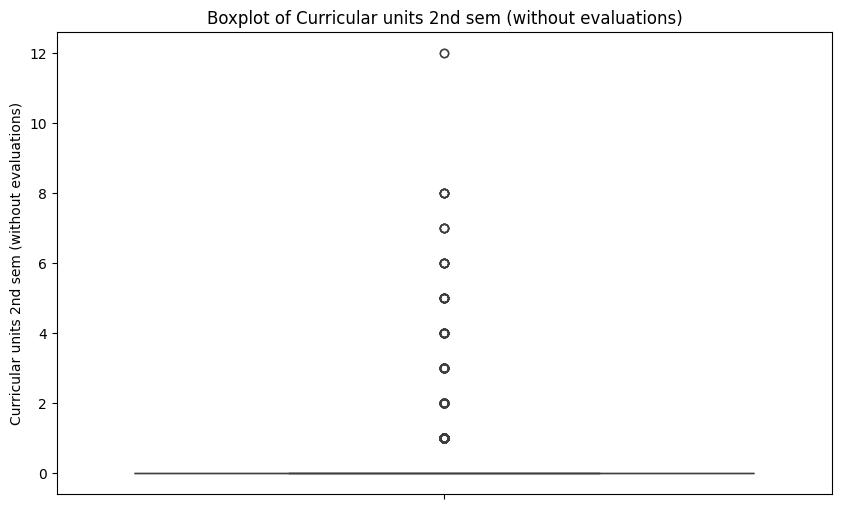

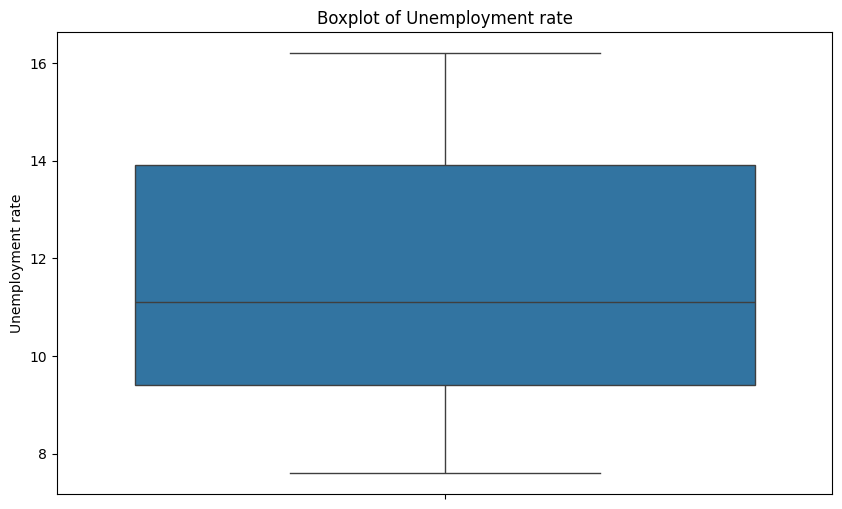

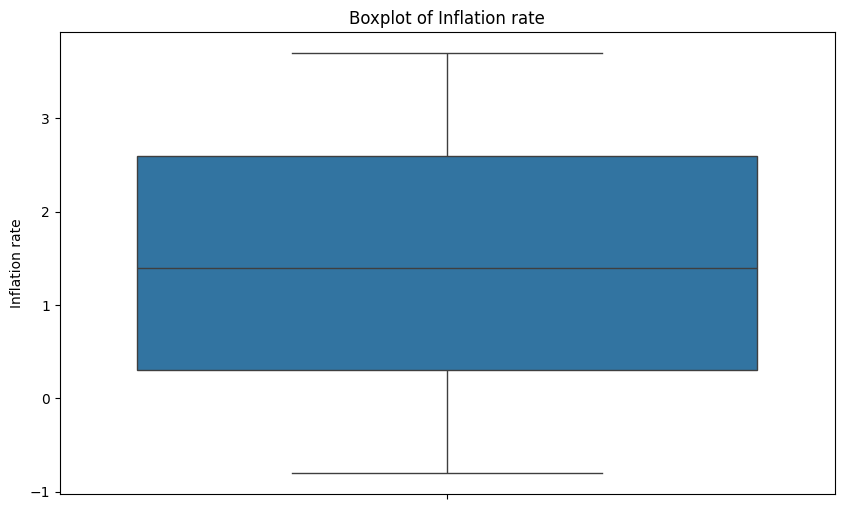

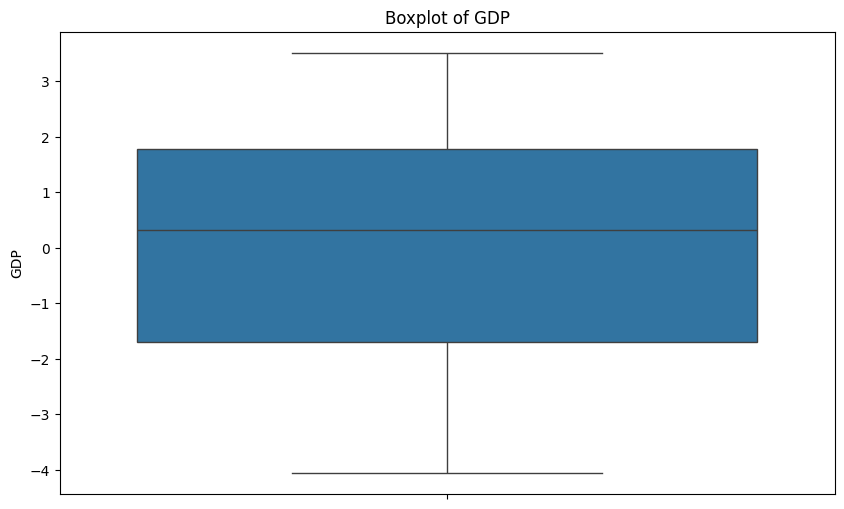

In [84]:
# Generate box plots for all numeric columns in df_clean
numeric_cols_clean = df.select_dtypes(include=np.number).columns

for col in numeric_cols_clean:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, y=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

NOTE:

While the curricular units columns show some higher values, these are all within the realm of possibilities. Because of this, we would opt to keep those records in to check initial performance.

In [85]:
# Select only the numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Remove any column containing "Curricular units"
numeric_cols = [col for col in numeric_cols if "Curricular units" not in col]

# Create a copy of the DataFrame to store without messing with our original data
df_clean = df.copy()

# Iterate through each numeric column to clip outliers
for col in numeric_cols:
    print(f"Removing outliers in column: {col}")

    # calculate quantiles
    q1 = df_clean[col].quantile(0.01)  # 1st percentile
    q3 = df_clean[col].quantile(0.99)  # 99th percentile

    # Filter to keep only values within the range
    before = len(df_clean)
    df_clean = df_clean[(df_clean[col] >= q1) & (df_clean[col] <= q3)]
    after = len(df_clean)

    print(f"Removed {before - after} rows outside [{q1:.2f}, {q3:.2f}] in {col}")
    print("-" * 30)

# Display the first few rows of the DataFrame with clipped values
display(df_clean.head())

Removing outliers in column: Previous qualification (grade)
Removed 33 rows outside [100.00, 170.00] in Previous qualification (grade)
------------------------------
Removing outliers in column: Admission grade
Removed 88 rows outside [99.48, 163.41] in Admission grade
------------------------------
Removing outliers in column: Age at enrollment
Removed 46 rows outside [18.00, 50.00] in Age at enrollment
------------------------------
Removing outliers in column: Unemployment rate
Removed 0 rows outside [7.60, 16.20] in Unemployment rate
------------------------------
Removing outliers in column: Inflation rate
Removed 0 rows outside [-0.80, 3.70] in Inflation rate
------------------------------
Removing outliers in column: GDP
Removed 0 rows outside [-4.06, 3.51] in GDP
------------------------------


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,single/widower,D,1 or 5,"Oral Hygiene, Animation/Multimedia, Tourism, M...",daytime,C,122.0,Portuguese,E,C,C,B,127.3,yes,no,no,yes,male,no,20,no,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,single/widower,E,1 or 5,"Oral Hygiene, Animation/Multimedia, Tourism, M...",daytime,C,160.0,Portuguese,E,C,C,B,142.5,yes,no,no,no,male,no,19,no,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Non-Dropout
2,single/widower,E,1 or 5,"Vet Nursing, Communication Design, Social Serv...",daytime,C,122.0,Portuguese,NaN,C,B,B,124.8,yes,no,no,no,male,no,19,no,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,single/widower,D,All others (0 - 9),"Oral Hygiene, Animation/Multimedia, Tourism, M...",daytime,C,122.0,Portuguese,E,C,C,B,119.6,yes,no,no,yes,female,no,20,no,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Non-Dropout
4,divorced/facto union/married,B,1 or 5,"Oral Hygiene, Animation/Multimedia, Tourism, M...",evening,C,100.0,Portuguese,NaN,D,B,B,141.5,no,no,no,yes,female,no,45,no,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Non-Dropout


### Mahalanobis Distance

In [86]:
# # subset the DataFrame to only include columns with numeric data
# numeric_cols = df.select_dtypes(include=[np.number]).columns

# # df = df[numeric_cols]
# df_numeric = df[numeric_cols].copy()

# # Handle Missing Values using Mean Imputation
# for col in df_numeric.columns:
#     if df_numeric[col].isnull().any():
#         mean_val = df_numeric[col].mean()
#         df_numeric[col] = df_numeric[col].fillna(mean_val)

# # calculate Mahalanobis distance for each row
# cov = df_numeric.cov()
# inv_cov = pd.DataFrame(np.linalg.inv(cov.values), index=cov.index, columns=cov.columns)
# mean = df_numeric.mean()
# distances = []
# for i, row in df_numeric.iterrows():
#     distances.append(mahalanobis(row, mean, inv_cov))

# # calculate threshold for outliers (can be adjusted to suit your needs)
# threshold = np.mean(distances) * 1.7

# # create new column in DataFrame to flag outliers
# df['is_outlier'] = pd.Series([dist > threshold for dist in distances], index=df_numeric.index)

# # print rows that are flagged as outliers
# display(df[df['is_outlier']])

# # create a scatterplot matrix of the numeric columns and color the points based on is_outlier
# g = sns.pairplot(df, height=1.5, hue='is_outlier', palette=['blue', 'red'])

# # remove the legend title and adjust the legend position
# g._legend.set_title('Outlier?')
# g._legend.set_bbox_to_anchor([1.2, 0.5])

# # show the plot
# plt.show()

In [87]:
# # Plot Mahalanobis distances
# plt.figure(figsize=(10, 6))

# # Use df.index as the x-axis since distances correspond to the original DataFrame rows
# plt.plot(df_numeric.index, distances, marker='o', linestyle='', markersize=3)
# plt.axhline(y=threshold, color='r', linestyle='-', label=f'Outlier Threshold ({threshold:.2f})')
# plt.title('Mahalanobis Distance by Row Number')
# plt.xlabel('Row Number')
# plt.ylabel('Mahalanobis Distance')
# plt.legend()
# plt.grid(True)
# plt.show()

In [88]:
# # Convert distances to a NumPy array (if it's not already)
# distances = np.array(distances)

# # Create a mask for non-outliers
# mask = distances <= threshold

# # Filter dataframe and distances
# df_clean = df_numeric[mask]
# distances_clean = distances[mask]

# # Re-plot
# plt.figure(figsize=(10, 6))
# plt.plot(df_clean.index, distances_clean, marker='o', linestyle='', markersize=3)
# plt.axhline(y=threshold, color='r', linestyle='-', label=f'Outlier Threshold ({threshold:.2f})')
# plt.title('Mahalanobis Distance After Removing Outliers')
# plt.xlabel('Row Number')
# plt.ylabel('Mahalanobis Distance')
# plt.legend()
# plt.grid(True)
# plt.show()

There was consideration for removing outliers based on standard IQR Method as well as the Mahalanobis Distance. Ultimately for the first iteration, the standard IQR method was used to hand-pick variables. Code was left in for future consideration.

## Transform Continuous Variables

In [89]:
# Select only the numeric columns from df_clean
numeric_cols_clean = df_clean.select_dtypes(include=np.number).columns
df_numeric_clean = df_clean[numeric_cols_clean]

# Initialize the PowerTransformer with Yeo-Johnson method
pt = PowerTransformer(method="yeo-johnson")

# Apply the transformation
df_numeric_transformed = pt.fit_transform(df_numeric_clean)

# Convert the transformed data back to a DataFrame
df_numeric_transformed = pd.DataFrame(
    df_numeric_transformed, columns=numeric_cols_clean, index=df_clean.index
)

# Display the first few rows of the transformed data
display(df_numeric_transformed.head())

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,-0.821847,0.109423,-0.188724,-0.385939,-3.046055,-2.270493,-1.731915,-2.107162,-0.269374,-0.366443,-2.985128,-2.153994,-1.609274,-1.934831,-0.261771,-0.207720,0.222751,0.743671
1,2.193808,1.190702,-0.616630,-0.385939,-0.070572,-0.510864,0.479032,0.836916,-0.269374,-0.366443,-0.102690,-0.506815,0.559100,0.715704,-0.261771,0.900156,-1.139328,0.223038
2,-0.821847,-0.082405,-0.616630,-0.385939,-0.070572,-2.270493,-1.731915,-2.107162,-0.269374,-0.366443,-0.102690,-2.153994,-1.609274,-1.934831,-0.261771,-0.207720,0.222751,0.743671
3,-0.821847,-0.495746,-0.188724,-0.385939,-0.070572,-0.020959,0.479032,0.631151,-0.269374,-0.366443,-0.102690,0.496032,0.252992,0.353957,-0.261771,-0.781046,-1.659448,-1.298348
4,-2.674298,1.123671,1.820109,-0.385939,-0.070572,0.214952,0.175027,0.255904,-0.269374,-0.366443,-0.102690,-0.506815,0.559100,0.522864,-0.261771,0.900156,-1.139328,0.223038


In [90]:
old_cols = df_numeric_transformed.columns.tolist()

# remove the old columns from the df_clean

df_clean = df_clean.drop(columns=old_cols)

# add the new columns from df_numeric_transformed
df_clean = pd.concat([df_clean, df_numeric_transformed], axis=1)

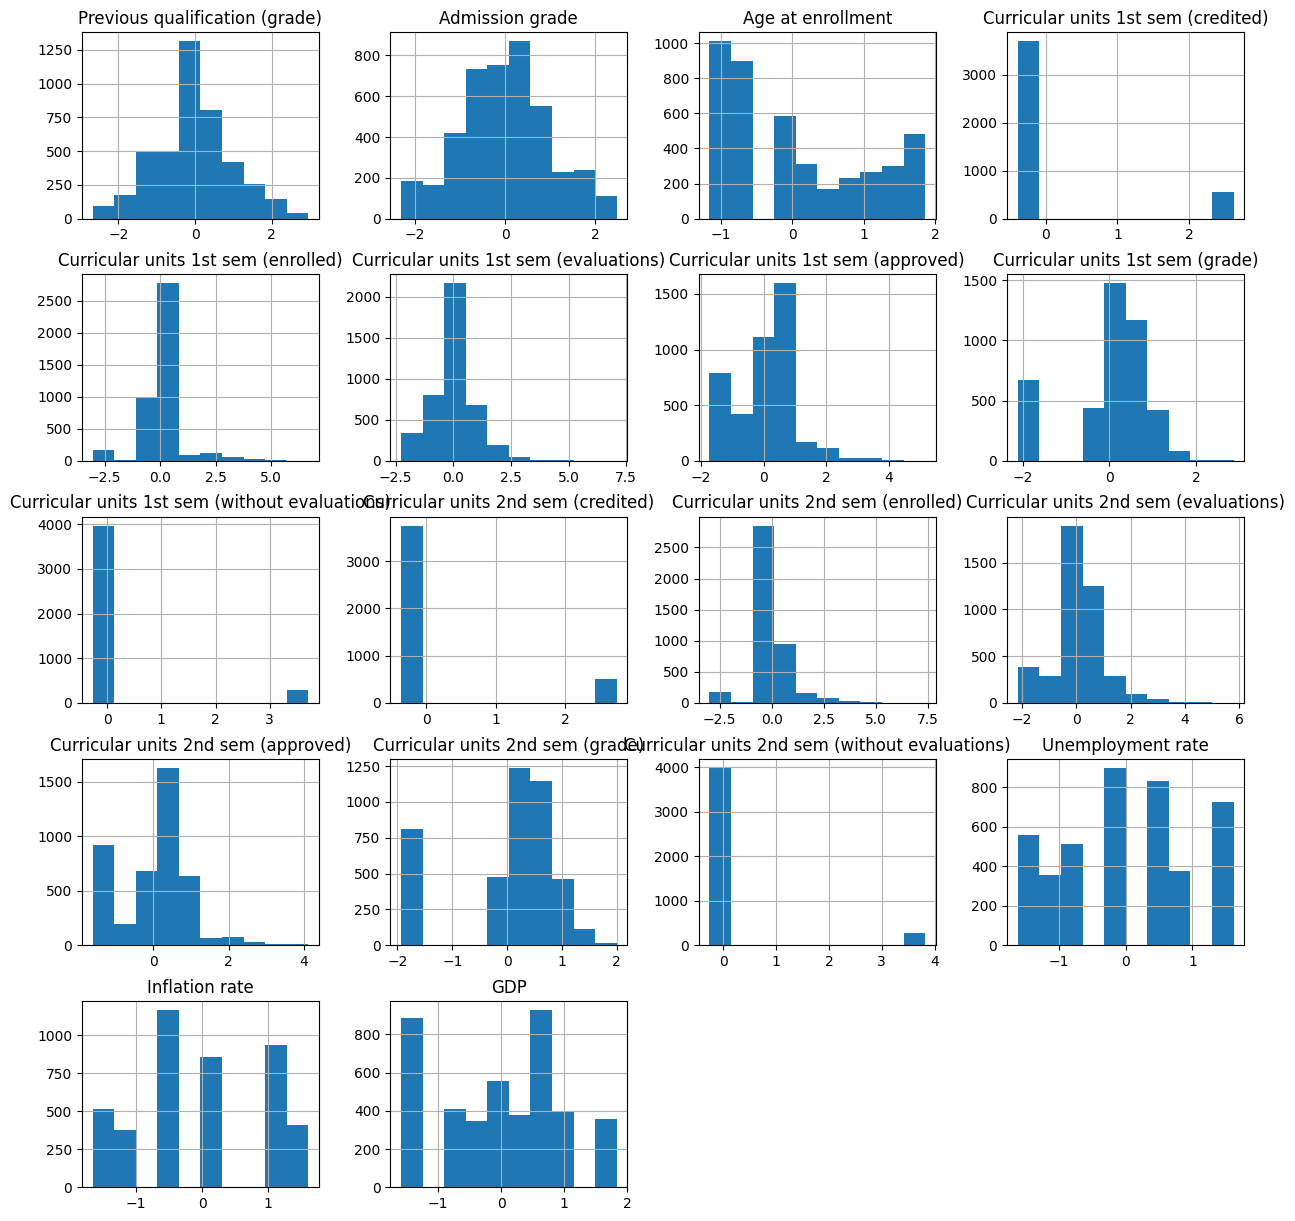

In [91]:
# Show a histogram for only the transformed numeric columns
df_numeric_transformed.hist(figsize=(15, 15))
plt.show()

Some notable data imbalances exist in Curricular Units 1st sem (without evaluations), Curricular Units 2nd sem (credited), and Curricular Units 2nd sem (without evaluations) even after transformation. Dropping these columns may be beneficial, which can be confirmed later using feature importance and p-values. For the current model, the columns are retained and will be revisited in a second iteration.

# Modeling

## Logistic Regression Model

In [92]:
# Update the target to be numerical for purposes of running the model
# Update "Target" such that we have "Dropout" and "Non-Dropout"
df_clean["Target"] = df_clean["Target"].map({"Dropout": 1, "Non-Dropout": 0})

df_clean["Target"].value_counts()

Target
0    2902
1    1355
Name: count, dtype: int64

### Train the Model

In [93]:
# Define the target variable
target = "Target"

# Define features by dropping the target
features = df_clean.drop([target], axis=1)

# Convert categorical features to dummy variables
features = pd.get_dummies(features, drop_first=True)

target_variable = df_clean[target]

# Split the data into 60% training and 40% test
X_train, X_test, y_train, y_test = train_test_split(
    features, target_variable, test_size=0.4, random_state=42
)

# Split the remaining 40% test data into 50% training and 50% validation (20% of our total df each)
X_test, X_val, y_test, y_val = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42
)

# Print the shapes of the resulting datasets and show the first few rows of the processed features
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)
print("\nFirst 5 rows of processed features (X_train):")
display(X_train.head())

Training set shape: (2554, 53) (2554,)
Validation set shape: (852, 53) (852,)
Test set shape: (851, 53) (851,)

First 5 rows of processed features (X_train):


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Marital status_legally separated,Marital status_single/widower,Application mode_B,Application mode_C,Application mode_D,Application mode_E,Application mode_F,Application order_All others (0 - 9),"Course_Education, Agronomy","Course_Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm","Course_Vet Nursing, Communication Design, Social Service, Nursing",Daytime/evening attendance\t_evening,Previous qualification_B,Previous qualification_C,Nacionality_Portuguese,Mother's qualification_B,Mother's qualification_C,Mother's qualification_D,Mother's qualification_E,Mother's qualification_F,Father's qualification_B,Father's qualification_C,Father's qualification_D,Mother's occupation_B,Mother's occupation_C,Mother's occupation_D,Father's occupation_B,Father's occupation_C,Displaced_yes,Educational special needs_yes,Debtor_yes,Tuition fees up to date_yes,Gender_male,Scholarship holder_yes,International_yes
196,-0.494372,-0.239031,-1.159966,-0.385939,0.729388,-0.020959,1.050680,0.458491,-0.269374,-0.366443,0.809467,0.000088,1.139312,0.503996,-0.261771,-0.781046,-1.659448,-1.298348,False,True,False,True,False,False,False,True,False,False,True,False,False,True,True,False,False,False,False,False,False,True,False,False,True,False,True,False,True,False,False,True,False,False,False
106,-0.821847,-0.610517,-0.616630,-0.385939,-0.070572,-2.270493,-1.731915,-2.107162,-0.269374,-0.366443,-0.102690,-2.153994,-1.609274,-1.934831,-0.261771,1.614869,-0.596622,-0.539497,False,True,False,False,False,True,False,True,False,False,True,False,False,True,True,False,False,False,False,False,False,False,True,True,False,False,True,False,True,False,False,True,False,False,False
4278,-0.739731,-0.059157,-1.159966,-0.385939,-0.070572,-0.510864,0.479032,0.960085,-0.269374,-0.366443,-0.102690,-0.506815,0.559100,1.220968,-0.261771,-0.091569,-0.356184,0.906641,False,True,False,False,False,True,False,True,False,True,False,False,False,True,True,False,False,False,True,False,False,True,False,True,False,False,True,False,True,False,True,True,True,True,False
3810,-0.575995,-0.176036,-1.159966,-0.385939,0.335820,-0.020959,0.175027,0.433198,-0.269374,-0.366443,0.355212,0.000088,0.252992,0.483055,-0.261771,-1.610259,0.984203,-0.012005,False,True,False,True,False,False,False,False,False,False,True,False,False,True,True,False,False,False,False,False,False,True,False,True,False,False,True,False,True,False,False,True,False,True,False
3352,0.528700,-1.199614,1.213959,2.484887,-0.070572,-0.262602,-0.484263,0.146725,-0.269374,2.736510,-0.102690,-0.251814,-0.764001,-0.022575,-0.261771,0.900156,-1.139328,0.223038,False,True,True,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,True,False,False,True,False,True,False,False,True,False,False,False,False,True,True,False,False


In [94]:
# fit the model
logistic_model = LogisticRegression(
    random_state=42, max_iter=5000
)  # Increased max_iter for convergence
logistic_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [95]:
# Make predictions (classes) on the training, validation, and test sets
y_train_pred = logistic_model.predict(X_train)
y_val_pred = logistic_model.predict(X_val)
y_test_pred = logistic_model.predict(X_test)

# Get predicted probabilities for the training, validation, and test sets
y_train_proba = logistic_model.predict_proba(X_train)[
    :, 1
]  # Probability of the positive class (1)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]
y_test_proba = logistic_model.predict_proba(X_test)[:, 1]

print(
    "Predictions (classes and probabilities) made successfully on training, validation, and test sets."
)

Predictions (classes and probabilities) made successfully on training, validation, and test sets.


### Model Performance

Confusion Matrix - Training Set:
[[1680   74]
 [ 207  593]]

Confusion Matrix - Validation Set:
[[529  37]
 [ 78 208]]

Confusion Matrix - Test Set:
[[553  29]
 [ 76 193]]


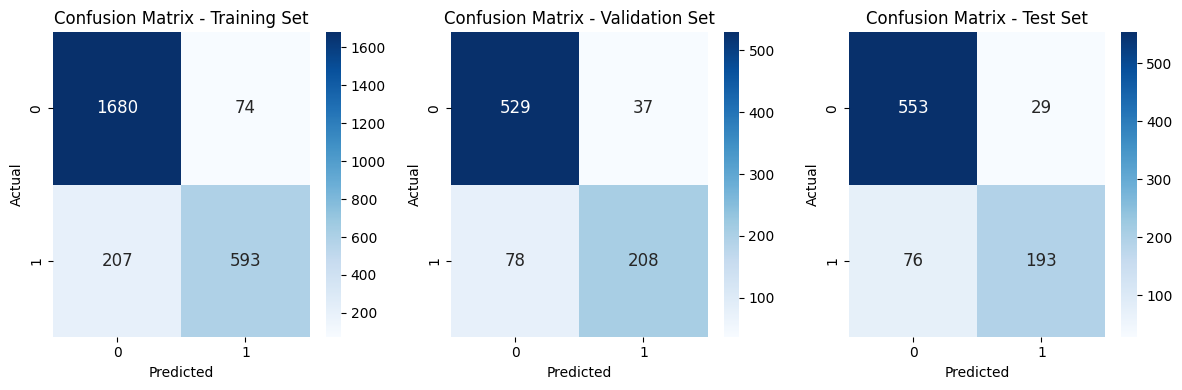

In [96]:
# Calculate confusion matrix for the training set
cm_train = confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix - Training Set:")
print(cm_train)

# Calculate confusion matrix for the validation set
cm_val = confusion_matrix(y_val, y_val_pred)
print("\nConfusion Matrix - Validation Set:")
print(cm_val)

# Calculate confusion matrix for the test set
cm_test = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix - Test Set:")
print(cm_test)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(
    cm_train, annot=True, fmt="d", cmap="Blues", ax=axes[0], annot_kws={"size": 12}
)
axes[0].set_title("Confusion Matrix - Training Set")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_val, annot=True, fmt="d", cmap="Blues", ax=axes[1], annot_kws={"size": 12}
)
axes[1].set_title("Confusion Matrix - Validation Set")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(
    cm_test, annot=True, fmt="d", cmap="Blues", ax=axes[2], annot_kws={"size": 12}
)
axes[2].set_title("Confusion Matrix - Test Set")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [97]:
# COMMENTING OUT TO FORMAT RESULTS IN A TABLE WE CAN REFERENCE LATER

# # Check model performance by partition with total accuracy
# print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
# print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
# print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

# # Check model performance by partition with precision
# print("\n")
# print("Train Precision:", metrics.precision_score(y_train, y_train_pred))
# print("Validation Precision:", metrics.precision_score(y_val, y_val_pred))
# print("Test Precision:", metrics.precision_score(y_test, y_test_pred))

# # Check model performance by partition with recall
# print("\n")
# print("Train Recall:", metrics.recall_score(y_train, y_train_pred))
# print("Validation Recall:", metrics.recall_score(y_val, y_val_pred))
# print("Test Recall:", metrics.recall_score(y_test, y_test_pred))

# # Check model performance by partition with F1 Score
# print("\n")
# print("Train F1 Score:", metrics.f1_score(y_train, y_train_pred))
# print("Validation F1 Score:", metrics.f1_score(y_val, y_val_pred))
# print("Test F1 Score:", metrics.f1_score(y_test, y_test_pred))

In [98]:
# Store in a table to review later
results_lm = pd.DataFrame(
    {
        "Accuracy": [
            metrics.accuracy_score(y_train, y_train_pred),
            metrics.accuracy_score(y_val, y_val_pred),
            metrics.accuracy_score(y_test, y_test_pred),
        ],
        "Precision": [
            metrics.precision_score(y_train, y_train_pred),
            metrics.precision_score(y_val, y_val_pred),
            metrics.precision_score(y_test, y_test_pred),
        ],
        "Recall": [
            metrics.recall_score(y_train, y_train_pred),
            metrics.recall_score(y_val, y_val_pred),
            metrics.recall_score(y_test, y_test_pred),
        ],
        "F1 Score": [
            metrics.f1_score(y_train, y_train_pred),
            metrics.f1_score(y_val, y_val_pred),
            metrics.f1_score(y_test, y_test_pred),
        ],
    },
    index=["Train", "Validation", "Test"],
)

results_lm = round(results_lm, 4)

print("Results using all variables\n")
display(results_lm)

Results using all variables



,Accuracy,Precision,Recall,F1 Score
Train,0.8900,0.8891,0.7412,0.8085
Validation,0.8650,0.8490,0.7273,0.7834
Test,0.8766,0.8694,0.7175,0.7862


In [99]:
# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1754
           1       0.89      0.74      0.81       800

    accuracy                           0.89      2554
   macro avg       0.89      0.85      0.87      2554
weighted avg       0.89      0.89      0.89      2554


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       566
           1       0.85      0.73      0.78       286

    accuracy                           0.87       852
   macro avg       0.86      0.83      0.84       852
weighted avg       0.86      0.87      0.86       852


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       582
           1       0.87      0.72      0.79       269

    accuracy                           0.88       851
   macro avg  

### Lift Curve

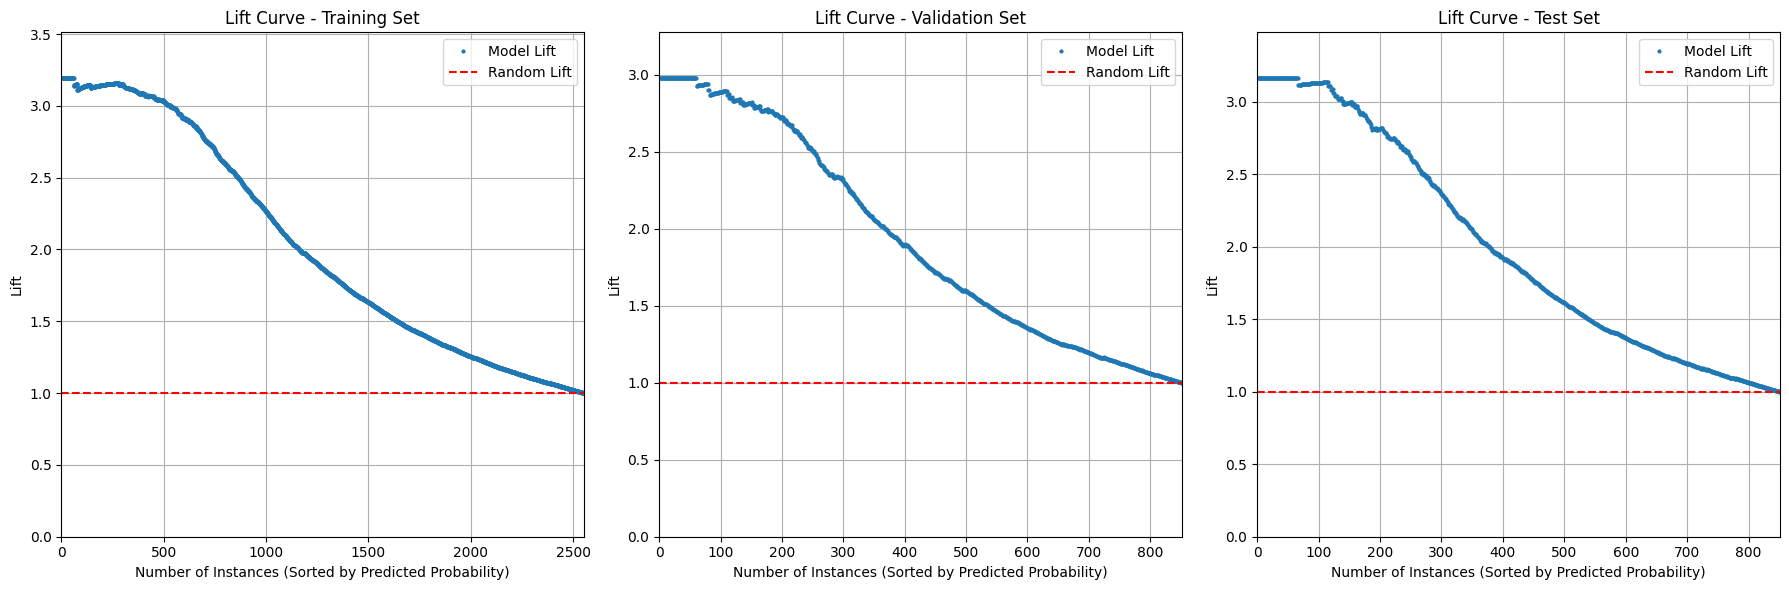

In [100]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

### ROC Curve + AUC

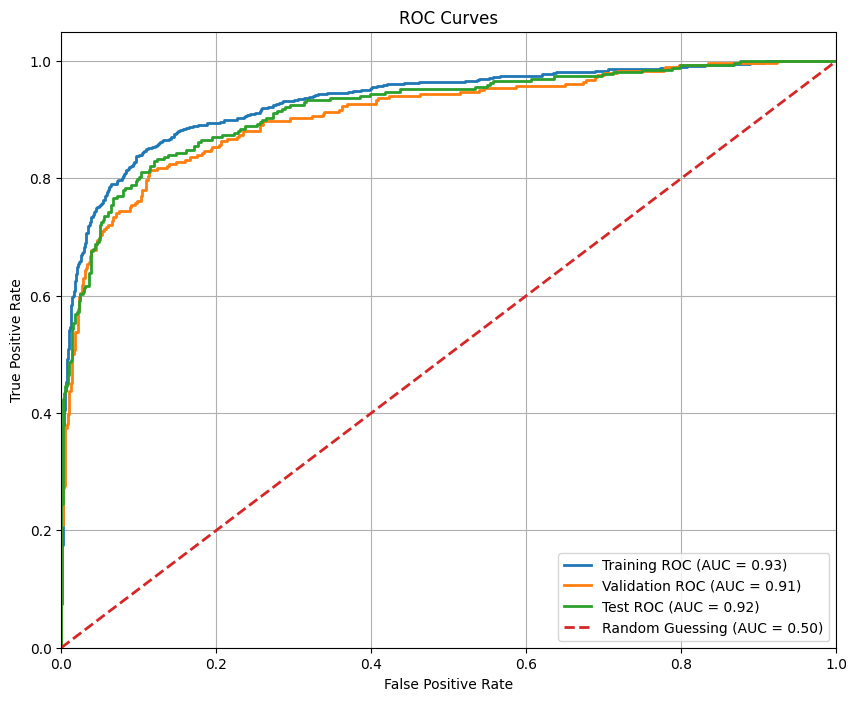


AUC Scores:
  Training AUC:   0.9330
  Validation AUC: 0.9096
  Test AUC:       0.9198


In [101]:
plot_roc_auc(y_train, y_val, y_test, y_train_proba, y_val_proba, y_test_proba)

### Variable Selection

In [102]:
# Convert boolean columns to integers (0s and 1s) for statsmodels
X_train_sm = X_train.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_sm = sm.add_constant(X_train_sm)

# Fit the logistic regression model using statsmodels
logit_model = sm.Logit(y_train, X_train_sm)
result = logit_model.fit()

# Show the model summary, which includes p-values
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.322025
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                 2554
Model:                          Logit   Df Residuals:                     2501
Method:                           MLE   Df Model:                           52
Date:                Sat, 20 Dec 2025   Pseudo R-squ.:                  0.4820
Time:                        16:03:01   Log-Likelihood:                -822.45
converged:                       True   LL-Null:                       -1587.7
Covariance Type:            nonrobust   LLR p-value:                3.659e-286
                                                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

In [103]:
significant_vars = result.pvalues[result.pvalues < 0.05]
print(significant_vars)

Admission grade                                                                                                                      3.107498e-02
Curricular units 1st sem (approved)                                                                                                  6.448883e-03
Curricular units 2nd sem (enrolled)                                                                                                  1.117608e-03
Curricular units 2nd sem (approved)                                                                                                  6.630973e-21
Curricular units 2nd sem (grade)                                                                                                     1.624950e-04
Unemployment rate                                                                                                                    4.771393e-03
Application mode_B                                                                                                          

### Conclusion from our initial Logistic Regression Model

The original model ran pretty well! It performed pretty consistent across all 3 sets as well, so it seems like we're not getting too much overfitting.

Model performance showed:
* Accuracy around .87 for all 3 sets on average
* Around .86 precision on average
* About .73 recall on average
* About .79 F1 score on average

Checking our features with the summary, we can see that certain variables were important at the p < .05 level such as:
* Admission grade
* Curricular units (Various types)
* Unemployment rate
* Application mode
* Course
* Daytime or Evening attendance
* Previous qualifications
* Nationality *(which was surprising)*
* Fathers qualification
* Mother's occupation
* Displaced status
* Debtor status
* Tuition fees status
* Gender
* Scholorship status

## Logistic Regression Model (removing insignificant terms)

### Train the Model

In [104]:
keep = significant_vars.index.astype(str).str.split("_").str[0].unique()

cols_to_keep = [col for col in X_train.columns if any(col.startswith(i) for i in keep)]

X_train_significant = X_train[cols_to_keep]
X_val_significant = X_val[cols_to_keep]
X_test_significant = X_test[cols_to_keep]

In [105]:
# fit the model
logistic_model = LogisticRegression(
    random_state=42, max_iter=5000
)  # Increased max_iter for convergence
logistic_model.fit(X_train_significant, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [106]:
# Make predictions (classes) on the training, validation, and test sets
y_train_pred_significant = logistic_model.predict(X_train_significant)
y_val_pred_significant = logistic_model.predict(X_val_significant)
y_test_pred_significant = logistic_model.predict(X_test_significant)

# Get predicted probabilities for the training, validation, and test sets
y_train_significant_proba = logistic_model.predict_proba(X_train_significant)[
    :, 1
]  # Probability of the positive class (1)
y_val_significant_proba = logistic_model.predict_proba(X_val_significant)[:, 1]
y_test_significant_proba = logistic_model.predict_proba(X_test_significant)[:, 1]

print(
    "Predictions (classes and probabilities) made successfully on training, validation, and test sets."
)

Predictions (classes and probabilities) made successfully on training, validation, and test sets.


### Model Performance

Confusion Matrix - Training Set:
[[1676   78]
 [ 210  590]]

Confusion Matrix - Validation Set:
[[525  41]
 [ 79 207]]

Confusion Matrix - Test Set:
[[551  31]
 [ 79 190]]


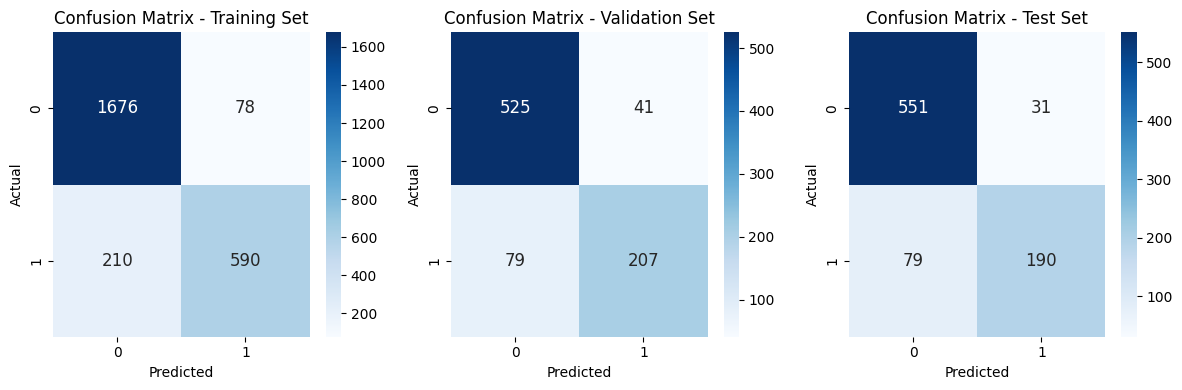

In [107]:
# Calculate confusion matrix for the training set
cm_train_significant = confusion_matrix(y_train, y_train_pred_significant)
print("Confusion Matrix - Training Set:")
print(cm_train_significant)

# Calculate confusion matrix for the validation set
cm_val_significant = confusion_matrix(y_val, y_val_pred_significant)
print("\nConfusion Matrix - Validation Set:")
print(cm_val_significant)

# Calculate confusion matrix for the test set
cm_test_significant = confusion_matrix(y_test, y_test_pred_significant)
print("\nConfusion Matrix - Test Set:")
print(cm_test_significant)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(
    cm_train_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    annot_kws={"size": 12},
)
axes[0].set_title("Confusion Matrix - Training Set")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_val_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    annot_kws={"size": 12},
)
axes[1].set_title("Confusion Matrix - Validation Set")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(
    cm_test_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[2],
    annot_kws={"size": 12},
)
axes[2].set_title("Confusion Matrix - Test Set")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [108]:
# COMMENTING OUT TO FORMAT RESULTS IN A TABLE WE CAN REFERENCE LATER

# # Check model performance by partition with total accuracy
# print("Train Accuracy:", accuracy_score(y_train, y_train_pred_significant))
# print("Validation Accuracy:", accuracy_score(y_val, y_val_pred_significant))
# print("Test Accuracy:", accuracy_score(y_test, y_test_pred_significant))

# # Check model performance by partition with precision
# print("\n")
# print("Train Precision:", metrics.precision_score(y_train, y_train_pred_significant))
# print("Validation Precision:", metrics.precision_score(y_val, y_val_pred_significant))
# print("Test Precision:", metrics.precision_score(y_test, y_test_pred_significant))

# # Check model performance by partition with recall
# print("\n")
# print("Train Recall:", metrics.recall_score(y_train, y_train_pred_significant))
# print("Validation Recall:", metrics.recall_score(y_val, y_val_pred_significant))
# print("Test Recall:", metrics.recall_score(y_test, y_test_pred_significant))

# # Check model performance by partition with F1 Score
# print("\n")
# print("Train F1 Score:", metrics.f1_score(y_train, y_train_pred_significant))
# print("Validation F1 Score:", metrics.f1_score(y_val, y_val_pred_significant))
# print("Test F1 Score:", metrics.f1_score(y_test, y_test_pred_significant))

In [109]:
# Store in a table to review later
results_lm_significant = pd.DataFrame(
    {
        "Accuracy": [
            metrics.accuracy_score(y_train, y_train_pred_significant),
            metrics.accuracy_score(y_val, y_val_pred_significant),
            metrics.accuracy_score(y_test, y_test_pred_significant),
        ],
        "Precision": [
            metrics.precision_score(y_train, y_train_pred_significant),
            metrics.precision_score(y_val, y_val_pred_significant),
            metrics.precision_score(y_test, y_test_pred_significant),
        ],
        "Recall": [
            metrics.recall_score(y_train, y_train_pred_significant),
            metrics.recall_score(y_val, y_val_pred_significant),
            metrics.recall_score(y_test, y_test_pred_significant),
        ],
        "F1 Score": [
            metrics.f1_score(y_train, y_train_pred_significant),
            metrics.f1_score(y_val, y_val_pred_significant),
            metrics.f1_score(y_test, y_test_pred_significant),
        ],
    },
    index=["Train", "Validation", "Test"],
)

results_lm_significant = round(results_lm_significant, 4)

print("Results using significant variables only\n")
display(results_lm_significant)

Results using significant variables only



,Accuracy,Precision,Recall,F1 Score
Train,0.8872,0.8832,0.7375,0.8038
Validation,0.8592,0.8347,0.7238,0.7753
Test,0.8707,0.8597,0.7063,0.7755


When comparing the performance metrics between the initial Logistic Regression model with all variables and the model trained only with statistically significant variables, the results are indeed very similar across Accuracy, Precision, Recall, F1 Score, and AUC.

In [110]:
# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred_significant))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred_significant))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred_significant))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1754
           1       0.88      0.74      0.80       800

    accuracy                           0.89      2554
   macro avg       0.89      0.85      0.86      2554
weighted avg       0.89      0.89      0.88      2554


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       566
           1       0.83      0.72      0.78       286

    accuracy                           0.86       852
   macro avg       0.85      0.83      0.84       852
weighted avg       0.86      0.86      0.86       852


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91       582
           1       0.86      0.71      0.78       269

    accuracy                           0.87       851
   macro avg  

### Lift Curve

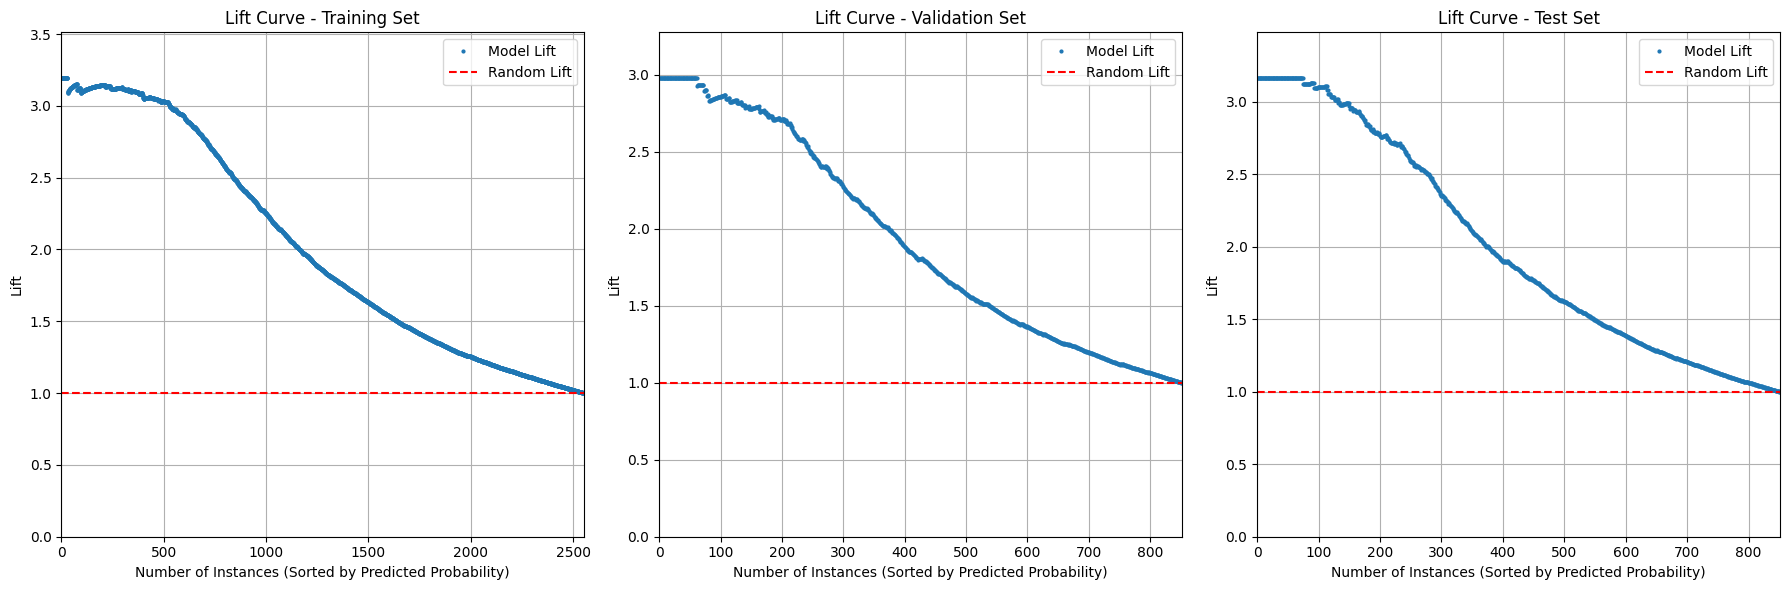

In [111]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_significant_proba, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_significant_proba, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_significant_proba, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

### ROC Curve + AUC

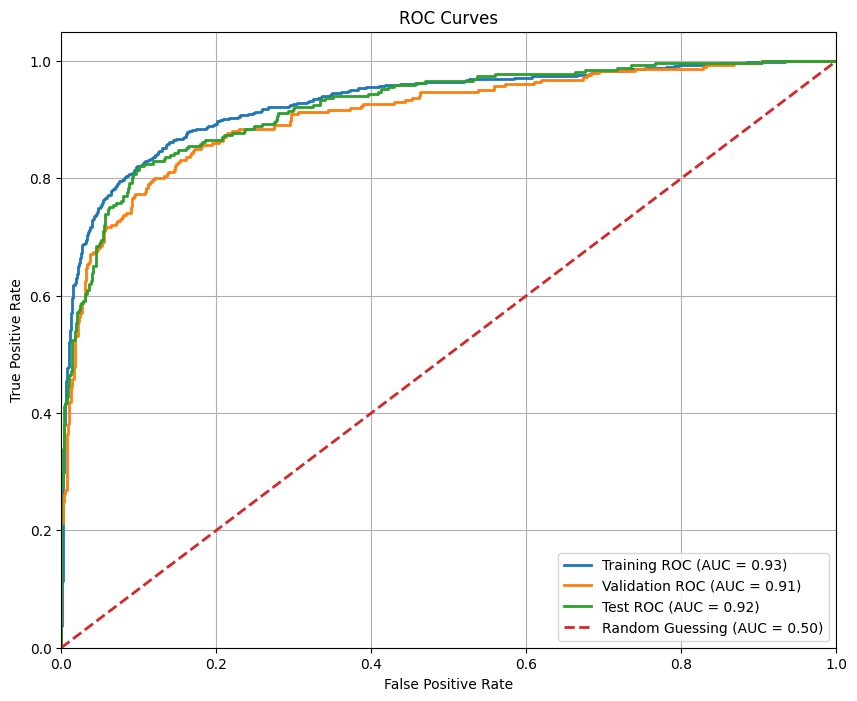


AUC Scores:
  Training AUC:   0.9304
  Validation AUC: 0.9089
  Test AUC:       0.9223


In [112]:
plot_roc_auc(
    y_train,
    y_val,
    y_test,
    y_train_significant_proba,
    y_val_significant_proba,
    y_test_significant_proba,
)

### Significant Features

In [113]:
# Convert boolean columns to integers (0s and 1s) for statsmodels
X_train_significant_sm = X_train_significant.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_significant_sm = sm.add_constant(X_train_significant_sm)

# Fit the logistic regression model using statsmodels
logit_model_significant = sm.Logit(y_train, X_train_significant_sm)
result_significant = logit_model_significant.fit()

# Show the model summary, which includes p-values
print(result_significant.summary())

Optimization terminated successfully.
         Current function value: 0.327435
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                 2554
Model:                          Logit   Df Residuals:                     2524
Method:                           MLE   Df Model:                           29
Date:                Sat, 20 Dec 2025   Pseudo R-squ.:                  0.4733
Time:                        16:03:02   Log-Likelihood:                -836.27
converged:                       True   LL-Null:                       -1587.7
Covariance Type:            nonrobust   LLR p-value:                1.300e-298
                                                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

After dropping insignificant variables in the first iteration, a few additional variables were found to be insignificant. While some specific sub-categories became insignificant, others within the same category remained significant, so these categories were retained. (Note: significance assessed at p < .05)

In [114]:
cols_to_drop = ["Previous qualification (grade)"]

## Logistic Regression Model (removing insignificant terms) - Round 2

### Train the Model

In [115]:
cols_to_keep

['Previous qualification (grade)',
 'Admission grade',
 'Curricular units 1st sem (approved)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Unemployment rate',
 'Application mode_B',
 'Application mode_C',
 'Application mode_D',
 'Application mode_E',
 'Application mode_F',
 'Course_Education, Agronomy',
 'Course_Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm',
 'Course_Vet Nursing, Communication Design, Social Service, Nursing',
 'Daytime/evening attendance\t_evening',
 'Previous qualification_B',
 'Previous qualification_C',
 "Father's qualification_B",
 "Father's qualification_C",
 "Father's qualification_D",
 "Mother's occupation_B",
 "Mother's occupation_C",
 "Mother's occupation_D",
 'Displaced_yes',
 'Debtor_yes',
 'Tuition fees up to date_yes',
 'Gender_male',
 'Scholarship holder_yes']

In [116]:
cols_to_keep = [col for col in cols_to_keep if col not in cols_to_drop]

cols_to_keep

['Admission grade',
 'Curricular units 1st sem (approved)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Unemployment rate',
 'Application mode_B',
 'Application mode_C',
 'Application mode_D',
 'Application mode_E',
 'Application mode_F',
 'Course_Education, Agronomy',
 'Course_Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm',
 'Course_Vet Nursing, Communication Design, Social Service, Nursing',
 'Daytime/evening attendance\t_evening',
 'Previous qualification_B',
 'Previous qualification_C',
 "Father's qualification_B",
 "Father's qualification_C",
 "Father's qualification_D",
 "Mother's occupation_B",
 "Mother's occupation_C",
 "Mother's occupation_D",
 'Displaced_yes',
 'Debtor_yes',
 'Tuition fees up to date_yes',
 'Gender_male',
 'Scholarship holder_yes']

In [117]:
X_train_significant = X_train[cols_to_keep]
X_val_significant = X_val[cols_to_keep]
X_test_significant = X_test[cols_to_keep]

In [118]:
# fit the model
logistic_model = LogisticRegression(
    random_state=42, max_iter=5000
)  # Increased max_iter for convergence
logistic_model.fit(X_train_significant, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [119]:
# Make predictions (classes) on the training, validation, and test sets
y_train_pred_significant = logistic_model.predict(X_train_significant)
y_val_pred_significant = logistic_model.predict(X_val_significant)
y_test_pred_significant = logistic_model.predict(X_test_significant)

# Get predicted probabilities for the training, validation, and test sets
y_train_significant_proba = logistic_model.predict_proba(X_train_significant)[
    :, 1
]  # Probability of the positive class (1)
y_val_significant_proba = logistic_model.predict_proba(X_val_significant)[:, 1]
y_test_significant_proba = logistic_model.predict_proba(X_test_significant)[:, 1]

print(
    "Predictions (classes and probabilities) made successfully on training, validation, and test sets."
)

Predictions (classes and probabilities) made successfully on training, validation, and test sets.


### Model Performance

Confusion Matrix - Training Set:
[[1677   77]
 [ 206  594]]

Confusion Matrix - Validation Set:
[[527  39]
 [ 80 206]]

Confusion Matrix - Test Set:
[[551  31]
 [ 80 189]]


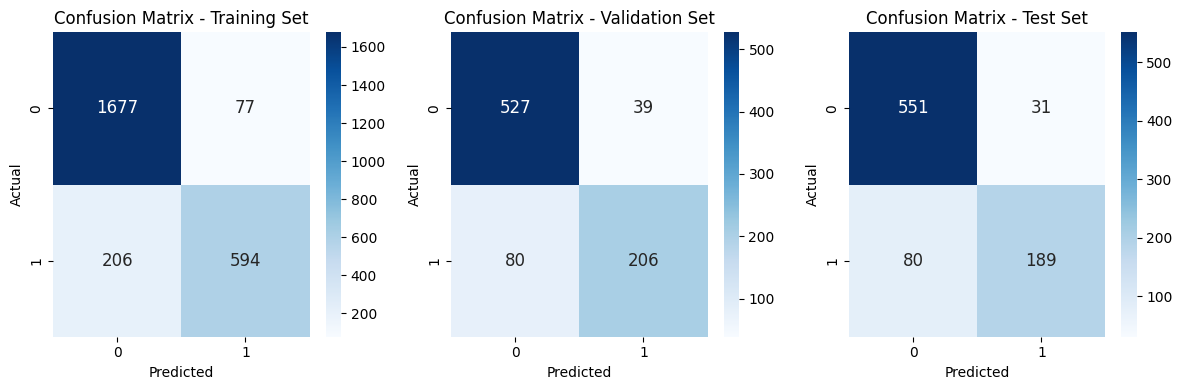

In [120]:
# Calculate confusion matrix for the training set
cm_train_significant = confusion_matrix(y_train, y_train_pred_significant)
print("Confusion Matrix - Training Set:")
print(cm_train_significant)

# Calculate confusion matrix for the validation set
cm_val_significant = confusion_matrix(y_val, y_val_pred_significant)
print("\nConfusion Matrix - Validation Set:")
print(cm_val_significant)

# Calculate confusion matrix for the test set
cm_test_significant = confusion_matrix(y_test, y_test_pred_significant)
print("\nConfusion Matrix - Test Set:")
print(cm_test_significant)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(
    cm_train_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    annot_kws={"size": 12},
)
axes[0].set_title("Confusion Matrix - Training Set")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_val_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    annot_kws={"size": 12},
)
axes[1].set_title("Confusion Matrix - Validation Set")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(
    cm_test_significant,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[2],
    annot_kws={"size": 12},
)
axes[2].set_title("Confusion Matrix - Test Set")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [121]:
# Store in a table to review later
results_lm_significant = pd.DataFrame(
    {
        "Accuracy": [
            metrics.accuracy_score(y_train, y_train_pred_significant),
            metrics.accuracy_score(y_val, y_val_pred_significant),
            metrics.accuracy_score(y_test, y_test_pred_significant),
        ],
        "Precision": [
            metrics.precision_score(y_train, y_train_pred_significant),
            metrics.precision_score(y_val, y_val_pred_significant),
            metrics.precision_score(y_test, y_test_pred_significant),
        ],
        "Recall": [
            metrics.recall_score(y_train, y_train_pred_significant),
            metrics.recall_score(y_val, y_val_pred_significant),
            metrics.recall_score(y_test, y_test_pred_significant),
        ],
        "F1 Score": [
            metrics.f1_score(y_train, y_train_pred_significant),
            metrics.f1_score(y_val, y_val_pred_significant),
            metrics.f1_score(y_test, y_test_pred_significant),
        ],
    },
    index=["Train", "Validation", "Test"],
)

results_lm_significant = round(results_lm_significant, 4)

print("Results using significant variables only\n")
display(results_lm_significant)

Results using significant variables only



,Accuracy,Precision,Recall,F1 Score
Train,0.8892,0.8852,0.7425,0.8076
Validation,0.8603,0.8408,0.7203,0.7759
Test,0.8696,0.8591,0.7026,0.7730


In [122]:
# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred_significant))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred_significant))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred_significant))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1754
           1       0.89      0.74      0.81       800

    accuracy                           0.89      2554
   macro avg       0.89      0.85      0.86      2554
weighted avg       0.89      0.89      0.89      2554


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       566
           1       0.84      0.72      0.78       286

    accuracy                           0.86       852
   macro avg       0.85      0.83      0.84       852
weighted avg       0.86      0.86      0.86       852


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91       582
           1       0.86      0.70      0.77       269

    accuracy                           0.87       851
   macro avg  

### Lift Curve

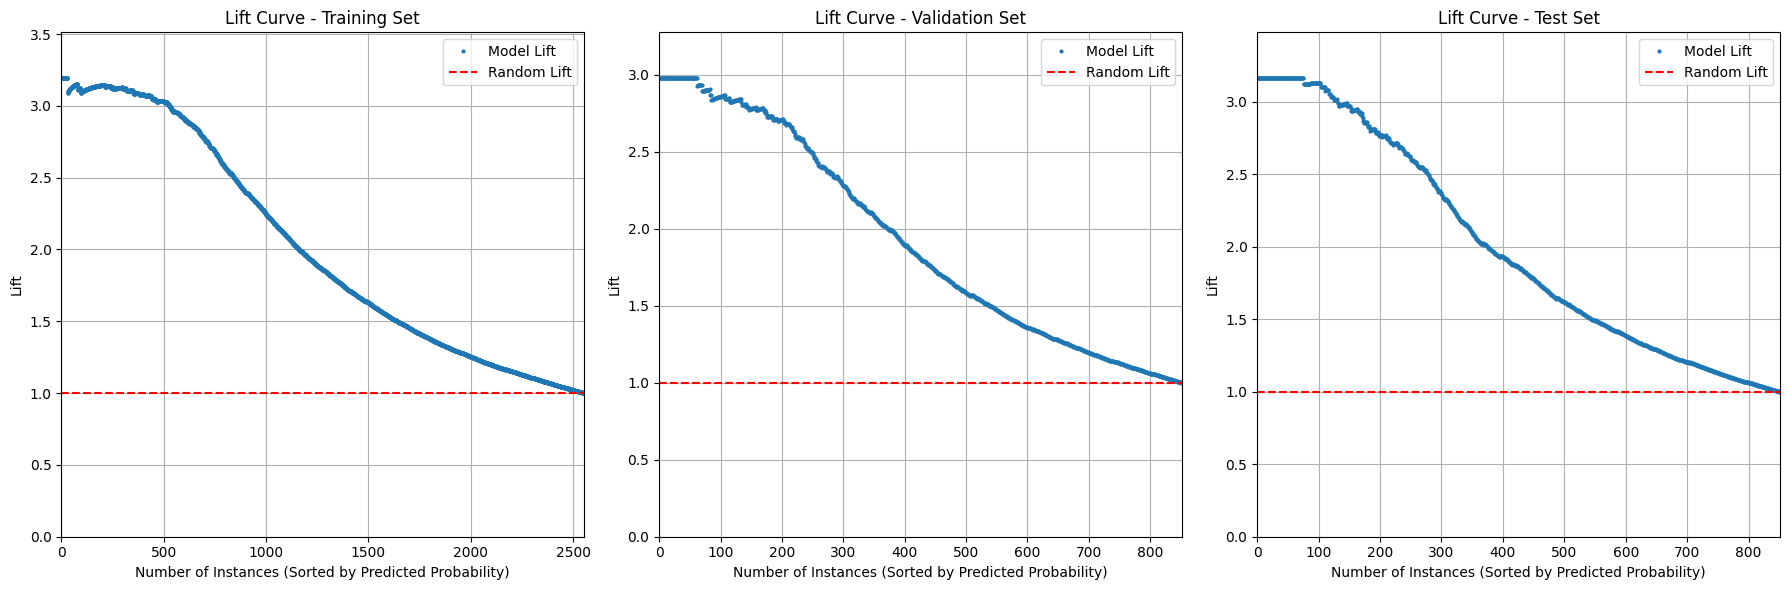

In [123]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_significant_proba, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_significant_proba, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_significant_proba, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

### ROC Curve + AUC

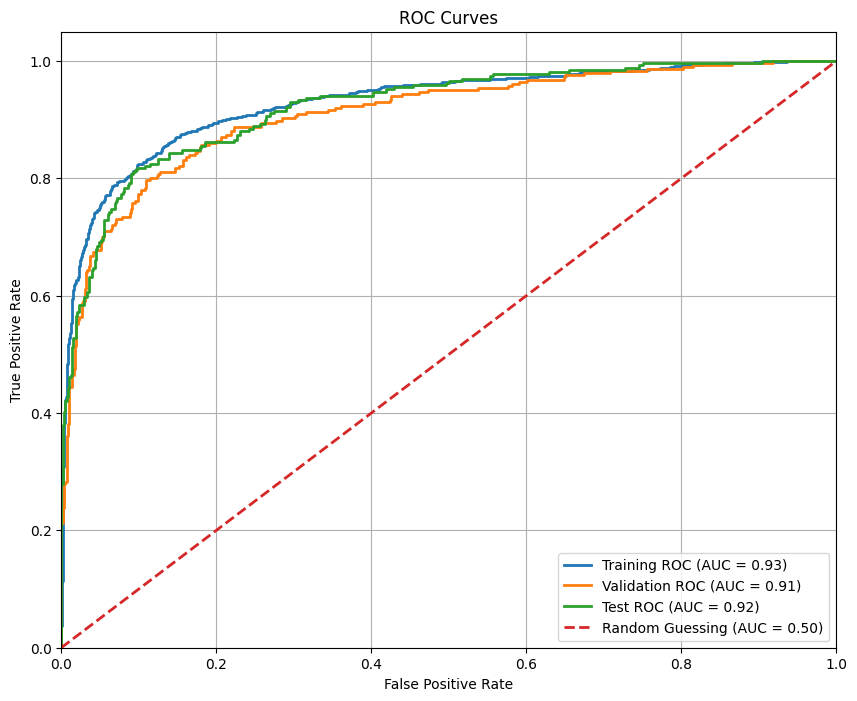


AUC Scores:
  Training AUC:   0.9301
  Validation AUC: 0.9105
  Test AUC:       0.9226


In [124]:
plot_roc_auc(
    y_train,
    y_val,
    y_test,
    y_train_significant_proba,
    y_val_significant_proba,
    y_test_significant_proba,
)

### Significant Features

In [125]:
# Convert boolean columns to integers (0s and 1s) for statsmodels
X_train_significant_sm = X_train_significant.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_significant_sm = sm.add_constant(X_train_significant_sm)

# Fit the logistic regression model using statsmodels
logit_model_significant = sm.Logit(y_train, X_train_significant_sm)
result_significant = logit_model_significant.fit()

# Show the model summary, which includes p-values
print(result_significant.summary())

Optimization terminated successfully.
         Current function value: 0.327505
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                 2554
Model:                          Logit   Df Residuals:                     2525
Method:                           MLE   Df Model:                           28
Date:                Sat, 20 Dec 2025   Pseudo R-squ.:                  0.4732
Time:                        16:03:03   Log-Likelihood:                -836.45
converged:                       True   LL-Null:                       -1587.7
Covariance Type:            nonrobust   LLR p-value:                2.095e-299
                                                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

After dropping insignificant variables in the first iteration, a few additional variables were found to be insignificant. While some specific sub-categories became insignificant, others within the same category remained significant, so the category was retained. (Note: significance assessed at p < .05)

In [126]:
result_significant.pvalues[result.pvalues < 0.05].index.astype(str).str.split("_").str[
    0
].unique().to_list()

['Admission grade',
 'Curricular units 1st sem (approved)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Unemployment rate',
 'Application mode',
 'Course',
 'Daytime/evening attendance\t',
 'Previous qualification',
 "Father's qualification",
 "Mother's occupation",
 'Displaced',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder']

These were the significant variables after removing insignificant variables in the model at the .05 level.

## Logistic Regression Model (with interaction term)

### Train the Model

In [127]:
# Create the interaction term Admission grade * Scholarship holder_yes
X_train["admissionxscholarship"] = (
    X_train["Admission grade"] * X_train["Scholarship holder_yes"]
)
X_val["admissionxscholarship"] = (
    X_val["Admission grade"] * X_val["Scholarship holder_yes"]
)
X_test["admissionxscholarship"] = (
    X_test["Admission grade"] * X_test["Scholarship holder_yes"]
)

cols_to_keep = cols_to_keep + ["admissionxscholarship"]

An interaction term between admission grade and scholarship is included to examine how the relationship between academic preparedness and graduation may differ depending on whether a student receives financial support through a scholarship.

In [128]:
X_train_significant_interact = X_train[cols_to_keep]
X_val_significant_interact = X_val[cols_to_keep]
X_test_significant_interact = X_test[cols_to_keep]

In [129]:
# fit the model
logistic_model = LogisticRegression(
    random_state=42, max_iter=5000
)  # Increased max_iter for convergence
logistic_model.fit(X_train_significant_interact, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [130]:
# Make predictions (classes) on the training, validation, and test sets
y_train_pred_significant_interact = logistic_model.predict(X_train_significant_interact)
y_val_pred_significant_interact = logistic_model.predict(X_val_significant_interact)
y_test_pred_significant_interact = logistic_model.predict(X_test_significant_interact)

# Get predicted probabilities for the training, validation, and test sets
y_train_significant_proba_interact = logistic_model.predict_proba(
    X_train_significant_interact
)[
    :, 1
]  # Probability of the positive class (1)
y_val_significant_proba_interact = logistic_model.predict_proba(
    X_val_significant_interact
)[:, 1]
y_test_significant_proba_interact = logistic_model.predict_proba(
    X_test_significant_interact
)[:, 1]

print(
    "Predictions (classes and probabilities) made successfully on training, validation, and test sets."
)

Predictions (classes and probabilities) made successfully on training, validation, and test sets.


### Model Performance

Confusion Matrix - Training Set:
[[1678   76]
 [ 204  596]]

Confusion Matrix - Validation Set:
[[527  39]
 [ 80 206]]

Confusion Matrix - Test Set:
[[551  31]
 [ 79 190]]


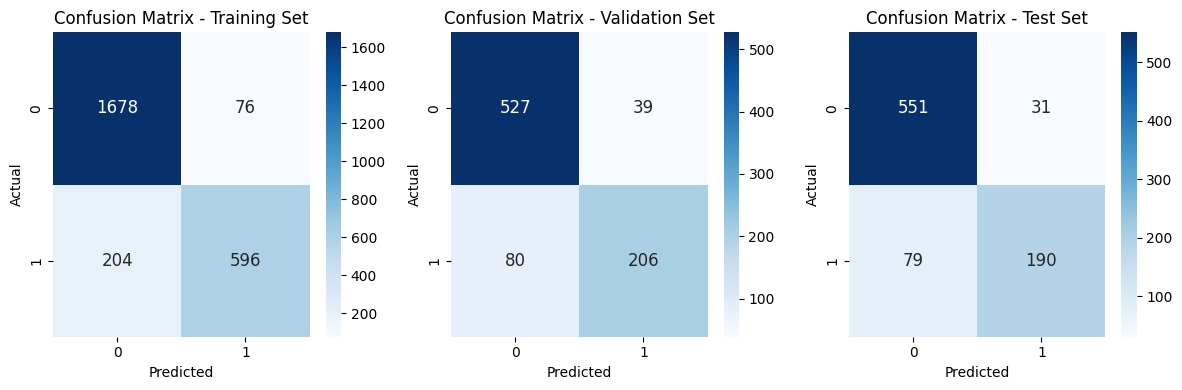

In [131]:
# Calculate confusion matrix for the training set
cm_train_significant_interact = confusion_matrix(
    y_train, y_train_pred_significant_interact
)
print("Confusion Matrix - Training Set:")
print(cm_train_significant_interact)

# Calculate confusion matrix for the validation set
cm_val_significant_interact = confusion_matrix(y_val, y_val_pred_significant_interact)
print("\nConfusion Matrix - Validation Set:")
print(cm_val_significant_interact)

# Calculate confusion matrix for the test set
cm_test_significant_interact = confusion_matrix(
    y_test, y_test_pred_significant_interact
)
print("\nConfusion Matrix - Test Set:")
print(cm_test_significant_interact)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(
    cm_train_significant_interact,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    annot_kws={"size": 12},
)
axes[0].set_title("Confusion Matrix - Training Set")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_val_significant_interact,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    annot_kws={"size": 12},
)
axes[1].set_title("Confusion Matrix - Validation Set")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(
    cm_test_significant_interact,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[2],
    annot_kws={"size": 12},
)
axes[2].set_title("Confusion Matrix - Test Set")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [132]:
# COMMENTING OUT TO FORMAT RESULTS IN A TABLE WE CAN REFERENCE LATER

# # Check model performance by partition with total accuracy
# print("Train Accuracy:", accuracy_score(y_train, y_train_pred_significant))
# print("Validation Accuracy:", accuracy_score(y_val, y_val_pred_significant))
# print("Test Accuracy:", accuracy_score(y_test, y_test_pred_significant))

# # Check model performance by partition with precision
# print("\n")
# print("Train Precision:", metrics.precision_score(y_train, y_train_pred_significant))
# print("Validation Precision:", metrics.precision_score(y_val, y_val_pred_significant))
# print("Test Precision:", metrics.precision_score(y_test, y_test_pred_significant))

# # Check model performance by partition with recall
# print("\n")
# print("Train Recall:", metrics.recall_score(y_train, y_train_pred_significant))
# print("Validation Recall:", metrics.recall_score(y_val, y_val_pred_significant))
# print("Test Recall:", metrics.recall_score(y_test, y_test_pred_significant))

# # Check model performance by partition with F1 Score
# print("\n")
# print("Train F1 Score:", metrics.f1_score(y_train, y_train_pred_significant))
# print("Validation F1 Score:", metrics.f1_score(y_val, y_val_pred_significant))
# print("Test F1 Score:", metrics.f1_score(y_test, y_test_pred_significant))

In [133]:
# Store in a table to review later
results_lm_significant_interact = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_significant_interact),
            accuracy_score(y_val, y_val_pred_significant_interact),
            metrics.accuracy_score(y_test, y_test_pred_significant_interact),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_significant_interact),
            precision_score(y_val, y_val_pred_significant_interact),
            precision_score(y_test, y_test_pred_significant_interact),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_significant_interact),
            recall_score(y_val, y_val_pred_significant_interact),
            recall_score(y_test, y_test_pred_significant_interact),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_significant_interact),
            f1_score(y_val, y_val_pred_significant_interact),
            f1_score(y_test, y_test_pred_significant_interact),
        ],
    },
    index=["Train", "Validation", "Test"],
)

results_lm_significant_interact = round(results_lm_significant_interact, 4)

print("Results using significant variables only\n")
display(results_lm_significant_interact)

Results using significant variables only



,Accuracy,Precision,Recall,F1 Score
Train,0.8904,0.8869,0.7450,0.8098
Validation,0.8603,0.8408,0.7203,0.7759
Test,0.8707,0.8597,0.7063,0.7755


The same pattern shows as before, the performance metrics barely changed.

In [134]:
# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred_significant_interact))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred_significant_interact))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred_significant_interact))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1754
           1       0.89      0.74      0.81       800

    accuracy                           0.89      2554
   macro avg       0.89      0.85      0.87      2554
weighted avg       0.89      0.89      0.89      2554


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90       566
           1       0.84      0.72      0.78       286

    accuracy                           0.86       852
   macro avg       0.85      0.83      0.84       852
weighted avg       0.86      0.86      0.86       852


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.87      0.95      0.91       582
           1       0.86      0.71      0.78       269

    accuracy                           0.87       851
   macro avg  

### Lift Curve

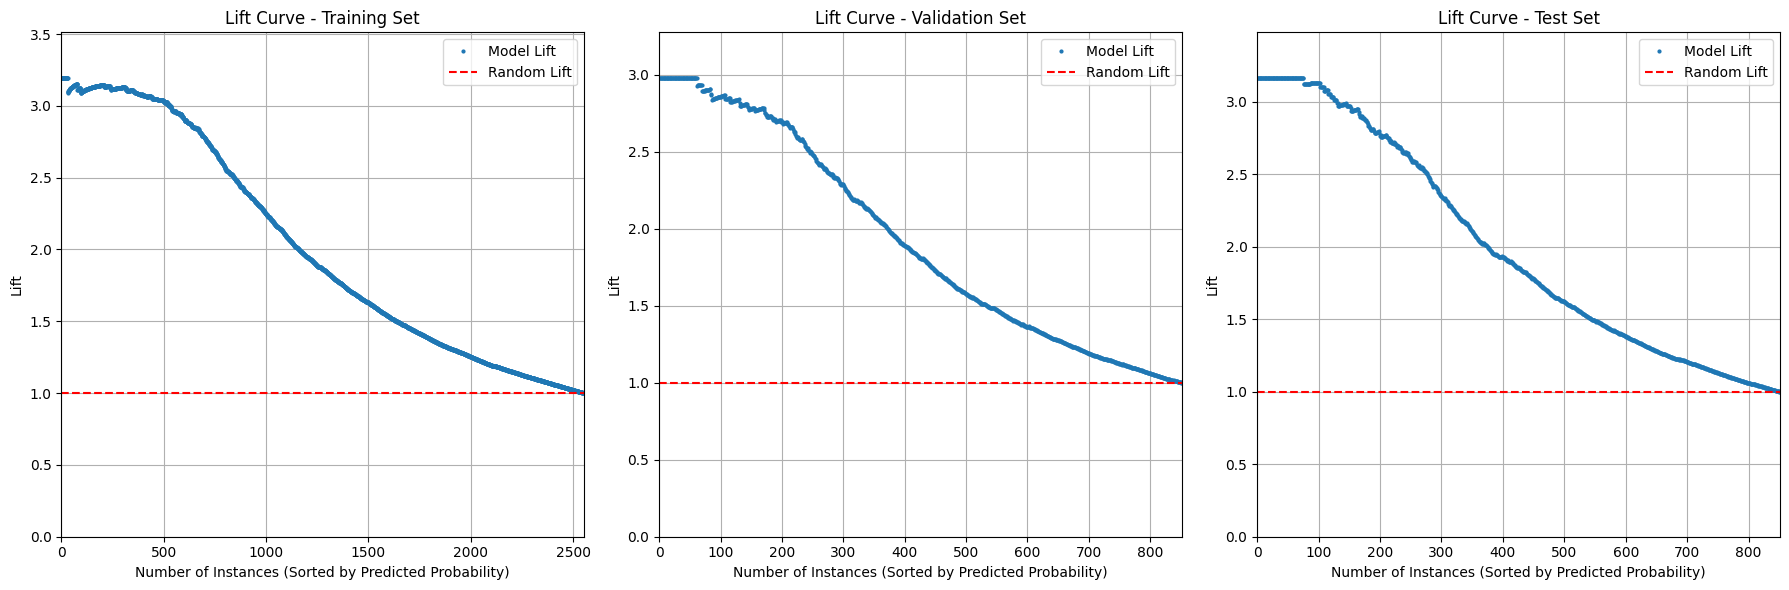

In [135]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(
    y_train, y_train_significant_proba_interact, "Lift Curve - Training Set"
)

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_significant_proba_interact, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_significant_proba_interact, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

### ROC Curve + AUC

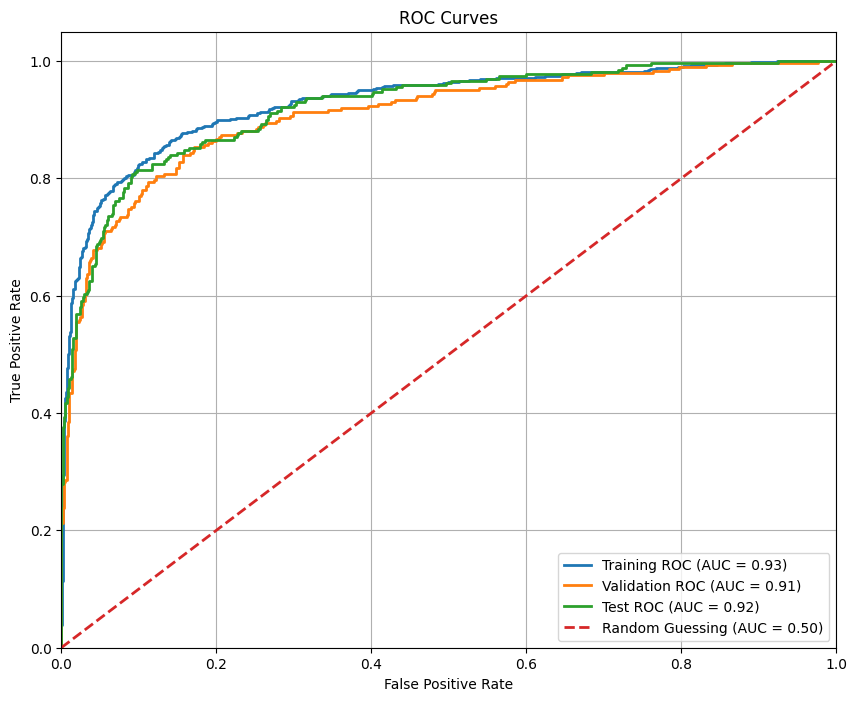


AUC Scores:
  Training AUC:   0.9301
  Validation AUC: 0.9090
  Test AUC:       0.9217


In [136]:
plot_roc_auc(
    y_train,
    y_val,
    y_test,
    y_train_significant_proba_interact,
    y_val_significant_proba_interact,
    y_test_significant_proba_interact,
)

### Significant Features

In [137]:
# Convert boolean columns to integers (0s and 1s) for statsmodels
X_train_significant_interact_sm = X_train_significant_interact.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_significant_interact_sm = sm.add_constant(X_train_significant_interact_sm)

# Fit the logistic regression model using statsmodels
logit_model_significant_interact = sm.Logit(y_train, X_train_significant_interact_sm)
result_significant_interact = logit_model_significant_interact.fit()

# Show the model summary, which includes p-values
print(result_significant_interact.summary())

Optimization terminated successfully.
         Current function value: 0.327407
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                 2554
Model:                          Logit   Df Residuals:                     2524
Method:                           MLE   Df Model:                           29
Date:                Sat, 20 Dec 2025   Pseudo R-squ.:                  0.4733
Time:                        16:03:04   Log-Likelihood:                -836.20
converged:                       True   LL-Null:                       -1587.7
Covariance Type:            nonrobust   LLR p-value:                1.213e-298
                                                                                                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------

The new term "admissionxscholarship" was not significant at the p < .05 level.

In [138]:
# Show the results tables for all 3
print("Performance metrics: Standard Model")
display(results_lm)
print("\n")
print("Performance metrics: Significant Terms Only")
display(results_lm_significant)
print("\n")
print("Performance metrics: Significant Terms + Interaction Term")
display(results_lm_significant_interact)

Performance metrics: Standard Model


,Accuracy,Precision,Recall,F1 Score
Train,0.8900,0.8891,0.7412,0.8085
Validation,0.8650,0.8490,0.7273,0.7834
Test,0.8766,0.8694,0.7175,0.7862




Performance metrics: Significant Terms Only


,Accuracy,Precision,Recall,F1 Score
Train,0.8892,0.8852,0.7425,0.8076
Validation,0.8603,0.8408,0.7203,0.7759
Test,0.8696,0.8591,0.7026,0.7730




Performance metrics: Significant Terms + Interaction Term


,Accuracy,Precision,Recall,F1 Score
Train,0.8904,0.8869,0.7450,0.8098
Validation,0.8603,0.8408,0.7203,0.7759
Test,0.8707,0.8597,0.7063,0.7755


After rerunning the model with only significant terms, no substantial improvement was observed compared to the previous standard model. The addition of interaction terms also did not meaningfully enhance performance, likely because the relationships in the dataset are not complex enough for these terms to provide additional predictive value. Furthermore, subsequent iterations failing to yield improvements suggests that consistent recoding and category consolidation during preprocessing effectively simplified the dataset. Interestingly, contrary to initial expectations, Nationality was found to be a significant factor influencing the outcome despite limited variability among classes.

## Decision Tree

### Train the model

In [139]:
# Train the model using a grid search and using the best parameters
param_grid_dt = {
    "max_depth": range(2, 21),
    "min_samples_split": range(2, 21),
    "min_samples_leaf": range(1, 11),
}

# Instantiate GridSearchCV
grid_search_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=1856845),
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

grid_search_dt.fit(X_train, y_train)

# Print best hyperparameters and best F1 score
print("Best hyperparameters for Random Forest:", grid_search_dt.best_params_)
print(f"Best cross-validation F1 score: {grid_search_dt.best_score_:.4f}")

Best hyperparameters for Random Forest: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 11}
Best cross-validation F1 score: 0.7550


In [140]:
best_params_dt = grid_search_dt.best_params_
dt_model = DecisionTreeClassifier(**best_params_dt, random_state=1856845)
dt_model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",11
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",1856845
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

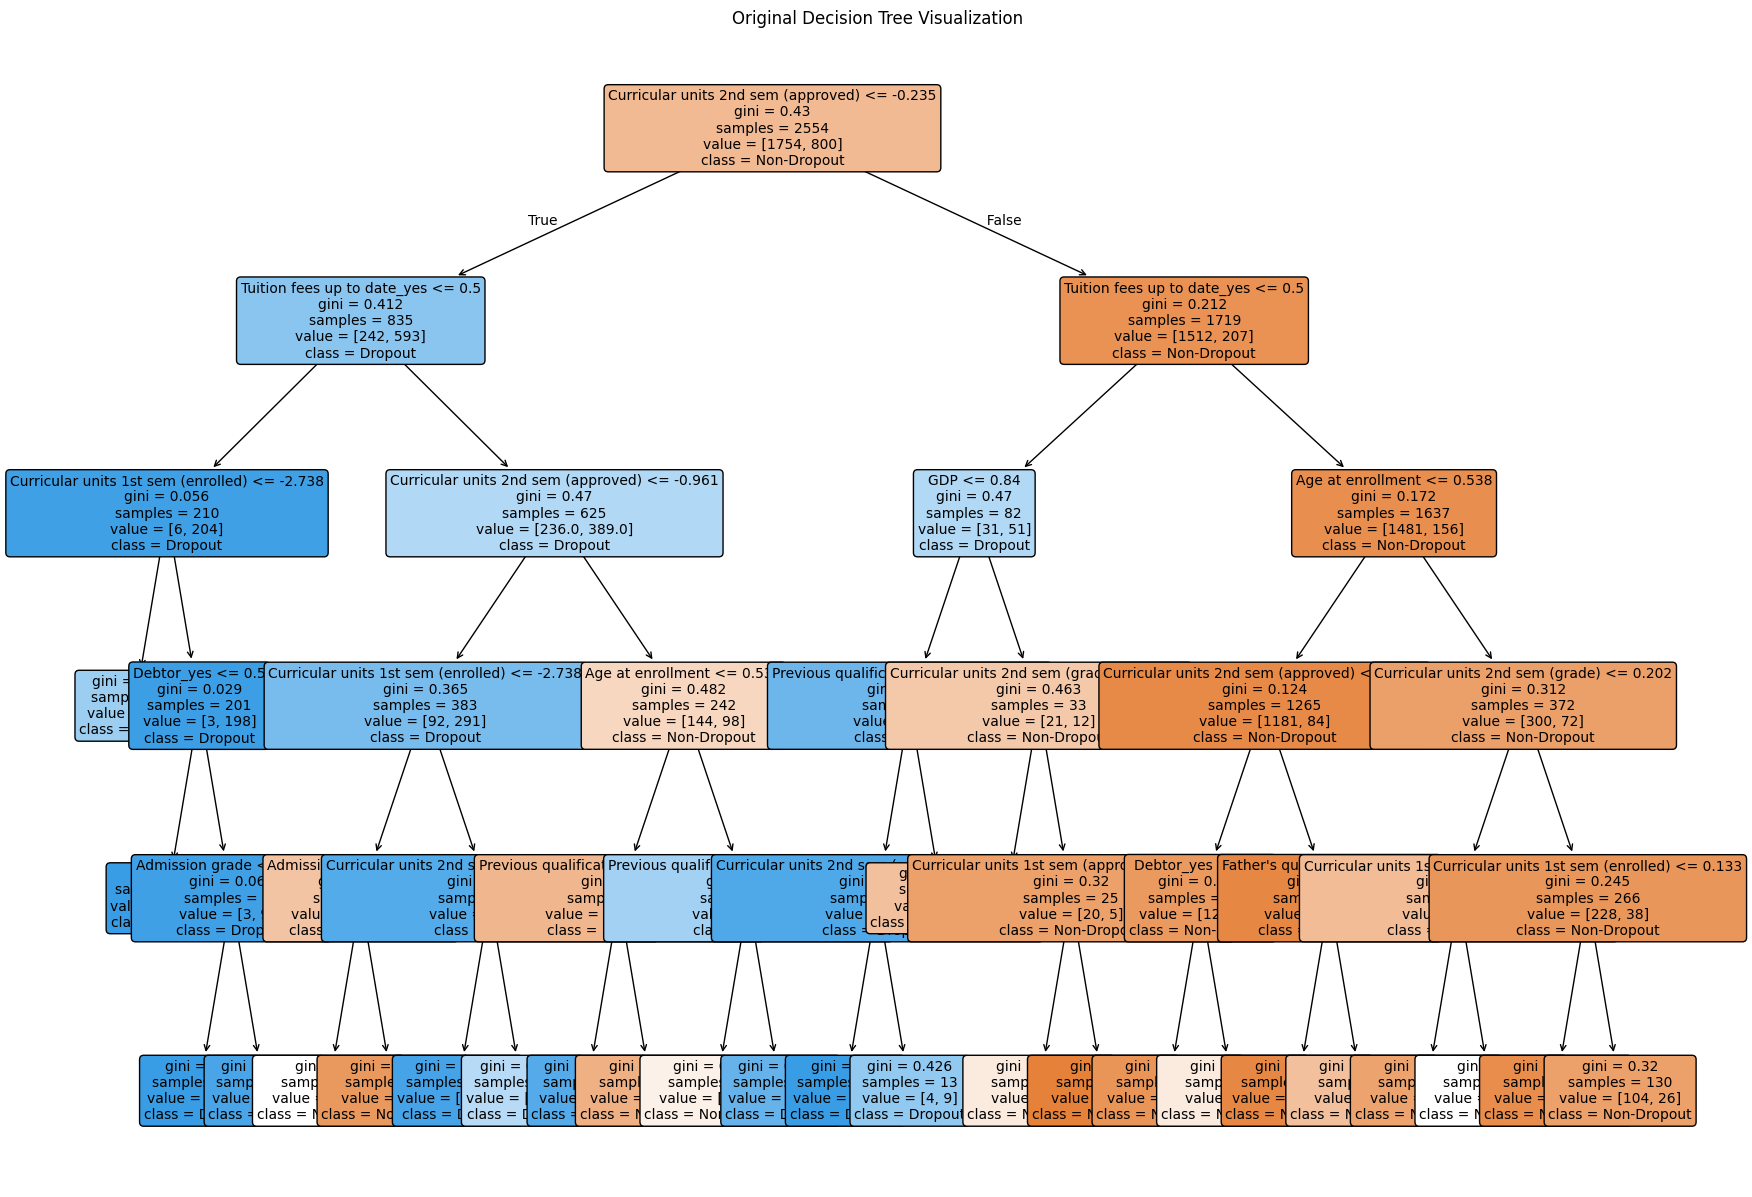

In [141]:
# Set the figure size for better visualization
plt.figure(figsize=(20, 15))

# Plot the original decision tree
plot_tree(
    dt_model,
    feature_names=list(X_train.columns),  # Use feature names from the training data
    class_names=["Non-Dropout", "Dropout"],  # Use meaningful class names
    filled=True,  # Color nodes to indicate the majority class
    rounded=True,  # Round node corners
    fontsize=10,
)  # Adjust font size for readability

plt.title("Original Decision Tree Visualization")
plt.show()

In [142]:
# The number of splits in a decision tree is the number of internal nodes.
# This is equal to the total number of nodes minus the number of leaf nodes.
# We can access the tree structure from the tuned_dt_model.tree_ attribute.

tree_ = dt_model.tree_
total_nodes = tree_.node_count
leaf_nodes = tree_.n_leaves

number_of_splits = total_nodes - leaf_nodes

print(f"The decision tree has {number_of_splits} splits (internal nodes).")
print(f"The decision tree has {leaf_nodes} leaves.")

The decision tree has 25 splits (internal nodes).
The decision tree has 26 leaves.


### Evaluate Model Performance

In [143]:
# Predictions on training set
y_train_pred_dt = dt_model.predict(X_train)
cm_train_dt = confusion_matrix(y_train, y_train_pred_dt)

# Predictions on validation set
y_val_pred_dt = dt_model.predict(X_val)
cm_val_dt = confusion_matrix(y_val, y_val_pred_dt)

# Predictions on test set
y_test_pred_dt = dt_model.predict(X_test)
cm_test_dt = confusion_matrix(y_test, y_test_pred_dt)

print("Confusion Matrix - Training Set:")
print(cm_train_dt)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_dt)

print("\nConfusion Matrix - Test Set:")
print(cm_test_dt)

Confusion Matrix - Training Set:
[[1699   55]
 [ 254  546]]

Confusion Matrix - Validation Set:
[[535  31]
 [ 86 200]]

Confusion Matrix - Test Set:
[[561  21]
 [ 98 171]]


In [144]:
# Create a table of the metrics
results_dt = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_dt),
            accuracy_score(y_val, y_val_pred_dt),
            accuracy_score(y_test, y_test_pred_dt),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_dt),
            precision_score(y_val, y_val_pred_dt),
            precision_score(y_test, y_test_pred_dt),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_dt),
            recall_score(y_val, y_val_pred_dt),
            recall_score(y_test, y_test_pred_dt),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_dt),
            f1_score(y_val, y_val_pred_dt),
            f1_score(y_test, y_test_pred_dt),
        ],
    },
    index=["Training_dt", "Validation_dt", "Test_dt"],
).round(4)

display(results_dt)

,Accuracy,Precision,Recall,F1 Score
Training_dt,0.8790,0.9085,0.6825,0.7794
Validation_dt,0.8627,0.8658,0.6993,0.7737
Test_dt,0.8602,0.8906,0.6357,0.7419


### Lift Curve

In [145]:
# Calculate probabilities
y_train_proba_dt = dt_model.predict_proba(X_train)[:, 1]
y_val_proba_dt = dt_model.predict_proba(X_val)[:, 1]
y_test_proba_dt = dt_model.predict_proba(X_test)[:, 1]

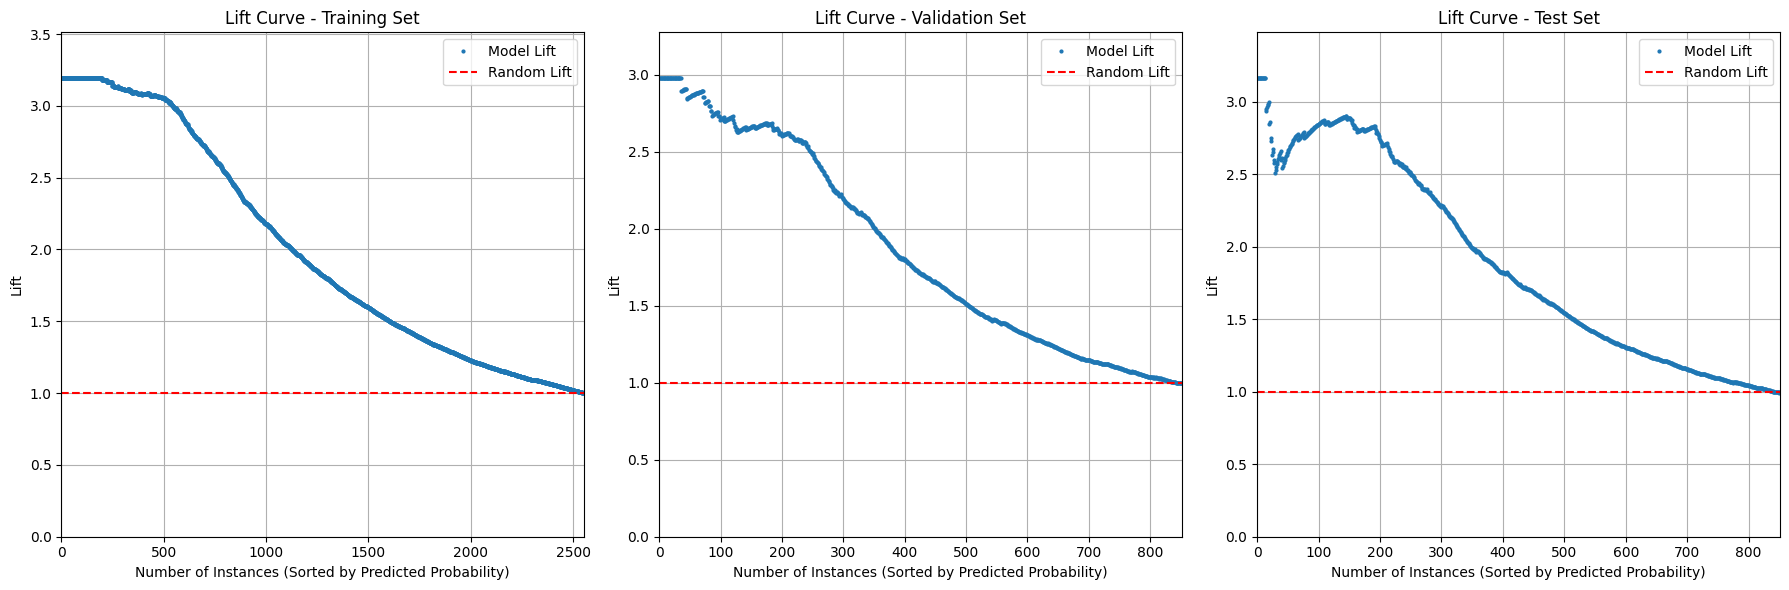

In [146]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_dt, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_dt, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_dt, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

This model lift curve indicates that in each of the cases (training, validation, and test) this model is ~3x better at predicting positives accurately compared to a random lift.

### ROC Curve + AUC

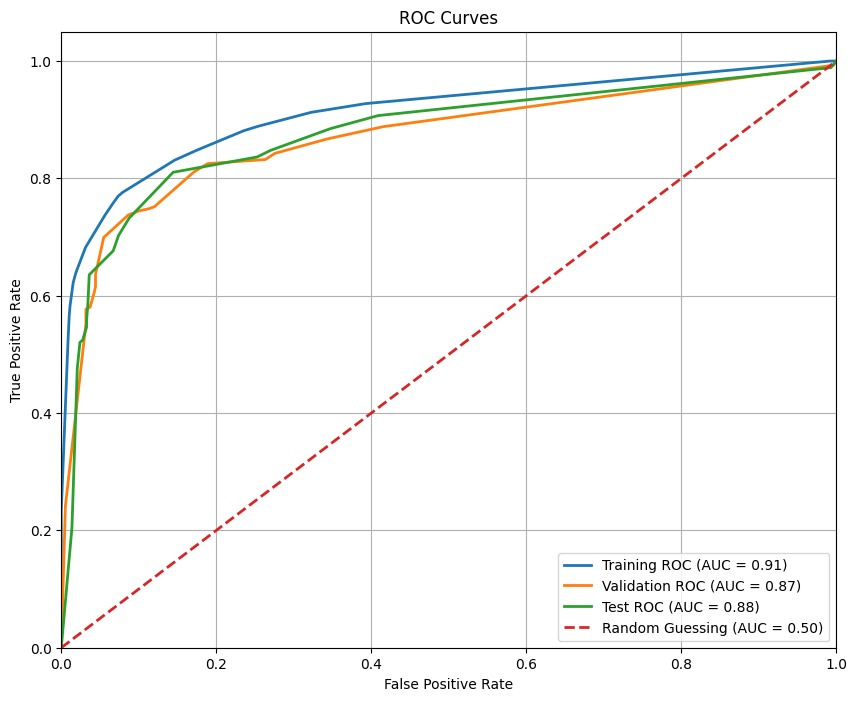


AUC Scores:
  Training AUC:   0.9113
  Validation AUC: 0.8709
  Test AUC:       0.8773


In [147]:
plot_roc_auc(y_train, y_val, y_test, y_train_proba_dt, y_val_proba_dt, y_test_proba_dt)

### Feature Importances

In [148]:
# Get the feature importances from the tuned regression tree model
feature_importances_dt = dt_model.feature_importances_

# Get the feature names from the training data
feature_names = X_train.columns

# Create a pandas Series to easily view feature importances with their names
feature_importance_series = pd.Series(feature_importances_dt, index=feature_names)

# Sort the feature importances in descending order
feature_importances_dt = feature_importance_series.sort_values(ascending=False)

# Print the sorted feature importances
print(feature_importances_dt)

Curricular units 2nd sem (approved)                                                                                                  0.697800
Tuition fees up to date_yes                                                                                                          0.128733
Curricular units 1st sem (enrolled)                                                                                                  0.064459
Age at enrollment                                                                                                                    0.034517
Previous qualification (grade)                                                                                                       0.022944
Curricular units 2nd sem (grade)                                                                                                     0.016278
GDP                                                                                                                                  0.011625
Admiss

## Boosted Tree

### Train the model

In [149]:
# Train the model using a grid search and using the best parameters
param_grid_gbc = {
    "n_estimators": [100, 200],
    "learning_rate": [0.01, 0.1],
    "max_depth": [3, 4],
    "min_samples_split": [2, 5],
}


# Instantiate GridSearchCV
grid_search_gbc = GridSearchCV(
    GradientBoostingClassifier(random_state=1856845),
    param_grid=param_grid_gbc,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

grid_search_gbc.fit(X_train, y_train)

# Print best hyperparameters and best F1 score
print("Best hyperparameters for Random Forest:", grid_search_gbc.best_params_)
print(f"Best cross-validation F1 score: {grid_search_gbc.best_score_:.4f}")

Best hyperparameters for Random Forest: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validation F1 score: 0.7960


In [150]:
best_params_gbc = grid_search_gbc.best_params_
gbc_model = GradientBoostingClassifier(**best_params_gbc, random_state=1856845)
gbc_model.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

### Evaluate Model Performance

In [151]:
# Predictions on training set
y_train_pred_gbc = gbc_model.predict(X_train)
cm_train_gbc = confusion_matrix(y_train, y_train_pred_gbc)

# Predictions on validation set
y_val_pred_gbc = gbc_model.predict(X_val)
cm_val_gbc = confusion_matrix(y_val, y_val_pred_gbc)

# Predictions on test set
y_test_pred_gbc = gbc_model.predict(X_test)
cm_test_gbc = confusion_matrix(y_test, y_test_pred_gbc)

print("Confusion Matrix - Training Set:")
print(cm_train_gbc)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_gbc)

print("\nConfusion Matrix - Test Set:")
print(cm_test_gbc)

Confusion Matrix - Training Set:
[[1724   30]
 [ 120  680]]

Confusion Matrix - Validation Set:
[[525  41]
 [ 75 211]]

Confusion Matrix - Test Set:
[[551  31]
 [ 75 194]]


In [152]:
# Create a table of the metrics
results_gbc = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_gbc),
            accuracy_score(y_val, y_val_pred_gbc),
            accuracy_score(y_test, y_test_pred_gbc),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_gbc),
            precision_score(y_val, y_val_pred_gbc),
            precision_score(y_test, y_test_pred_gbc),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_gbc),
            recall_score(y_val, y_val_pred_gbc),
            recall_score(y_test, y_test_pred_gbc),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_gbc),
            f1_score(y_val, y_val_pred_gbc),
            f1_score(y_test, y_test_pred_gbc),
        ],
    },
    index=["Training_gbc", "Validation_gbc", "Test_gbc"],
).round(4)

display(results_gbc)

,Accuracy,Precision,Recall,F1 Score
Training_gbc,0.9413,0.9577,0.8500,0.9007
Validation_gbc,0.8638,0.8373,0.7378,0.7844
Test_gbc,0.8754,0.8622,0.7212,0.7854


### Lift Curve

In [153]:
# Calculate probabilities
y_train_proba_gbc = gbc_model.predict_proba(X_train)[:, 1]
y_val_proba_gbc = gbc_model.predict_proba(X_val)[:, 1]
y_test_proba_gbc = gbc_model.predict_proba(X_test)[:, 1]

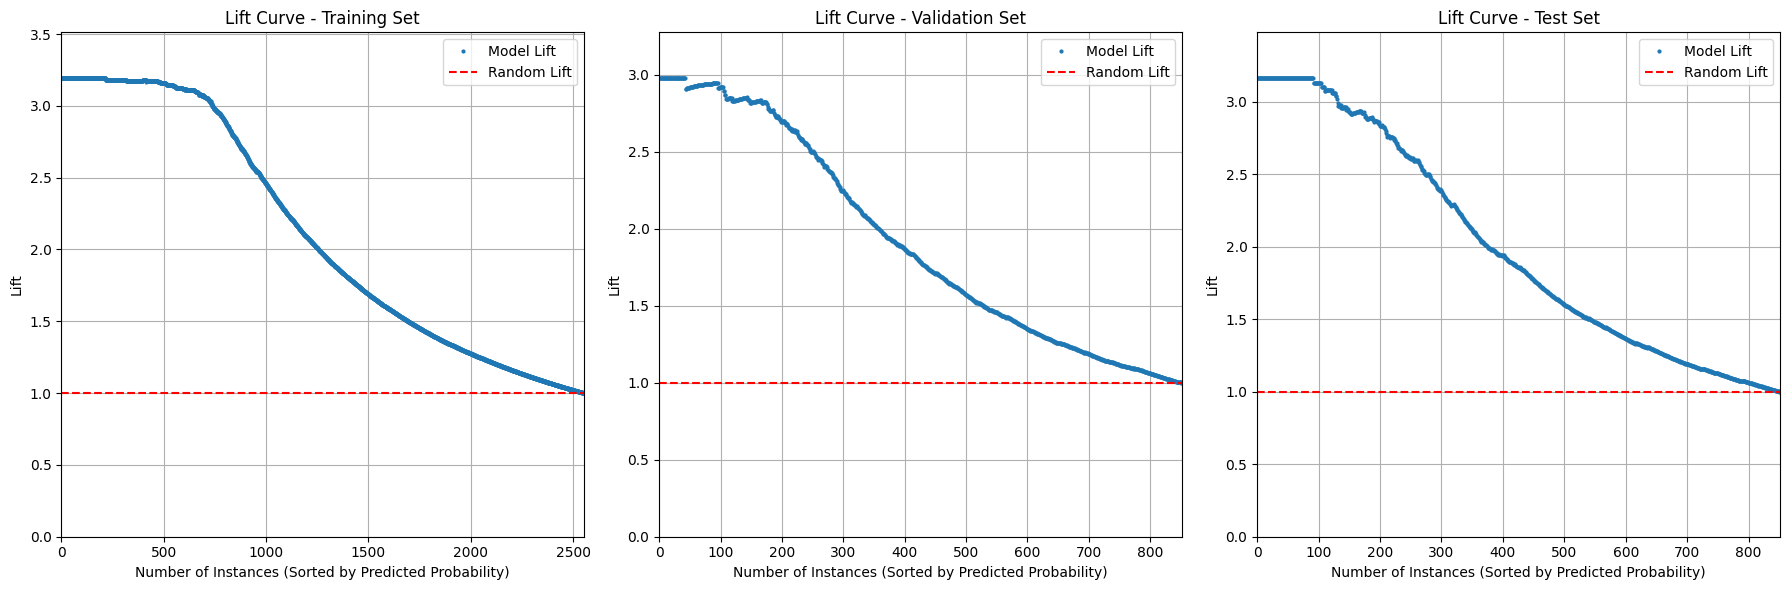

In [154]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_gbc, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_gbc, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_gbc, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

These three lift curves indicate a strong ability for the boosted tree model to make accurate predictions compared to preciting randomly.

### ROC Curve + AUC

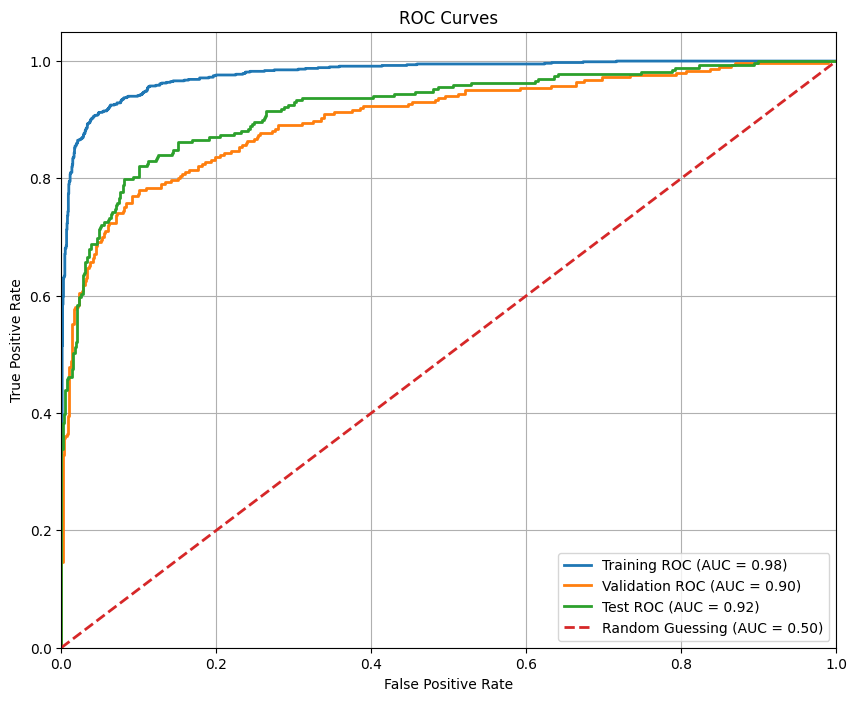


AUC Scores:
  Training AUC:   0.9797
  Validation AUC: 0.9021
  Test AUC:       0.9204


In [155]:
plot_roc_auc(
    y_train, y_val, y_test, y_train_proba_gbc, y_val_proba_gbc, y_test_proba_gbc
)

### Feature Importances

In [156]:
# Get the feature importances from the tuned regression tree model
feature_importances_gbc = gbc_model.feature_importances_

# Get the feature names from the training data
feature_names = X_train.columns

# Create a pandas Series to easily view feature importances with their names
feature_importance_series = pd.Series(feature_importances_gbc, index=feature_names)

# Sort the feature importances in descending order
feature_importances_gbc = feature_importance_series.sort_values(ascending=False)

# Print the sorted feature importances
print(feature_importances_gbc)

Curricular units 2nd sem (approved)                                                                                                  5.288055e-01
Tuition fees up to date_yes                                                                                                          1.025971e-01
Age at enrollment                                                                                                                    4.923389e-02
Curricular units 2nd sem (grade)                                                                                                     4.201734e-02
Curricular units 1st sem (approved)                                                                                                  3.484383e-02
Curricular units 1st sem (enrolled)                                                                                                  3.061087e-02
Curricular units 2nd sem (enrolled)                                                                                         

## Bootstrap Forest (Random Forest)

### Train the model

In [157]:
# Train the model using a grid search and using the best parameters
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [15, 20, 25],
}

# Make the scorer
f1_scorer = make_scorer(f1_score)

# Instantiate GridSearchCV
grid_search_rf = GridSearchCV(
    RandomForestClassifier(random_state=1856845),
    param_grid=param_grid_rf,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1,
)

grid_search_rf.fit(X_train, y_train)

# Print best hyperparameters and best F1 score
print("Best hyperparameters for Random Forest:", grid_search_rf.best_params_)
print(f"Best cross-validation F1 score: {grid_search_rf.best_score_:.4f}")

Best hyperparameters for Random Forest: {'max_depth': 20, 'min_samples_split': 20, 'n_estimators': 200}
Best cross-validation F1 score: 0.7794


In [158]:
best_params_rf = grid_search_rf.best_params_
rf_model = RandomForestClassifier(**best_params_rf, random_state=1856845)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

### Evaluate Model Performance

In [159]:
# Predictions on training set
y_train_pred_rf = rf_model.predict(X_train)
cm_train_rf = confusion_matrix(y_train, y_train_pred_rf)

# Predictions on validation set
y_val_pred_rf = rf_model.predict(X_val)
cm_val_rf = confusion_matrix(y_val, y_val_pred_rf)

# Predictions on test set
y_test_pred_rf = rf_model.predict(X_test)
cm_test_rf = confusion_matrix(y_test, y_test_pred_rf)

print("Confusion Matrix - Training Set:")
print(cm_train_rf)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_rf)

print("\nConfusion Matrix - Test Set:")
print(cm_test_rf)

Confusion Matrix - Training Set:
[[1718   36]
 [ 163  637]]

Confusion Matrix - Validation Set:
[[531  35]
 [ 83 203]]

Confusion Matrix - Test Set:
[[555  27]
 [ 85 184]]


In [160]:
# Create a table of the metrics
results_rf = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_rf),
            accuracy_score(y_val, y_val_pred_rf),
            accuracy_score(y_test, y_test_pred_rf),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_rf),
            precision_score(y_val, y_val_pred_rf),
            precision_score(y_test, y_test_pred_rf),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_rf),
            recall_score(y_val, y_val_pred_rf),
            recall_score(y_test, y_test_pred_rf),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_rf),
            f1_score(y_val, y_val_pred_rf),
            f1_score(y_test, y_test_pred_rf),
        ],
    },
    index=["Training_rf", "Validation_rf", "Test_rf"],
).round(4)

display(results_rf)

,Accuracy,Precision,Recall,F1 Score
Training_rf,0.9221,0.9465,0.7962,0.8649
Validation_rf,0.8615,0.8529,0.7098,0.7748
Test_rf,0.8684,0.8720,0.6840,0.7667


### Lift Curve

In [161]:
# Calculate probabilities
y_train_proba_rf = rf_model.predict_proba(X_train)[:, 1]
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

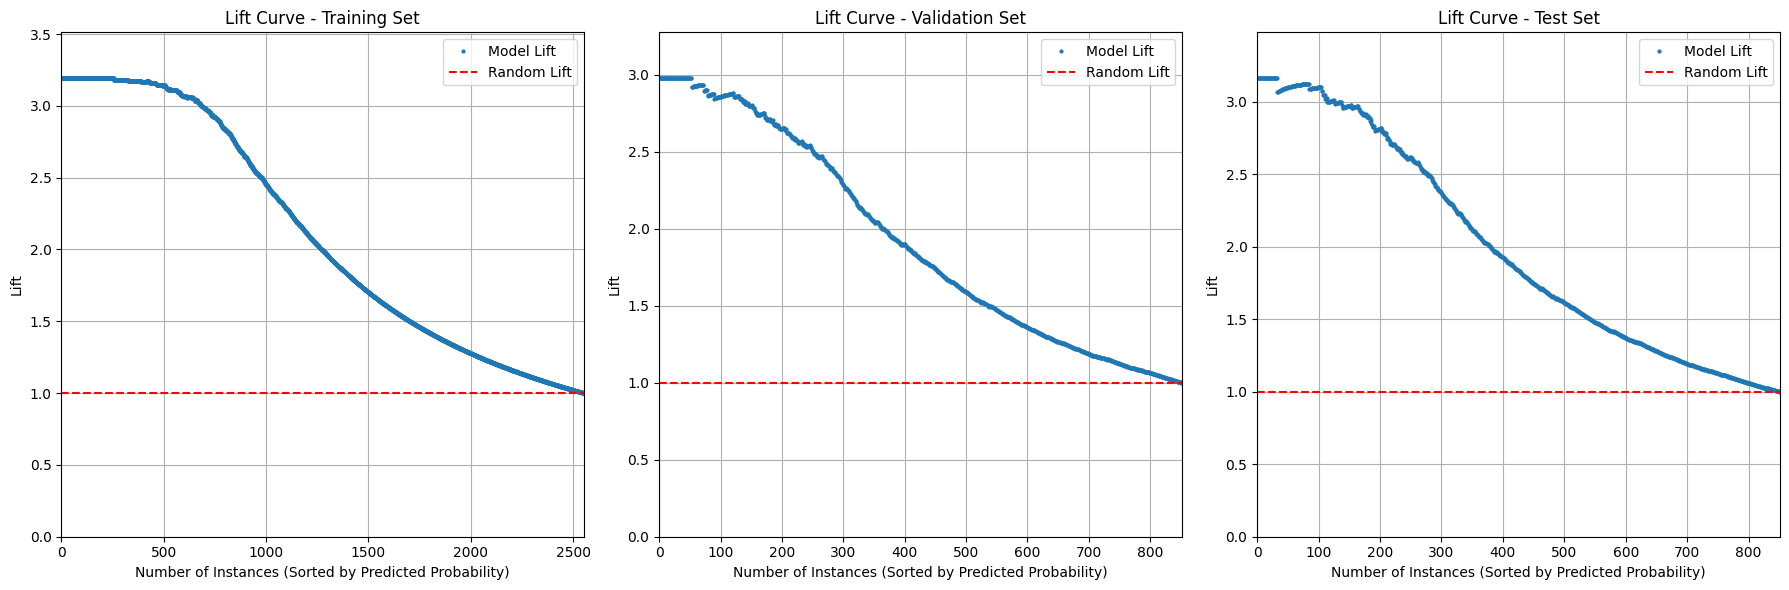

In [162]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_rf, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_rf, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_rf, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

### ROC Curve + AUC

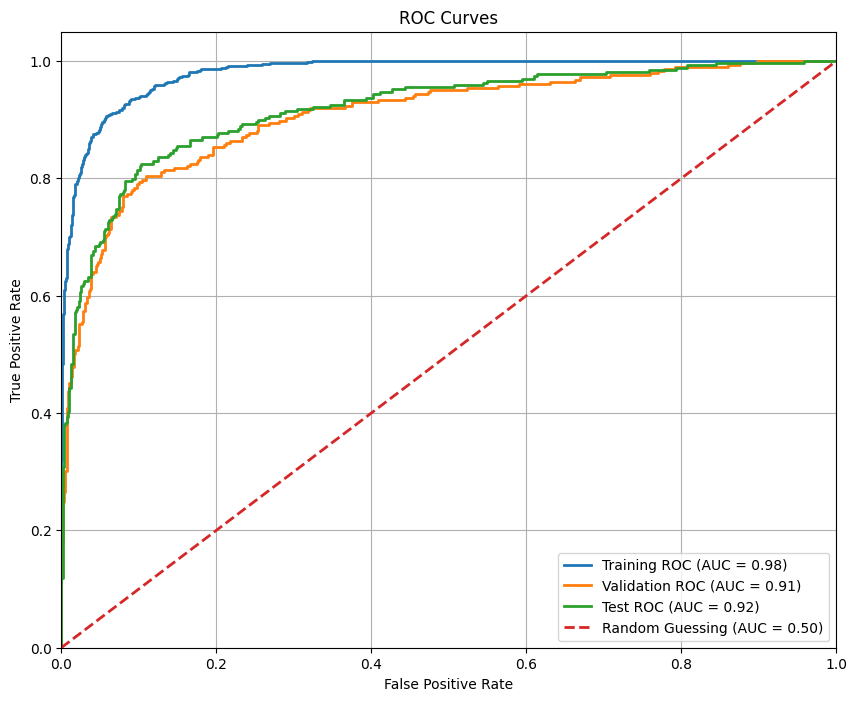


AUC Scores:
  Training AUC:   0.9807
  Validation AUC: 0.9079
  Test AUC:       0.9192


In [163]:
plot_roc_auc(y_train, y_val, y_test, y_train_proba_rf, y_val_proba_rf, y_test_proba_rf)

### Feature Importances

In [164]:
# Get the feature importances from the tuned regression tree model
feature_importances_rf = rf_model.feature_importances_

# Get the feature names from the training data
feature_names = X_train.columns

# Create a pandas Series to easily view feature importances with their names
feature_importance_series = pd.Series(feature_importances_rf, index=feature_names)

# Sort the feature importances in descending order
feature_importances_rf = feature_importance_series.sort_values(ascending=False)

# Print the sorted feature importances
print(feature_importances_rf)

Curricular units 2nd sem (approved)                                                                                                  0.187543
Curricular units 2nd sem (grade)                                                                                                     0.143096
Curricular units 1st sem (approved)                                                                                                  0.111228
Curricular units 1st sem (grade)                                                                                                     0.085313
Tuition fees up to date_yes                                                                                                          0.078930
Age at enrollment                                                                                                                    0.043827
Curricular units 2nd sem (evaluations)                                                                                               0.036042
Curric

## Neural Network

### Train the model

In [165]:
# # Scale the features
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)
# X_test_scaled = scaler.transform(X_test)

# param_grid_nn = {
#     'hidden_layer_sizes': [(50,), (100,), (100, 50)],
#     'alpha': [0.0001, 0.001],
#     'learning_rate_init': [0.001, 0.01]
# }

# grid_search_nn = GridSearchCV(
#     MLPClassifier(max_iter=1000, random_state=1856845),
#     param_grid=param_grid_nn,
#     cv=5,
#     scoring="f1",
#     n_jobs=-1
# )

# grid_search_nn.fit(X_train_scaled, y_train)

# # Print results
# print("Best hyperparameters for NN:", grid_search_nn.best_params_)
# print(f"Best cross-validation F1 score: {grid_search_nn.best_score_:.4f}")

In [166]:
# best_params_nn = grid_search_nn.best_params_
# nn_model = MLPClassifier(**best_params_nn, random_state=1856845)
# nn_model.fit(X_train, y_train)

Fitting neural networks with hyperparameter tuning led to overfitting. Commenting out to fit manually.

In [167]:
# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

nn_model = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=2000,
    random_state=1856845,
    learning_rate_init=0.01,
)

nn_model.fit(X_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",1856845


### Evaluate Model Performance

In [168]:
# Predictions on training set
y_train_pred_nn = nn_model.predict(X_train)
cm_train_nn = confusion_matrix(y_train, y_train_pred_nn)

# Predictions on validation set
y_val_pred_nn = nn_model.predict(X_val)
cm_val_nn = confusion_matrix(y_val, y_val_pred_nn)

# Predictions on test set
y_test_pred_nn = nn_model.predict(X_test)
cm_test_nn = confusion_matrix(y_test, y_test_pred_nn)

print("Confusion Matrix - Training Set:")
print(cm_train_nn)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_nn)

print("\nConfusion Matrix - Test Set:")
print(cm_test_nn)

Confusion Matrix - Training Set:
[[1725   29]
 [ 323  477]]

Confusion Matrix - Validation Set:
[[540  26]
 [132 154]]

Confusion Matrix - Test Set:
[[558  24]
 [132 137]]


d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(


In [169]:
# Create a table of the metrics
results_nn = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_nn),
            accuracy_score(y_val, y_val_pred_nn),
            accuracy_score(y_test, y_test_pred_nn),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_nn),
            precision_score(y_val, y_val_pred_nn),
            precision_score(y_test, y_test_pred_nn),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_nn),
            recall_score(y_val, y_val_pred_nn),
            recall_score(y_test, y_test_pred_nn),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_nn),
            f1_score(y_val, y_val_pred_nn),
            f1_score(y_test, y_test_pred_nn),
        ],
    },
    index=["Training_nn", "Validation_nn", "Test_nn"],
).round(4)

display(results_nn)

,Accuracy,Precision,Recall,F1 Score
Training_nn,0.8622,0.9427,0.5962,0.7305
Validation_nn,0.8146,0.8556,0.5385,0.6609
Test_nn,0.8167,0.8509,0.5093,0.6372


### Lift Curve

In [170]:
# Calculate probabilities
y_train_proba_nn = nn_model.predict_proba(X_train)[:, 1]
y_val_proba_nn = nn_model.predict_proba(X_val)[:, 1]
y_test_proba_nn = nn_model.predict_proba(X_test)[:, 1]

d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
d:\Data Analytics Projects\predicting-student-dropout\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(


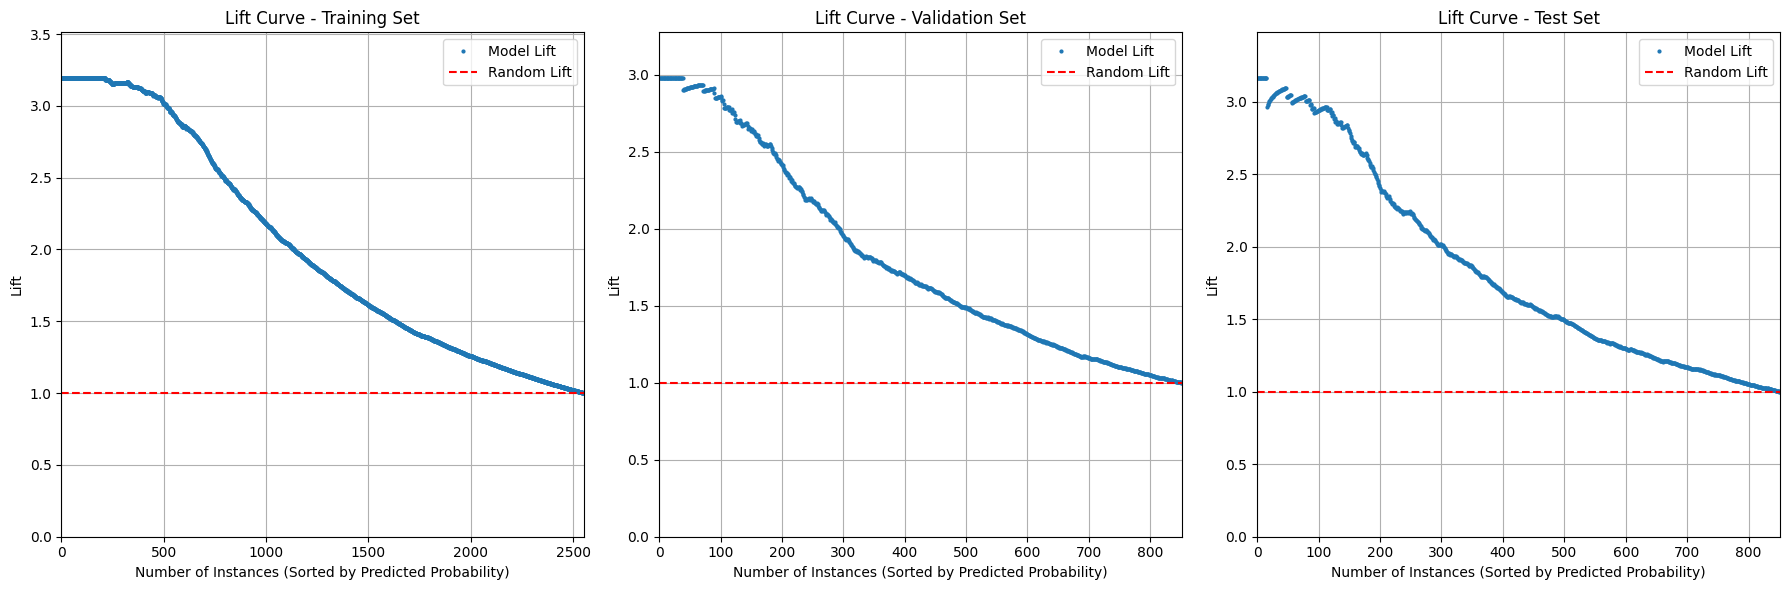

In [171]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_nn, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_nn, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_nn, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

The lift curve of the validation set is slightly lower for the neural network model. This could demonstrate some uncertainty in the model.

### ROC Curve + AUC

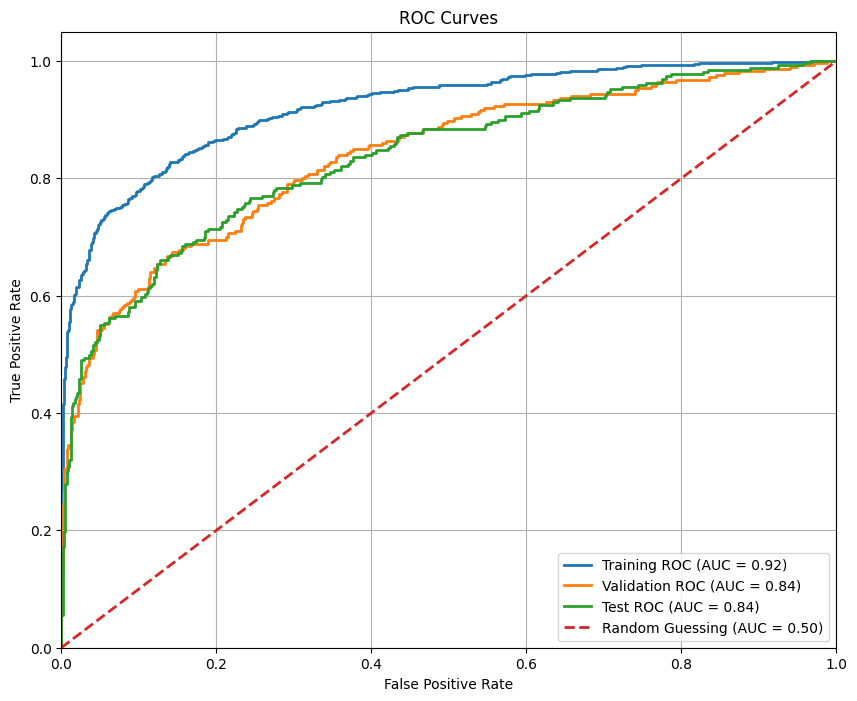


AUC Scores:
  Training AUC:   0.9214
  Validation AUC: 0.8377
  Test AUC:       0.8363


In [172]:
plot_roc_auc(y_train, y_val, y_test, y_train_proba_nn, y_val_proba_nn, y_test_proba_nn)

## Discriminant

### Train the model

In [173]:
# Initialize the LDA model
lda_model = LinearDiscriminantAnalysis()

# Train the model using the training data
lda_model.fit(X_train, y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


### Evaluate Model Performance

In [174]:
# Predictions on training set
y_train_pred_lda = lda_model.predict(X_train)
cm_train_lda = confusion_matrix(y_train, y_train_pred_lda)

# Predictions on validation set
y_val_pred_lda = lda_model.predict(X_val)
cm_val_lda = confusion_matrix(y_val, y_val_pred_lda)

# Predictions on test set
y_test_pred_lda = lda_model.predict(X_test)
cm_test_lda = confusion_matrix(y_test, y_test_pred_lda)

print("Confusion Matrix - Training Set:")
print(cm_train_lda)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_lda)

print("\nConfusion Matrix - Test Set:")
print(cm_test_lda)

Confusion Matrix - Training Set:
[[1691   63]
 [ 237  563]]

Confusion Matrix - Validation Set:
[[535  31]
 [ 88 198]]

Confusion Matrix - Test Set:
[[558  24]
 [ 87 182]]


In [175]:
# Create a table of the metrics
results_lda = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_lda),
            accuracy_score(y_val, y_val_pred_lda),
            accuracy_score(y_test, y_test_pred_lda),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_lda),
            precision_score(y_val, y_val_pred_lda),
            precision_score(y_test, y_test_pred_lda),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_lda),
            recall_score(y_val, y_val_pred_lda),
            recall_score(y_test, y_test_pred_lda),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_lda),
            f1_score(y_val, y_val_pred_lda),
            f1_score(y_test, y_test_pred_lda),
        ],
    },
    index=["Training_lda", "Validation_lda", "Test_lda"],
).round(4)

display(results_lda)

,Accuracy,Precision,Recall,F1 Score
Training_lda,0.8825,0.8994,0.7038,0.7896
Validation_lda,0.8603,0.8646,0.6923,0.7689
Test_lda,0.8696,0.8835,0.6766,0.7663


### Lift Curve

In [176]:
# Calculate probabilities
y_train_proba_lda = lda_model.predict_proba(X_train)[:, 1]
y_val_proba_lda = lda_model.predict_proba(X_val)[:, 1]
y_test_proba_lda = lda_model.predict_proba(X_test)[:, 1]

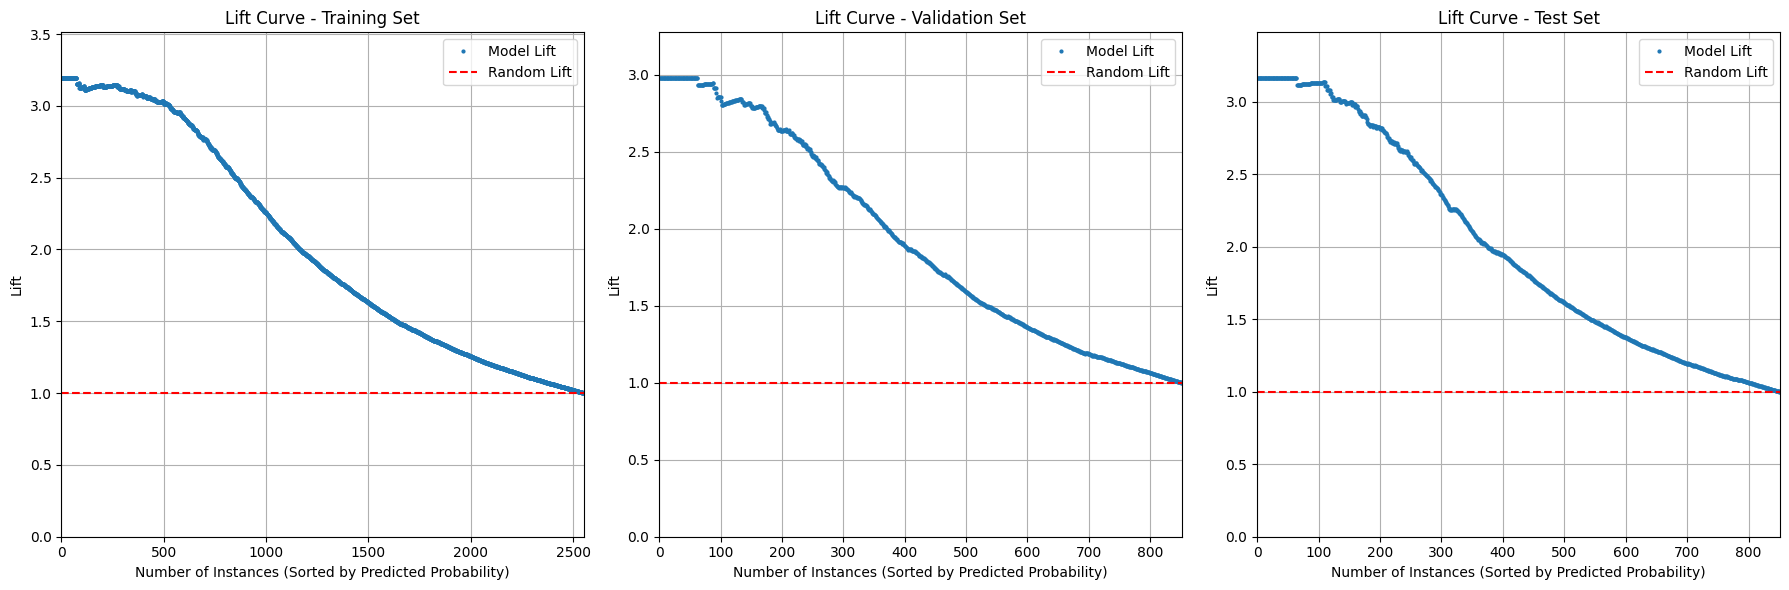

In [177]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_lda, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_lda, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_lda, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

The lift curve for validation and test reamained strong, which indicates there is little to no overfitting.

### ROC Curve + AUC

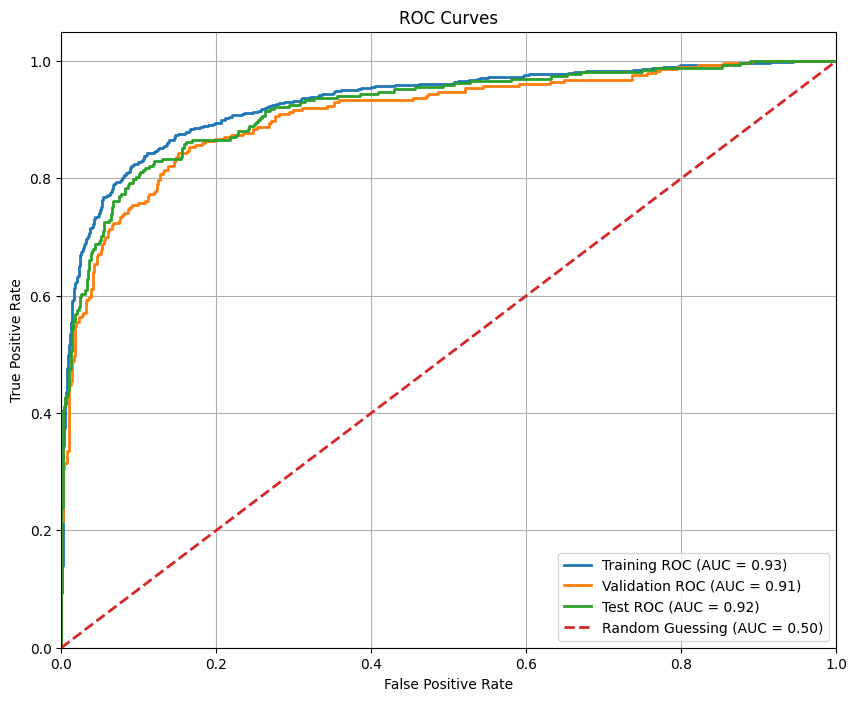


AUC Scores:
  Training AUC:   0.9316
  Validation AUC: 0.9089
  Test AUC:       0.9211


In [178]:
plot_roc_auc(
    y_train, y_val, y_test, y_train_proba_lda, y_val_proba_lda, y_test_proba_lda
)

## KNN

### Train the model

In [179]:
# Define a range of n_neighbors values to try
n_neighbors_range = range(1, 21)  # Example range from 1 to 20

# Create lists to store results
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

# Iterate through the range of n_neighbors values
for n in n_neighbors_range:
    # Initialize the KNN classifier with the current n_neighbors
    knn_classifier = KNeighborsClassifier(n_neighbors=n)

    # Train the model
    knn_classifier.fit(X_train, y_train)

    # Make predictions on the validation set
    y_pred_val = knn_classifier.predict(X_val)

    # Evaluate the model on the validation set
    accuracy = accuracy_score(y_val, y_pred_val)
    precision = precision_score(y_val, y_pred_val)
    recall = recall_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val)

    # Store the scores
    accuracy_scores.append(accuracy)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

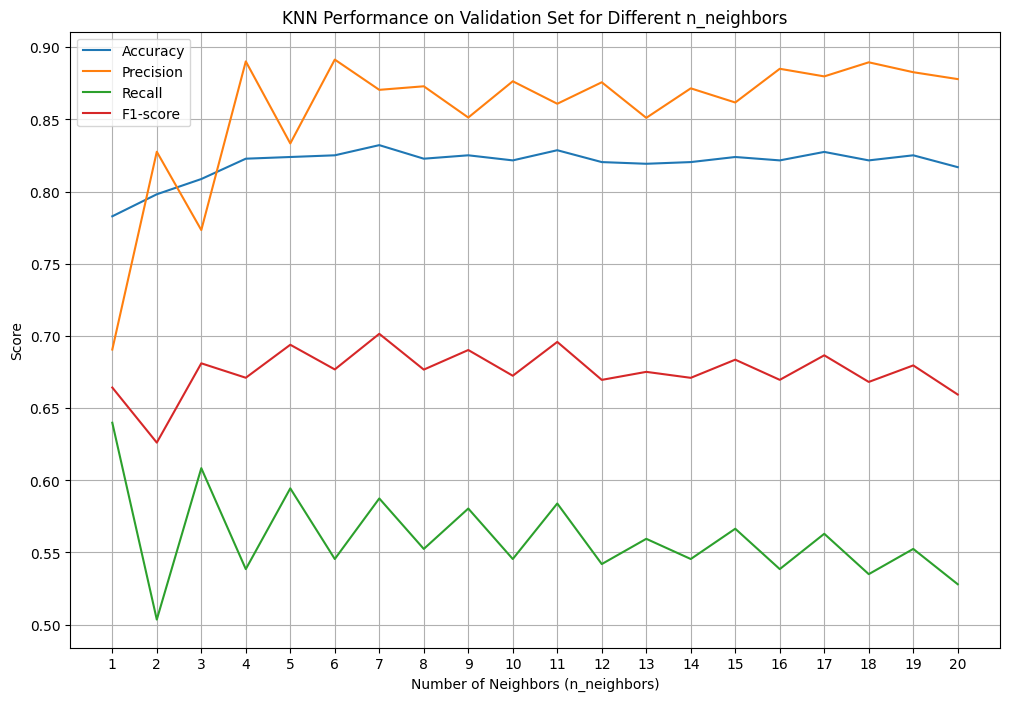

In [180]:
# Plot the performance metrics for each n_neighbors
plt.figure(figsize=(12, 8))

plt.plot(n_neighbors_range, accuracy_scores, label="Accuracy")
plt.plot(n_neighbors_range, precision_scores, label="Precision")
plt.plot(n_neighbors_range, recall_scores, label="Recall")
plt.plot(n_neighbors_range, f1_scores, label="F1-score")

plt.xlabel("Number of Neighbors (n_neighbors)")
plt.ylabel("Score")
plt.title("KNN Performance on Validation Set for Different n_neighbors")
plt.xticks(n_neighbors_range)
plt.legend()
plt.grid(True)
plt.show()
plt.show()

In [181]:
# Initialize the KNN classifier with n_neighbors=7
knn7_model = KNeighborsClassifier(n_neighbors=7)

# Train the model
knn7_model.fit(X_train, y_train)

# Make predictions on the validation set
y_pred_val_7 = knn7_model.predict(X_val)

### Evaluate Model Performance

In [182]:
# Predictions on training set
y_train_pred_knn7 = knn7_model.predict(X_train)
cm_train_knn7 = confusion_matrix(y_train, y_train_pred_knn7)

# Predictions on validation set
y_val_pred_knn7 = knn7_model.predict(X_val)
cm_val_knn7 = confusion_matrix(y_val, y_val_pred_knn7)

# Predictions on test set
y_test_pred_knn7 = knn7_model.predict(X_test)
cm_test_knn7 = confusion_matrix(y_test, y_test_pred_knn7)

print("Confusion Matrix - Training Set:")
print(cm_train_knn7)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_knn7)

print("\nConfusion Matrix - Test Set:")
print(cm_test_knn7)

Confusion Matrix - Training Set:
[[1696   58]
 [ 294  506]]

Confusion Matrix - Validation Set:
[[541  25]
 [118 168]]

Confusion Matrix - Test Set:
[[560  22]
 [116 153]]


In [183]:
# Create a table of the metrics
results_knn7 = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_knn7),
            accuracy_score(y_val, y_val_pred_knn7),
            accuracy_score(y_test, y_test_pred_knn7),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_knn7),
            precision_score(y_val, y_val_pred_knn7),
            precision_score(y_test, y_test_pred_knn7),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_knn7),
            recall_score(y_val, y_val_pred_knn7),
            recall_score(y_test, y_test_pred_knn7),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_knn7),
            f1_score(y_val, y_val_pred_knn7),
            f1_score(y_test, y_test_pred_knn7),
        ],
    },
    index=["Training_knn7", "Validation_knn7", "Test_knn7"],
).round(4)

display(results_knn7)

,Accuracy,Precision,Recall,F1 Score
Training_knn7,0.8622,0.8972,0.6325,0.7419
Validation_knn7,0.8322,0.8705,0.5874,0.7015
Test_knn7,0.8378,0.8743,0.5688,0.6892


### Lift Curve

In [184]:
# Calculate probabilities
y_train_proba_knn7 = knn7_model.predict_proba(X_train)[:, 1]
y_val_proba_knn7 = knn7_model.predict_proba(X_val)[:, 1]
y_test_proba_knn7 = knn7_model.predict_proba(X_test)[:, 1]

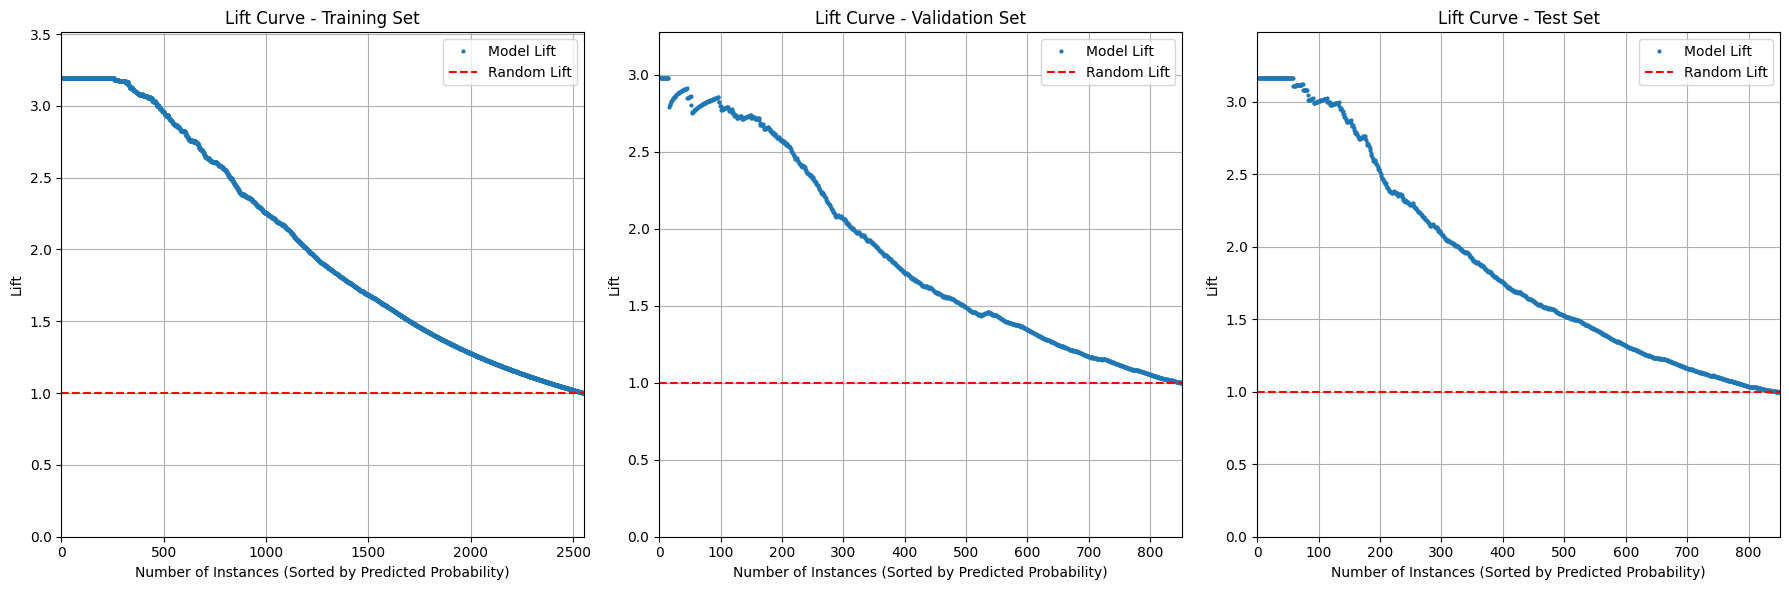

In [185]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_knn7, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_knn7, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_knn7, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

The lift curve in the KNN is extremely similar to that of the neural network, indicaing a similar ability to predict.

### ROC Curve + AUC

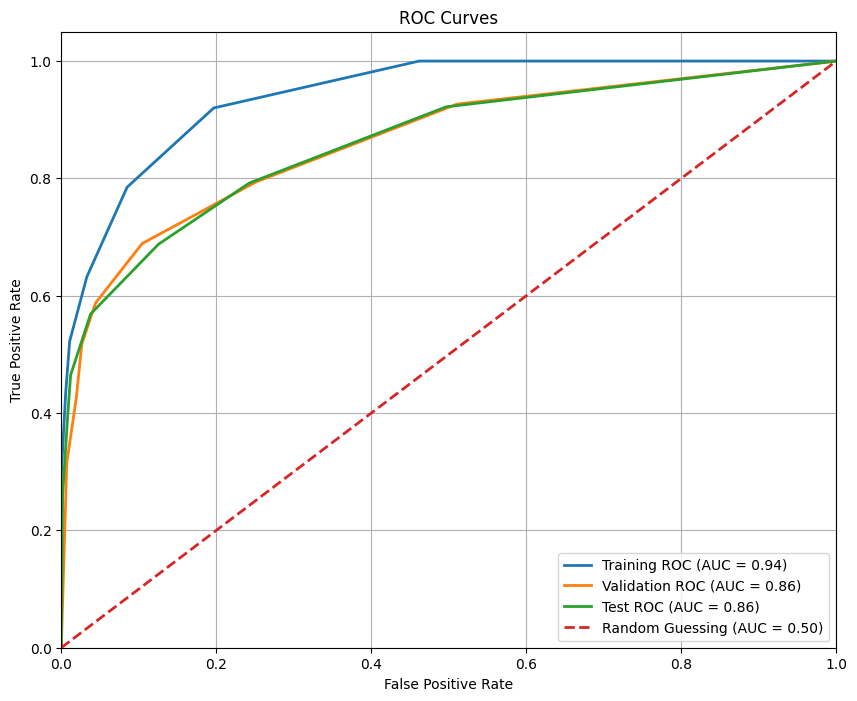


AUC Scores:
  Training AUC:   0.9421
  Validation AUC: 0.8606
  Test AUC:       0.8605


In [186]:
plot_roc_auc(
    y_train, y_val, y_test, y_train_proba_knn7, y_val_proba_knn7, y_test_proba_knn7
)

## Naive Bayes

### Train the model

In [187]:
# Initialize the Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model using the training data
gnb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


### Evaluate Model Performance

In [188]:
# Predictions on training set
y_train_pred_gnb = gnb_model.predict(X_train)
cm_train_gnb = confusion_matrix(y_train, y_train_pred_gnb)

# Predictions on validation set
y_val_pred_gnb = gnb_model.predict(X_val)
cm_val_gnb = confusion_matrix(y_val, y_val_pred_gnb)

# Predictions on test set
y_test_pred_gnb = gnb_model.predict(X_test)
cm_test_gnb = confusion_matrix(y_test, y_test_pred_gnb)

print("Confusion Matrix - Training Set:")
print(cm_train_gnb)

print("\nConfusion Matrix - Validation Set:")
print(cm_val_gnb)

print("\nConfusion Matrix - Test Set:")
print(cm_test_gnb)

Confusion Matrix - Training Set:
[[1448  306]
 [ 183  617]]

Confusion Matrix - Validation Set:
[[465 101]
 [ 70 216]]

Confusion Matrix - Test Set:
[[482 100]
 [ 63 206]]


In [189]:
# Create a table of the metrics
results_gnb = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_train, y_train_pred_gnb),
            accuracy_score(y_val, y_val_pred_gnb),
            accuracy_score(y_test, y_test_pred_gnb),
        ],
        "Precision": [
            precision_score(y_train, y_train_pred_gnb),
            precision_score(y_val, y_val_pred_gnb),
            precision_score(y_test, y_test_pred_gnb),
        ],
        "Recall": [
            recall_score(y_train, y_train_pred_gnb),
            recall_score(y_val, y_val_pred_gnb),
            recall_score(y_test, y_test_pred_gnb),
        ],
        "F1 Score": [
            f1_score(y_train, y_train_pred_gnb),
            f1_score(y_val, y_val_pred_gnb),
            f1_score(y_test, y_test_pred_gnb),
        ],
    },
    index=["Training_gnb", "Validation_gnb", "Test_gnb"],
).round(4)

display(results_gnb)

,Accuracy,Precision,Recall,F1 Score
Training_gnb,0.8085,0.6685,0.7712,0.7162
Validation_gnb,0.7993,0.6814,0.7552,0.7164
Test_gnb,0.8085,0.6732,0.7658,0.7165


### Lift Curve

In [190]:
# Calculate probabilities
y_train_proba_gnb = gnb_model.predict_proba(X_train)[:, 1]
y_val_proba_gnb = gnb_model.predict_proba(X_val)[:, 1]
y_test_proba_gnb = gnb_model.predict_proba(X_test)[:, 1]

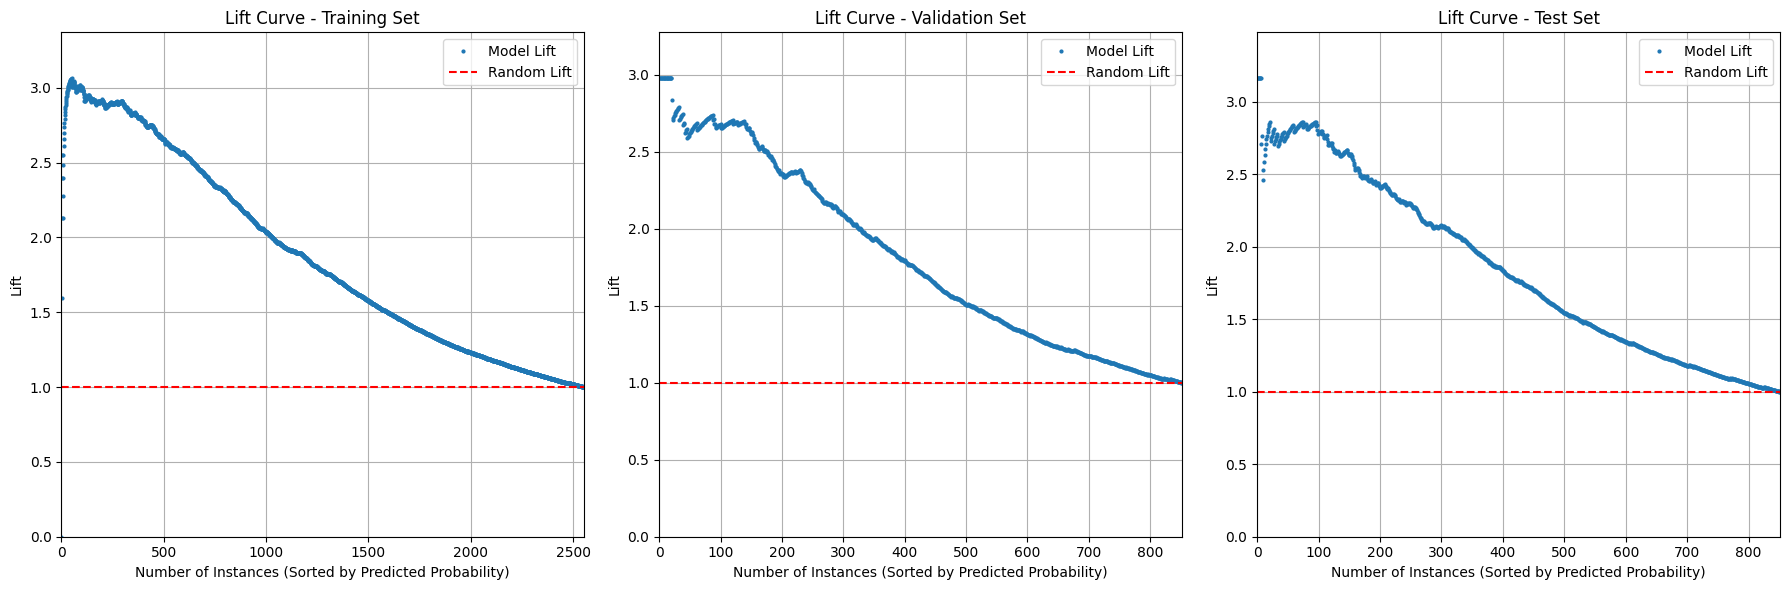

In [191]:
# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba_gnb, "Lift Curve - Training Set")

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba_gnb, "Lift Curve - Validation Set")

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba_gnb, "Lift Curve - Test Set")

plt.tight_layout()
plt.show()

The Naive Bayes curve performed the worst compared to random. Most models had the lift around 3 for a lower number of instances, where this model is closer to or below a lift of 2.5. This is likely due to overfitting.

### ROC Curve + AUC

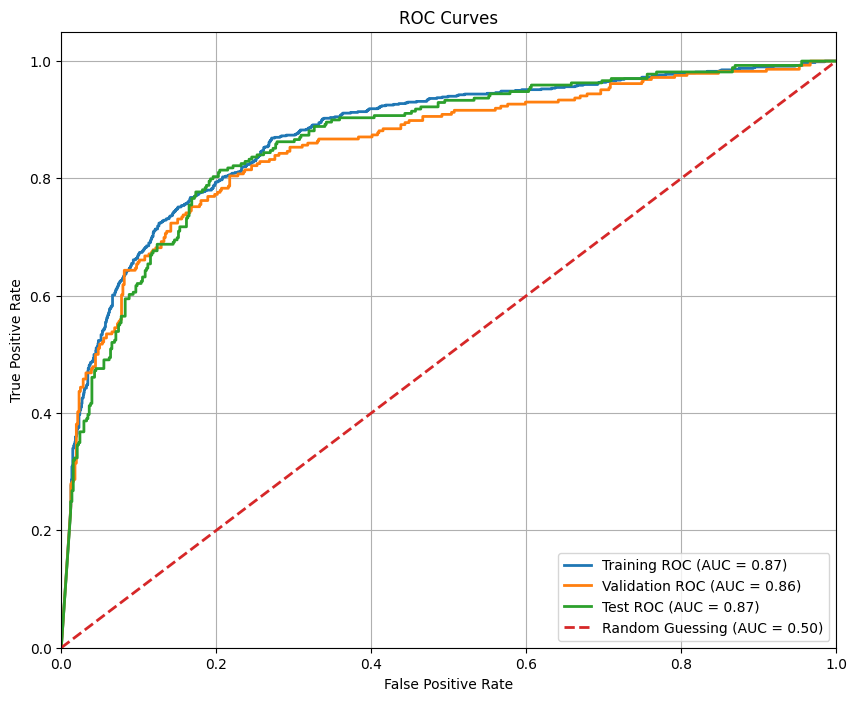


AUC Scores:
  Training AUC:   0.8742
  Validation AUC: 0.8558
  Test AUC:       0.8651


In [192]:
plot_roc_auc(
    y_train, y_val, y_test, y_train_proba_gnb, y_val_proba_gnb, y_test_proba_gnb
)

## Compare All Model Performance Statistics

In [193]:
results = pd.concat(
    [
        results_lm.assign(model="lm"),
        results_lm_significant.assign(model="lm_sig"),
        results_lm_significant_interact.assign(model="lm_sig_interact"),
        results_dt.assign(model="dt"),
        results_gbc.assign(model="gbc"),
        results_rf.assign(model="rf"),
        results_nn.assign(model="nn"),
        results_lda.assign(model="lda"),
        results_knn7.assign(model="knn7"),
        results_gnb.assign(model="gnb"),
    ],
    axis=0,
)

results = results.set_index("model")

display(results)

,Accuracy,Precision,Recall,F1 Score
model,,,,
lm,0.8900,0.8891,0.7412,0.8085
lm,0.8650,0.8490,0.7273,0.7834
lm,0.8766,0.8694,0.7175,0.7862
lm_sig,0.8892,0.8852,0.7425,0.8076
lm_sig,0.8603,0.8408,0.7203,0.7759
lm_sig,0.8696,0.8591,0.7026,0.7730
lm_sig_interact,0.8904,0.8869,0.7450,0.8098
lm_sig_interact,0.8603,0.8408,0.7203,0.7759
lm_sig_interact,0.8707,0.8597,0.7063,0.7755


In [194]:
# Average metric statistics on the Validation and Test sets only to show best model generalization on unseen data.
mask = np.arange(len(results)) % 3 != 0
filtered = results.iloc[mask]

results_avg = (
    filtered.groupby(filtered.index).mean().sort_values(by="Recall", ascending=False)
)

display(round(results_avg, 2))

,Accuracy,Precision,Recall,F1 Score
model,,,,
gnb,0.80,0.68,0.76,0.72
gbc,0.87,0.85,0.73,0.78
lm,0.87,0.86,0.72,0.78
lm_sig_interact,0.87,0.85,0.71,0.78
lm_sig,0.86,0.85,0.71,0.77
rf,0.86,0.86,0.70,0.77
lda,0.86,0.87,0.68,0.77
dt,0.86,0.88,0.67,0.76
knn7,0.84,0.87,0.58,0.70


In the context of this problem, since it's costly for a student to dropout we will look to maximize the Recall score. This allows us to capture the most dropouts who are actually dropouts. Offering interventions to a student who wouldn't drop out isn't harmful to our situation.

Averaging results across our validation, and test sets for each model type, the Gradient Boosting Classifier ends up with the best Recall score on average. As a benefit, this model also has the highest Accuracy and F1 Score with a close-to-highest Precision.

All models perform consistently across all 3 sets, so we are relatively confident there isn't overfitting on any one single model type.

# Interesting Trends Pointed Out By The Models

In [195]:
# Create a crosstab of the tuition fees up to date for the Target variable by percentage of total
round(
    pd.crosstab(df["Tuition fees up to date"], df["Target"], normalize="index") * 100, 2
)

Target,Dropout,Non-Dropout
Tuition fees up to date,,
no,86.55,13.45
yes,24.74,75.26


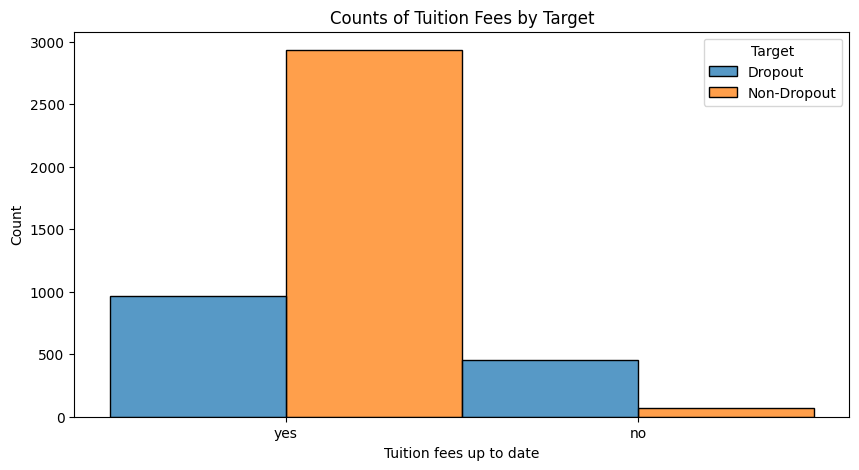

In [196]:
# Create a histogram of Tuition fees up to date grouped by our Target variable side by side
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Tuition fees up to date", hue="Target", multiple="dodge")

plt.title("Counts of Tuition Fees by Target")
plt.show()

The logistic regression pointed out a strong negative relationship between Tuition Fees being up to date and our target variable.

Of the students whos tuition fees were not up to date, 87% of them dropped out compared to 25% who did have their tuition fees up to date.

This variable remained significant in other models.

In [197]:
# Create a crosstab of our target variable for curricular units in the 2nd semster
round(
    pd.crosstab(
        df["Curricular units 2nd sem (approved)"], df["Target"], normalize="index"
    )
    * 100,
    2,
)

Target,Dropout,Non-Dropout
Curricular units 2nd sem (approved),,
0,83.56,16.44
1,75.44,24.56
2,58.59,41.41
3,44.56,55.44
4,27.05,72.95
5,16.39,83.61
6,6.63,93.37
7,5.74,94.26
8,6.23,93.77


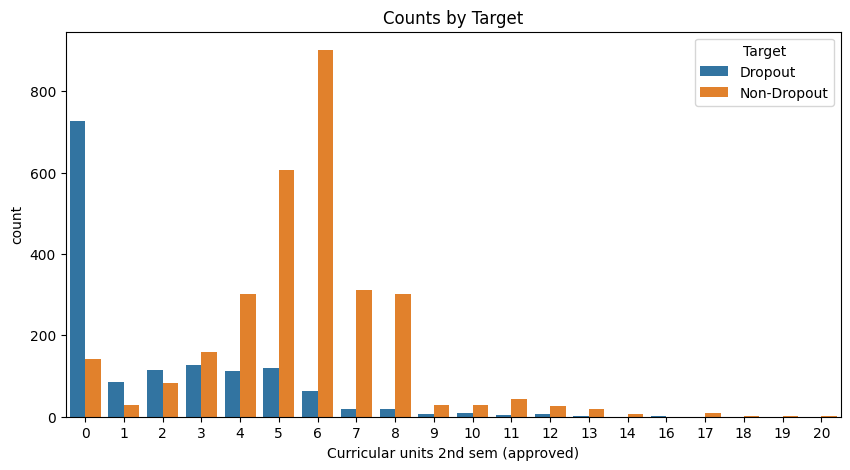

In [198]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Curricular units 2nd sem (approved)", hue="Target")
plt.title("Counts by Target")
plt.show()

In [199]:
round(
    pd.crosstab(
        df["Curricular units 2nd sem (enrolled)"], df["Target"], normalize="index"
    )
    * 100,
    2,
)

Target,Dropout,Non-Dropout
Curricular units 2nd sem (enrolled),,
0,42.78,57.22
1,100.00,0.00
2,100.00,0.00
3,66.67,33.33
4,82.35,17.65
5,43.07,56.93
6,31.47,68.53
7,32.57,67.43
8,14.37,85.63


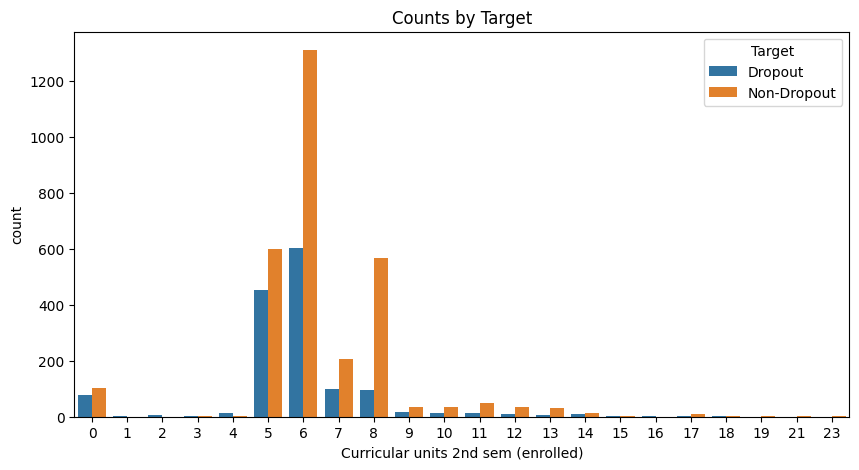

In [200]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Curricular units 2nd sem (enrolled)", hue="Target")
plt.title("Counts by Target")
plt.show()

The logistic regression pointed out a strong negative relationship between Curricular units in the 2nd semester (approved) and our target variable.

For lower quantities of units approved, a majority of our dropouts occur, whereas within higher units approved (closer to 6) dropouts become less prevalent and our non-dropout category peaks.

In [201]:
round(pd.crosstab(df["Age at enrollment"], df["Target"], normalize="index") * 100, 2)

Target,Dropout,Non-Dropout
Age at enrollment,,
17,0.00,100.00
18,19.50,80.50
19,22.72,77.28
20,22.20,77.80
21,28.88,71.12
22,33.33,66.67
23,37.96,62.04
24,42.75,57.25
25,50.54,49.46


At what age does dropout rate become significant?

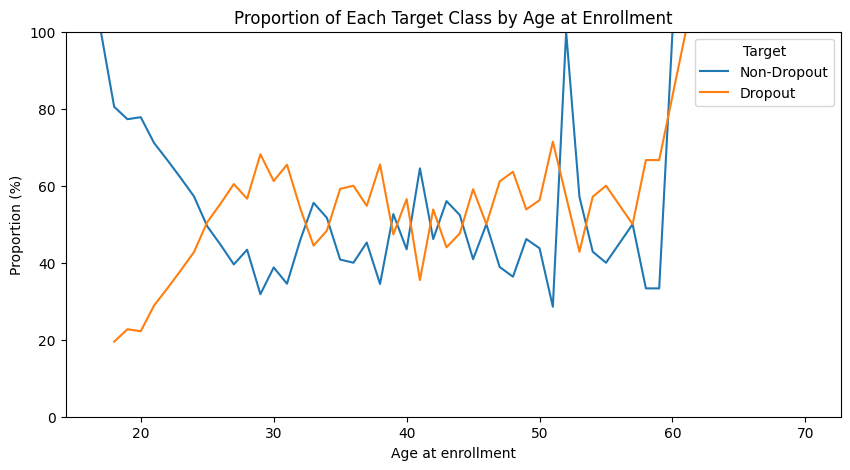

In [202]:
prop = (
    df.groupby("Age at enrollment")["Target"]
    .value_counts(normalize=True)
    .rename("Proportion")
    .reset_index()
)

prop["Proportion"] *= 100

plt.figure(figsize=(10, 5))
sns.lineplot(data=prop, x="Age at enrollment", y="Proportion", hue="Target")

plt.ylim(0, 100)
plt.title("Proportion of Each Target Class by Age at Enrollment")
plt.ylabel("Proportion (%)")
plt.xlabel("Age at enrollment")
plt.show()

For age, we see a shift in the proportion of dropouts increasing around age 25. Above that, the chances of dropping out are slightly higher with some fluctiation, but the majority we see dropping out. We can attribute the lower dropout rates around 31 - 33 and 41 - 43 as potentially being masters and doctoral students natural progression.

In [203]:
round(pd.crosstab(df["Course"], df["Target"], normalize="index") * 100, 2)

Target,Dropout,Non-Dropout
Course,,
"Biofuel, Equinculture, Informatics, Management (Evening)",53.13,46.87
"Education, Agronomy",42.54,57.46
"Oral Hygiene, Animation/Multimedia, Tourism, Marketing/Advertising, Management, Social Services (Evening), Journalism/Comm",35.03,64.97
"Vet Nursing, Communication Design, Social Service, Nursing",19.24,80.76


Since the models also identified certain Course types as being associated with negative effect on the target variable, one thing we can see is that 53% of Biofuel, Equineculture, Informatics and Management (Evening) courses dropped out. Education and Agronomy followed slightly after at 43%. A focus on programs or support for students in these majors might offer help on the dropout rate.

In [204]:
pd.set_option("display.max_rows", None)

df["Admission Grade Range"] = pd.cut(df["Admission grade"], bins=15)

round(
    pd.crosstab(df["Admission Grade Range"], df["Target"], normalize="index") * 100, 2
)

Target,Dropout,Non-Dropout
Admission Grade Range,,
"(94.905, 101.333]",51.83,48.17
"(101.333, 107.667]",49.34,50.66
"(107.667, 114.0]",37.69,62.31
"(114.0, 120.333]",35.36,64.64
"(120.333, 126.667]",25.42,74.58
"(126.667, 133.0]",30.84,69.16
"(133.0, 139.333]",26.08,73.92
"(139.333, 145.667]",30.85,69.15
"(145.667, 152.0]",27.07,72.93
